<div style="background-color: rgba(155, 89, 182, 0.15); border-left: 6px solid #9b59b6; padding: 15px; border-radius: 5px;"><h1 style="color: #9b59b6; margin: 0;">Detección de leucemia linfoblástica aguda (LLA) en células sanguíneas con redes convolucionales</h1>
</div>

**Deep Learning · Universidad de La Sabana**

<div style="background-color: rgba(155, 89, 182, 0.05); border: 2px solid #9b59b6; border-radius: 12px; padding: 25px; max-width: 500px; margin: 20px auto; box-shadow: 0 8px 16px rgba(155, 89, 182, 0.1); font-family: system-ui, -apple-system, sans-serif;">
    <div style="text-align: center; margin-bottom: 25px;">
        <img src="decoracion.gif" style="width: 280px; height: auto; border-radius: 12px; box-shadow: 0 6px 20px rgba(155, 89, 182, 0.5); border: 3px solid rgba(155, 89, 182, 0.8); background-color: #14141f; display: inline-block;">
    </div>
    <h2 style="color: #9b59b6; text-align: center; border-bottom: 2px dashed rgba(155, 89, 182, 0.5); padding-bottom: 10px; margin-top: 0;">Alumnos</h2>
    <ul style="list-style-type: none; padding: 0; margin: 20px 0 0 0; font-size: 16px; text-align: center; line-height: 1.8;">
        <li style="margin-top: 10px;">👻 <strong>Jesús Rafael Tapia Camargo</strong></li>
    </ul>
</div>

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
        Dataset
    </h3>
</div>
C-NMC 2019 (ISBI 2019 Challenge, The Cancer Imaging Archive)</td>
<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
        Tarea
    </h3>
</div>
Clasificación binaria: célula leucémica (<code>all</code>) vs. célula sana (<code>hem</code>)

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
        Framework
    </h3>
</div>
TensorFlow / Keras

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
        Contenido
    </h3>
</div>

1. Contexto clínico y problematica 
2. Configuración del entorno
3. Descarga e inventario de los datos
4. Análisis exploratorio (EDA)
5. Partición por paciente
6. Preprocesamiento, aumento de datos, desbalance y experimento de fuga de datos
7. Modelo 1: CNN propia
8. Modelo 2: EfficientNet-B0 con transfer learning
9. Experimentación con hiperparámetros
10. Evaluación 
11. Análisis de errores (Grad-CAM)
12. Robustez ante condiciones reales
13. Eficiencia, huella de carbono y exportación ligera
14. Conclusiones y propuestas de mejora
15. Implementación en un entorno real
16. Consideraciones éticas y prácticas
17. Extensión: sistema completo con YOLO y SAM 2 (frotis completos)
18. Mejoras del clasificador
19. Cambio de dominio: ¿cómo hacer que el modelo funcione en otro hospital?
20. Referencias

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        1. Contexto clínico y problemática
    </h2>

</div>

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
        1.1 ¿Qué es la leucemia linfoblástica aguda (LLA)?
    </h3>
</div>

La médula ósea fabrica todas las células de la sangre. En la LLA, un precursor de los linfocitos (el **linfoblasto**) sufre alteraciones genéticas, deja de madurar y se multiplica sin control. Los blastos invaden la médula y desplazan la producción normal, lo que causa:

| Lo que falta | Consecuencia | Síntoma típico |
|---|---|---|
| Glóbulos rojos | Anemia | Palidez, cansancio |
| Plaquetas | Trombocitopenia | Moretones, sangrado de encías o nariz |
| Glóbulos blancos funcionales | Defensas bajas | Fiebre e infecciones repetidas |
| (Infiltración de blastos) | Crecimiento de órganos | Dolor de huesos, ganglios inflamados, bazo o hígado grandes |

- Es **aguda** porque avanza en semanas; sin tratamiento es mortal en pocos meses.
- Según la célula de origen se divide en **LLA-B** (la gran mayoría en niños) y **LLA-T**. El dataset de este proyecto es de **LLA-B**.
- Es el **cáncer más frecuente de la infancia**: cerca del **25% de los cánceres pediátricos**, con mayor frecuencia entre los 2 y 5 años.
- **Es curable:** con diagnóstico temprano y tratamiento adecuado, la gran mayoría de los niños sobrevive en los países de ingresos altos.

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       1.2 ¿Cómo se diagnostica hoy?
    </h3>
</div>


| Paso | Qué se busca | Limitación |
|---|---|---|
| 1. Hemograma | Alteraciones en glóbulos rojos, blancos y plaquetas | Barato y rápido, pero **no es específico** |
| 2. **Frotis de sangre periférica** | Un experto revisa al microscopio si hay **blastos** | Depende de la experiencia de quien observa; es lento y subjetivo ← **aquí actúa este proyecto** |
| 3. Aspirado y biopsia de médula ósea | Confirmación: en general, **20% o más de blastos** | Invasivo; requiere especialista |
| 4. Citometría de flujo (inmunofenotipo) | Marcadores de superficie que distinguen LLA-B de LLA-T | Equipos costosos, solo en centros de referencia |
| 5. Citogenética y biología molecular | Alteraciones como el cromosoma Filadelfia o ETV6-RUNX1 | Define el riesgo y el tratamiento; muy especializado |

El frotis es el **primer momento en que alguien puede ver la enfermedad**. Si ese paso falla o se demora, todo lo demás se retrasa.


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       1.3 ¿Qué ve el hematólogo y por qué es difícil?
    </h3>
</div>

| Rasgo | Linfoblasto (LLA) | Linfocito maduro normal |
|---|---|---|
| Tamaño | Mayor | Pequeño |
| Cromatina del núcleo | Fina, dispersa, "lisa" | Condensada, en grumos |
| Nucléolos | Pueden verse | Ausentes |
| Contorno del núcleo | Puede ser irregular o hendido | Redondo y regular |

En el dataset las células sanas no son linfocitos maduros cualquiera, sino **hematogonas** precursores B *normales* e inmaduros que se parecen mucho a un blasto. Distinguirlas es difícil incluso para expertos, y por eso este problema es un buen reto para una CNN.


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       1.4 La problemática: el país donde nace un niño decide si sobrevive
    </h3>
</div>

| Indicador | Dato | Fuente |
|---|---|---|
| Cáncer infantil en el mundo | ~300.000 casos al año en menores de 19 años; ~80% en países de ingresos bajos y medios | UICC / OMS |
| Supervivencia a 5 años | ~80% en países de ingresos altos; en algunos países de ingresos bajos y medios no pasa del 30% | UICC / OMS |
| Meta de la OMS | Al menos **60%** de supervivencia global en 2030 (Iniciativa Global contra el Cáncer Infantil, 2018) | OMS |
| LLA infantil, comparación internacional (diagnósticos 2005–2009) | 92% en Alemania frente a 52% en Colombia, la cifra más baja del estudio | Bonaventure et al., *Lancet Haematology*, 2017 |
| Colombia | La LLA es ~26% de los cánceres en menores de 19 años; ~2.211 casos nuevos de cáncer infantil al año; supervivencia de LLA de 70–79% | OPS, 2023 |
| México | ~2.000 casos nuevos de cáncer infantil al año; la leucemia es ~50% de ellos; supervivencia de LLA de 40–60%, frente a más de 80% en países de ingresos altos | INSP, 2021 |

Las causas de la brecha son muchas (acceso al tratamiento, abandono, infecciones), pero el **diagnóstico tardío** es una de las más importantes. Los hematólogos y los laboratorios de referencia se concentran en las grandes ciudades. Un niño en una zona rural puede esperar días o semanas para que alguien con experiencia revise su frotis.

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       1.5 ¿A qué ayuda este sistema? (y a qué no)
    </h3>
</div>

**Ayuda a:**
- **Priorizar (triaje):** marca los frotis con células sospechosas para que se revisen primero y se remita al paciente de forma urgente.
- **Dar una segunda opinión** consistente, que no se cansa al final del turno.
- **Llevar el tamizaje donde no hay hematólogo:** un laboratorista captura la imagen, el modelo alerta y un especialista confirma a distancia por telemedicina.
- **Reducir la carga de trabajo:** el especialista se concentra en los casos dudosos.
- **Formar personal:** con Grad-CAM se puede mostrar qué rasgos de la célula llevan a la decisión.

**No hace (y no debe hacer):**
- Diagnosticar la leucemia: eso exige médula ósea, citometría de flujo y el criterio de un hematólogo.
- Clasificar subtipos (B/T, genéticos) ni definir el tratamiento.

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       1.6 ¿Cómo se aplicaría? Un caso de uso
    </h3>
</div>


> **Escenario.** Una niña de 4 años llega a un hospital municipal con palidez, moretones y fiebre de dos semanas. El hemograma sale alterado. No hay hematólogo en el municipio; el más cercano está a horas de distancia.
>
> 1. La bacterióloga prepara el frotis y toma fotos con una cámara acoplada al microscopio (o un celular con adaptador).
> 2. El software recorta cada leucocito y la CNN calcula la probabilidad de que cada uno sea un blasto.
> 3. Si la fracción de células sospechosas supera el umbral, el caso se marca como **prioridad alta**. Las imágenes y los mapas Grad-CAM se envían por telemedicina al hematólogo del centro de referencia.
> 4. El hematólogo revisa en minutos, confirma la sospecha y se activa la **remisión urgente** para el aspirado de médula y la citometría.
>
> **Resultado:** el sistema sirve como guia diagnostica, pero puede ahorrar días en el camino al diagnóstico.

**Usuarios:** bacteriólogos y laboratoristas (capturan las imágenes), hematólogos (confirman) y médicos generales (reciben la alerta y remiten).

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       1.7 Objetivo y preguntas del proyecto
    </h3>
</div>

**Objetivo general:** entrenar una CNN que clasifique imágenes de células individuales como leucémicas (`all`) o sanas (`hem`), y evaluar con honestidad si generaliza a **pacientes que nunca vio**.

**Preguntas:**
1. ¿Qué tan bien distingue una CNN un linfoblasto de una hematogona en pacientes nuevos?
2. ¿Supera el transfer learning a una CNN entrenada desde cero?
3. ¿Cuánto se sobreestima el rendimiento si se ignora la separación por paciente?
4. ¿En qué se fija el modelo, y es robusto a cambios de captura y tinción?


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       1.8 Justificación del dataset
    </h3>
</div>

| Dataset | Tamaño | Ventajas | Limitaciones | Decisión |
|---|---|---|---|---|
| **C-NMC 2019** (ISBI) | 15.135 células de 118 personas | Grande, curado por expertos, **identificador de paciente en cada imagen**, set de prueba con pacientes distintos | Desbalance ~2:1; células ya recortadas; un solo origen | **Elegido** |
| ALL-IDB2 | ~260 células recortadas | Balanceado | Demasiado pequeño para entrenar una CNN desde cero | Descartado |
| AML-Cytomorphology (LMU) | 18.365 células de 200 personas | Grande | Es leucemia **mieloide**, con etiquetas morfológicas multiclase | Descartado (otro problema clínico) |
| Datasets genéricos de leucocitos (p. ej. BCCD) | Cientos a pocos miles | Fáciles de usar | No incluyen células leucémicas | Descartado |

#### Por qué C-NMC y no otro
1. **Relevancia clínica:** es LLA-B, la leucemia infantil más común, y sus células sanas son hematogonas, el caso difícil que enfrenta el hematólogo en la vida real.
2. **Permite una evaluación honesta:** cada archivo trae el ID del paciente (`UID_57_…_all.bmp`, `UID_H49_…_hem.bmp`). Así podemos garantizar que **ningún paciente aparezca en entrenamiento y prueba a la vez**. Muchos trabajos publicados mezclan las particiones y dividen por imagen, y eso infla el rendimiento.
3. **Tiene un conjunto de prueba externo etiquetado:** la fase preliminar del reto (28 pacientes distintos a los de entrenamiento).


<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        2. Configuración del entorno
    </h2>

</div>

In [4]:
import importlib.util, subprocess, sys
# CodeCarbon mide energía y CO2 del entrenamiento (sección 13)
if importlib.util.find_spec("codecarbon") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "codecarbon"], check=False)

import os, re, gc, time, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
import keras
from keras import layers
from sklearn import metrics as skm
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.decomposition import PCA
from sklearn.calibration import calibration_curve
from scipy import stats

warnings.filterwarnings("ignore")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "no hay GPU (activa una en Colab)")
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)   # deja memoria de GPU libre para YOLO y SAM 2 (PyTorch)

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
# ======================= CONFIGURACIÓN =======================
FAST_MODE = False                 # True = prueba rápida (submuestra y pocas épocas)
DATA_DIR = "/content/data"        # carpeta donde se descarga el dataset
OUT_DIR = "/content/resultados"   # figuras, métricas y modelos
PRETRAINED_WEIGHTS = "imagenet"   # pesos de EfficientNet
COUNTRY_ISO = "COL"               # país para estimar CO2 (COL = Colombia, MEX = México)

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS_BASELINE = 25
EPOCHS_HEAD = 5          # EfficientNet: solo la cabeza
EPOCHS_FINETUNE = 15     # EfficientNet: ajuste fino de las últimas capas
EPOCHS_GRID = 6          # épocas por configuración en la búsqueda de hiperparámetros
EPOCHS_LEAK = 5          # épocas del experimento de fuga de datos
LEAK_IMG_SIZE = 128
VAL_FRACTION_SUBJECTS = 0.2
N_BOOTSTRAP = 1000
MAX_IMAGES_PER_CLASS = None

if FAST_MODE:
    IMG_SIZE, LEAK_IMG_SIZE = 96, 64
    EPOCHS_BASELINE = EPOCHS_HEAD = EPOCHS_FINETUNE = EPOCHS_GRID = EPOCHS_LEAK = 1
    MAX_IMAGES_PER_CLASS, N_BOOTSTRAP = 300, 100

os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed); keras.utils.set_random_seed(seed)
set_seed()

USE_MIXED_PRECISION = bool(tf.config.list_physical_devices("GPU"))
if USE_MIXED_PRECISION:
    keras.mixed_precision.set_global_policy("mixed_float16")  # ~2x más rápido en T4

CLASS_NAMES = ["hem (sana)", "all (leucemia)"]
PALETTE = {0: "#2a9d8f", 1: "#c0392b"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", bbox_inches="tight", dpi=150)


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
  3. Descarga e inventario de los datos  
  </h2>
</div>

Usamos la copia de C-NMC 2019 publicada en Kaggle (`andrewmvd/leukemia-classification`), que conserva la estructura original:

```
C-NMC_Leukemia/
├── training_data/fold_0|1|2/{all,hem}/UID_<paciente>_<...>_<clase>.bmp   ← 73 pacientes
├── validation_data/  imágenes de la fase preliminar + CSV de etiquetas      ← 28 pacientes
└── testing_data/     fase final (sin etiquetas públicas, no se usa)
```

In [6]:
def find_dataset_root(base):
    # Busca la carpeta que contiene training_data/fold_*
    for root, dirs, _ in os.walk(base):
        if any(d.startswith("fold_") for d in dirs):
            return Path(root).parent
    return None

def setup_kaggle():
    # Configura las credenciales de Kaggle sin escribirlas en el notebook
    kdir = Path.home() / ".kaggle"
    if os.environ.get("KAGGLE_API_TOKEN") or (kdir / "access_token").exists() or (kdir / "kaggle.json").exists():
        return
    token = None
    try:                                   # 1) Secreto de Colab llamado KAGGLE_API_TOKEN
        from google.colab import userdata
        token = userdata.get("KAGGLE_API_TOKEN")
    except Exception:
        pass
    if not token:                          # 2) Pedirlo en un cuadro oculto
        from getpass import getpass
        token = getpass("Pega tu token de Kaggle (KGAT_...) o deja vacío para subir kaggle.json: ").strip()
    if token:
        os.environ["KAGGLE_API_TOKEN"] = token
    else:                                  # 3) Credencial heredada kaggle.json
        from google.colab import files
        uploaded = files.upload()
        kdir.mkdir(exist_ok=True)
        (kdir / "kaggle.json").write_bytes(uploaded["kaggle.json"])
        os.chmod(kdir / "kaggle.json", 0o600)

if find_dataset_root(DATA_DIR) is None:
    os.makedirs(DATA_DIR, exist_ok=True)
    setup_kaggle()
    !pip install -q -U kaggle
    !kaggle datasets download -d andrewmvd/leukemia-classification -p {DATA_DIR} --unzip -q

DATASET_ROOT = find_dataset_root(DATA_DIR)
print("Dataset en:", DATASET_ROOT)

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/leukemia-classification
License(s): other
Dataset en: /content/data/C-NMC_Leukemia


In [ ]:
SUBJECT_RE = re.compile(r"UID_(H?\d+)_", re.IGNORECASE)

def subject_from_name(name):
    # 'UID_57_29_1_all.bmp' -> '57' ; 'UID_H49_35_1_hem.bmp' -> 'H49'
    m = SUBJECT_RE.search(str(name))
    return m.group(1).upper() if m else None

def build_train_index(root):
    rows = []
    for fold_dir in sorted(p for p in Path(root).rglob("fold_*") if p.is_dir()):
        for cls_name, label in [("hem", 0), ("all", 1)]:
            for p in sorted((fold_dir / cls_name).glob("*.bmp")):
                rows.append({"path": str(p), "file": p.name, "label": label,
                             "subject": subject_from_name(p.name), "fold": fold_dir.name})
    return pd.DataFrame(rows)

def build_prelim_index(root):
    prelim_imgs = {p.name: str(p) for p in Path(root).rglob("*.bmp") if "prelim" in str(p).lower()}
    for csv in Path(root).rglob("*.csv"):
        df = pd.read_csv(csv)
        cols = {c.lower(): c for c in df.columns}
        if {"new_names", "labels"} <= set(cols):
            lookup = prelim_imgs or {p.name: str(p) for p in csv.parent.rglob("*.bmp")}
            out = pd.DataFrame({
                "file": df[cols["new_names"]].astype(str),
                "label": df[cols["labels"]].astype(int),
                "subject": df[cols.get("patient_id", df.columns[0])].map(subject_from_name),
            })
            out["path"] = out["file"].map(lookup)
            out["fold"] = "prueba_externa"
            return out.dropna(subset=["path"]).reset_index(drop=True)
    raise FileNotFoundError("No encontré el CSV de etiquetas de la fase preliminar")

def subsample(df, n):
    idx = []
    for _, g in df.groupby("label"):
        idx += list(g.sample(min(len(g), n), random_state=SEED).index)
    return df.loc[idx].reset_index(drop=True)

train_df = build_train_index(DATASET_ROOT)
test_df = build_prelim_index(DATASET_ROOT)
if MAX_IMAGES_PER_CLASS:
    train_df = subsample(train_df, MAX_IMAGES_PER_CLASS)
    test_df = subsample(test_df, MAX_IMAGES_PER_CLASS // 2)

assert train_df.subject.notna().all() and test_df.subject.notna().all(), "Hay imágenes sin ID de paciente"
print(f"Entrenamiento: {len(train_df):,} células de {train_df.subject.nunique()} pacientes")
print(f"Prueba externa: {len(test_df):,} células de {test_df.subject.nunique()} pacientes")
print("Pacientes compartidos entre entrenamiento y prueba:", len(set(train_df.subject) & set(test_df.subject)))
train_df.head()

Entrenamiento: 10,661 células de 73 pacientes
Prueba externa: 1,867 células de 28 pacientes
Pacientes compartidos entre entrenamiento y prueba: 0


,path,file,label,subject,fold
0,/content/data/C-NMC_Leukemia/training_data/fol...,UID_H11_10_1_hem.bmp,0,H11,fold_0
1,/content/data/C-NMC_Leukemia/training_data/fol...,UID_H11_10_2_hem.bmp,0,H11,fold_0
2,/content/data/C-NMC_Leukemia/training_data/fol...,UID_H11_10_3_hem.bmp,0,H11,fold_0
3,/content/data/C-NMC_Leukemia/training_data/fol...,UID_H11_11_1_hem.bmp,0,H11,fold_0
4,/content/data/C-NMC_Leukemia/training_data/fol...,UID_H11_11_2_hem.bmp,0,H11,fold_0


<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        4. Análisis exploratorio (EDA)
    </h2>
</div>

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       4.1 Distribución de clases y de pacientes
    </h3>
</div>

celulas  pacientes
split          label                             
Entrenamiento  hem (sana)         3389         26
               all (leucemia)     7272         47
Prueba externa hem (sana)          648         15
               all (leucemia)     1219         13

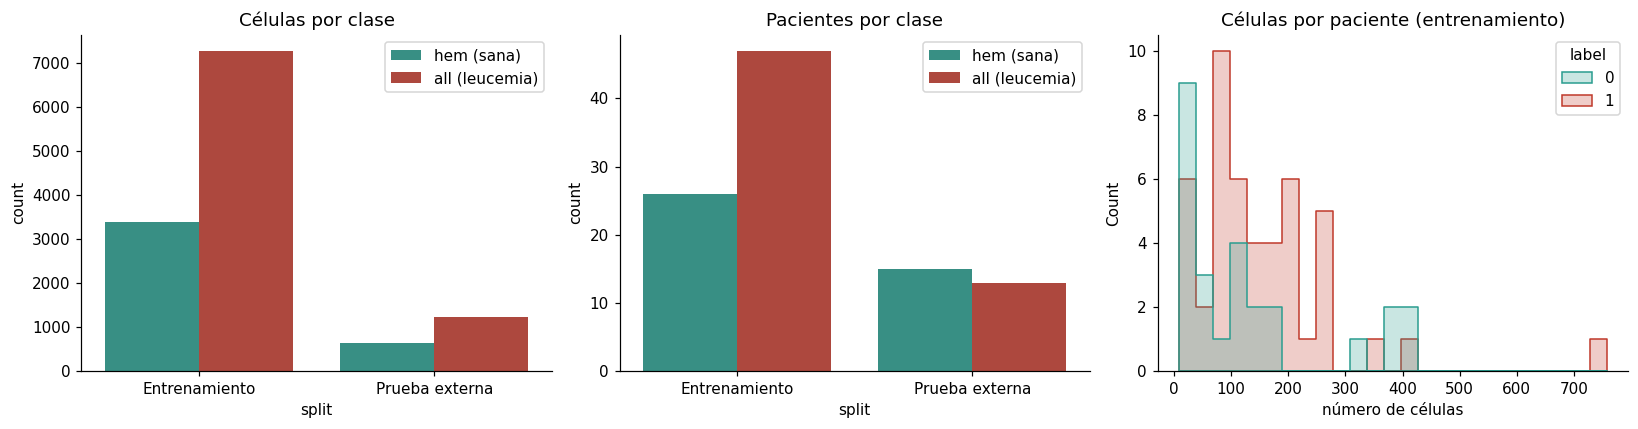

Desbalance en entrenamiento: 2.15 células leucémicas por cada célula sana


In [8]:
both = pd.concat([train_df.assign(split="Entrenamiento"), test_df.assign(split="Prueba externa")])
summary = (both.groupby(["split", "label"])
               .agg(celulas=("path", "size"), pacientes=("subject", "nunique"))
               .rename(index={0: CLASS_NAMES[0], 1: CLASS_NAMES[1]}, level=1))
display(summary)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=both, x="split", hue="label", palette=PALETTE, ax=ax[0])
ax[0].set_title("Células por clase"); ax[0].legend(CLASS_NAMES)
subj = both.groupby(["split", "subject"]).agg(label=("label", "first"), n=("path", "size")).reset_index()
sns.countplot(data=subj, x="split", hue="label", palette=PALETTE, ax=ax[1])
ax[1].set_title("Pacientes por clase"); ax[1].legend(CLASS_NAMES)
sns.histplot(data=subj[subj.split == "Entrenamiento"], x="n", hue="label", palette=PALETTE,
             bins=25, ax=ax[2], element="step")
ax[2].set_title("Células por paciente (entrenamiento)"); ax[2].set_xlabel("número de células")
plt.tight_layout(); savefig("eda_distribucion"); plt.show()

ratio = (train_df.label == 1).sum() / max((train_df.label == 0).sum(), 1)
print(f"Desbalance en entrenamiento: {ratio:.2f} células leucémicas por cada célula sana")

**Observaciones:**
- Hay aproximadamente **dos células leucémicas por cada sana**. Un modelo que diga siempre "leucemia" ya tendría ~67% de exactitud, así que la exactitud sola **no sirve** como métrica.
- El número de células por paciente varía mucho. Un paciente con cientos de células pesa más en el entrenamiento que uno con pocas; por eso también evaluamos **a nivel de paciente** (sección 10).
- Cada paciente pertenece a una sola clase: todas sus células son `all` o todas son `hem`.

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
        4.2 Ejemplos de cada clase
    </h3>
</div>

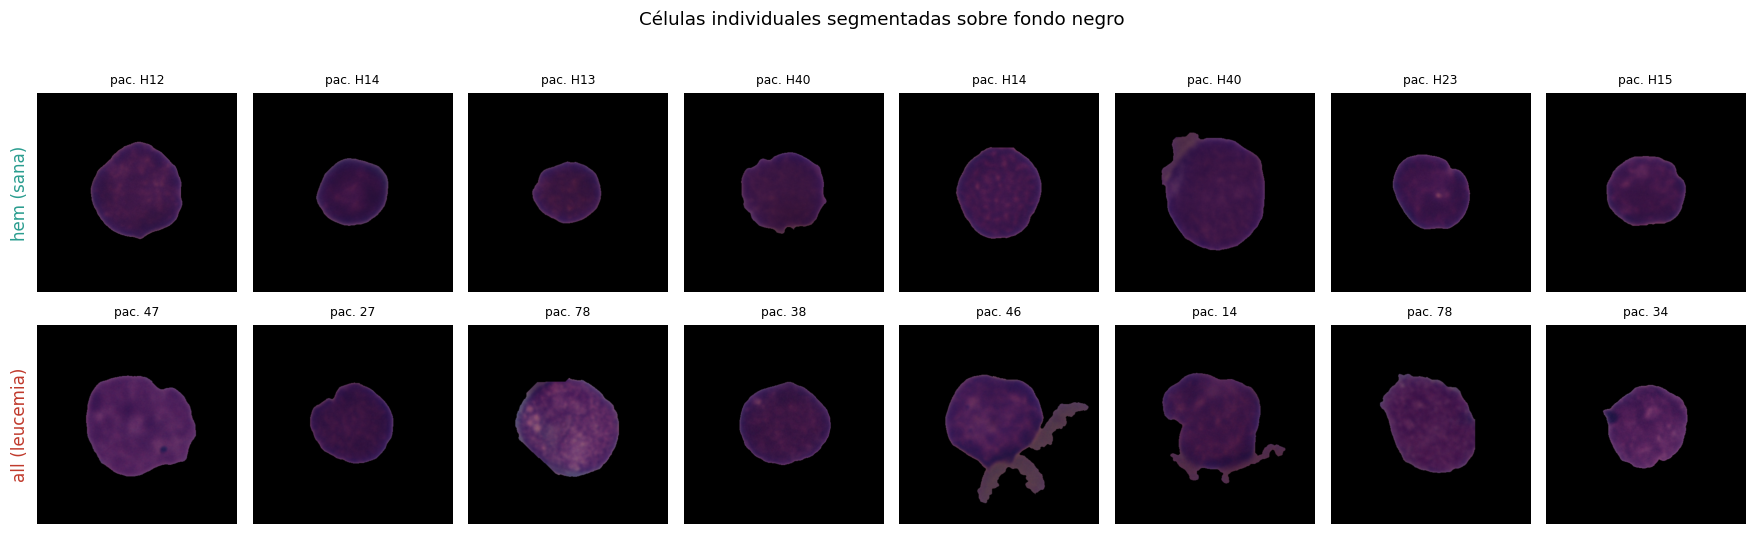

In [9]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.9))
for row, label in enumerate([0, 1]):
    sample = train_df[train_df.label == label].sample(8, random_state=SEED)
    for ax, (_, r) in zip(axes[row], sample.iterrows()):
        ax.imshow(Image.open(r.path).convert("RGB")); ax.axis("off")
        ax.set_title(f"pac. {r.subject}", fontsize=8)
    axes[row, 0].text(-60, 225, CLASS_NAMES[label], rotation=90, va="center", fontsize=11, color=PALETTE[label])
plt.suptitle("Células individuales segmentadas sobre fondo negro", y=1.02)
plt.tight_layout(); savefig("eda_ejemplos"); plt.show()

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       4.3 Morfología y color: ¿qué distingue a las clases?
    </h3>
</div>

Medimos sobre una muestra: tamaño de la imagen, **área de la célula** (píxeles no negros) y color medio dentro de la célula. Las células con área atípica suelen ser **errores de segmentación** del dataset original (célula cortada o con fondo de más).

Tamaños de imagen encontrados: {(450, 450): 800}


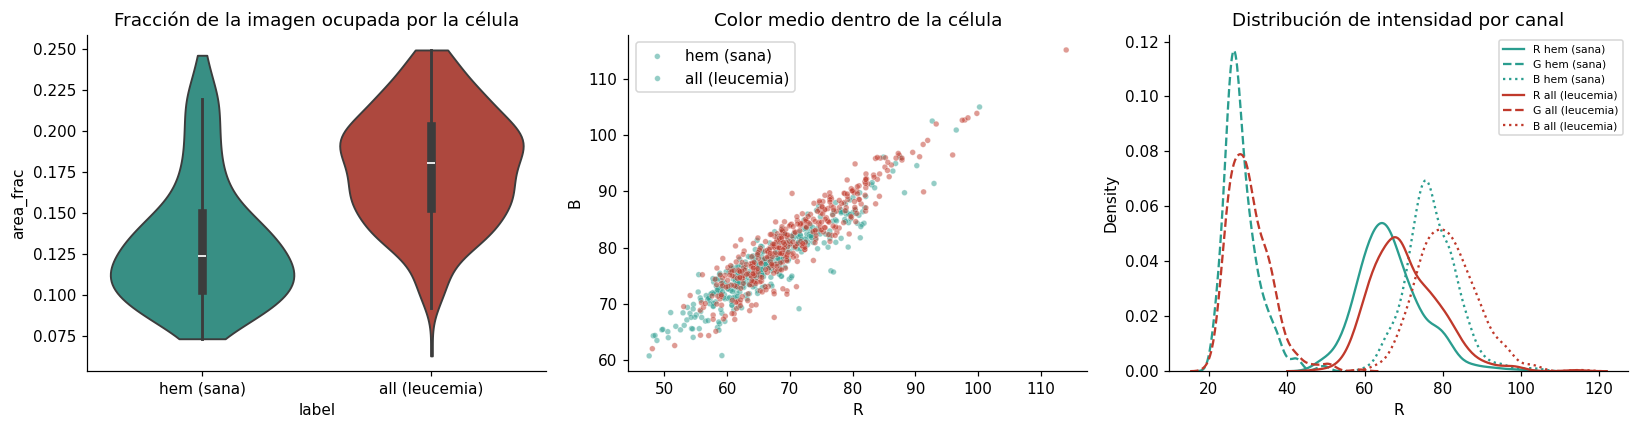

Área: mediana all=0.180 vs hem=0.124 (Mann-Whitney p=7.40e-54)


In [10]:
def cell_stats(path):
    img = np.asarray(Image.open(path).convert("RGB")).astype(np.float32)
    mask = img.sum(axis=2) > 30           # píxeles que pertenecen a la célula
    px = img[mask] if mask.any() else img.reshape(-1, 3)
    return {"alto": img.shape[0], "ancho": img.shape[1], "area_frac": mask.mean(),
            "R": px[:, 0].mean(), "G": px[:, 1].mean(), "B": px[:, 2].mean()}

eda_sample = train_df.groupby("label", group_keys=False).sample(n=min(400, train_df.label.value_counts().min()),
                                                                 random_state=SEED)
props = pd.concat([eda_sample.reset_index(drop=True),
                   pd.DataFrame([cell_stats(p) for p in eda_sample.path])], axis=1)
print("Tamaños de imagen encontrados:", props.groupby(["alto", "ancho"]).size().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.violinplot(data=props, x="label", y="area_frac", hue="label", palette=PALETTE, legend=False, ax=ax[0], cut=0)
ax[0].set_xticklabels(CLASS_NAMES); ax[0].set_title("Fracción de la imagen ocupada por la célula")
sns.scatterplot(data=props, x="R", y="B", hue="label", palette=PALETTE, alpha=.5, s=14, ax=ax[1])
ax[1].set_title("Color medio dentro de la célula"); ax[1].legend(CLASS_NAMES)
for lab in [0, 1]:
    for ch, ls in zip("RGB", ["-", "--", ":"]):
        sns.kdeplot(props[props.label == lab][ch], ax=ax[2], color=PALETTE[lab], ls=ls, label=f"{ch} {CLASS_NAMES[lab]}")
ax[2].set_title("Distribución de intensidad por canal"); ax[2].legend(fontsize=7)
plt.tight_layout(); savefig("eda_morfologia"); plt.show()

d = stats.mannwhitneyu(props[props.label == 1].area_frac, props[props.label == 0].area_frac)
print(f"Área: mediana all={props[props.label==1].area_frac.median():.3f} vs hem={props[props.label==0].area_frac.median():.3f}"
      f" (Mann-Whitney p={d.pvalue:.2e})")

In [11]:
# Anomalías: áreas fuera del rango intercuartílico (posibles errores de segmentación)
q1, q3 = props.area_frac.quantile([.25, .75]); iqr = q3 - q1
props["anomala"] = (props.area_frac < q1 - 1.5 * iqr) | (props.area_frac > q3 + 1.5 * iqr)
print(f"Células con área atípica: {props.anomala.sum()} de {len(props)} ({props.anomala.mean():.1%})")
anom = props[props.anomala].sort_values("area_frac").head(8)
if len(anom):
    fig, axes = plt.subplots(1, len(anom), figsize=(2 * len(anom), 2.4))
    for ax, (_, r) in zip(np.atleast_1d(axes), anom.iterrows()):
        ax.imshow(Image.open(r.path).convert("RGB")); ax.axis("off")
        ax.set_title(f"{CLASS_NAMES[r.label].split()[0]} · {r.area_frac:.2f}", fontsize=8)
    plt.suptitle("Ejemplos de células atípicas"); plt.tight_layout(); savefig("eda_anomalias"); plt.show()

Células con área atípica: 0 de 800 (0.0%)


**Decisión sobre las anomalías:** no las eliminamos. En un laboratorio real el segmentador también se equivocará, y queremos que el modelo sea robusto a eso. En la sección 11 revisamos si los errores del modelo se concentran en estas células.

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       4.4 ¿Las imágenes se agrupan por paciente?
    </h3>
</div>

Proyectamos miniaturas de las células con PCA. Si las células de un mismo paciente quedan juntas, una partición aleatoria por imagen dejaría que el modelo "reconozca al paciente" en lugar de la enfermedad.

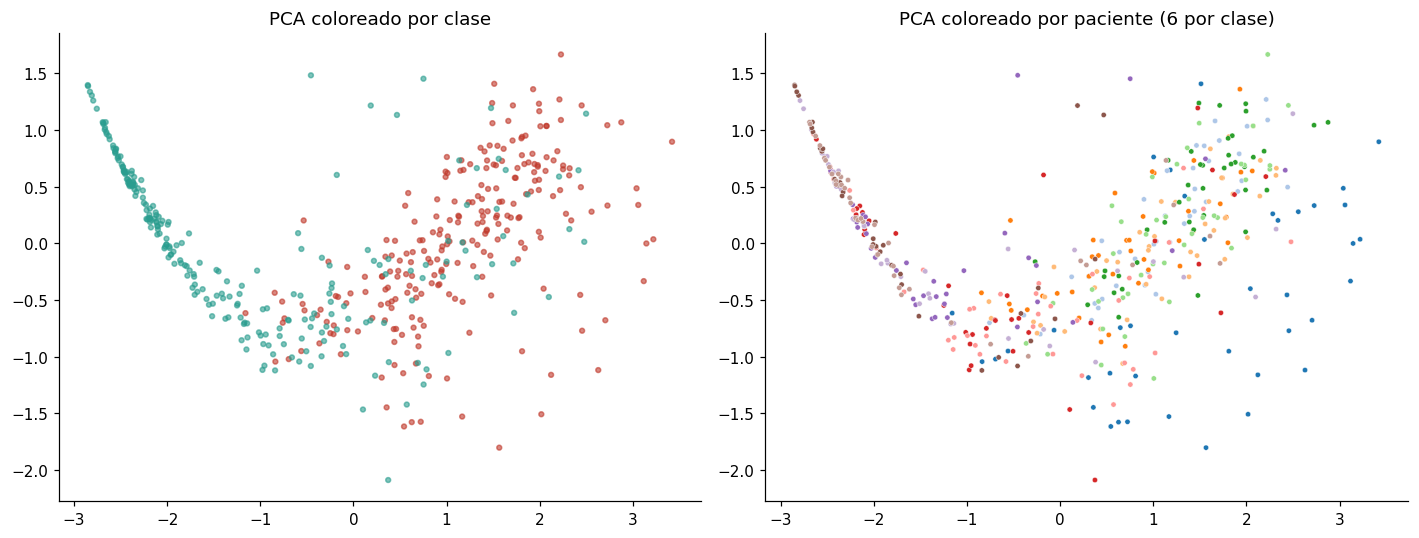

Silueta por paciente: -0.177 | silueta por clase: 0.366


In [12]:
idx = [i for _, g in train_df.groupby("subject") for i in g.sample(min(len(g), 40), random_state=SEED).index]
pca_df = train_df.loc[idx]
top_subjects = [s for lab in [0, 1] for s in pca_df[pca_df.label == lab].subject.value_counts().index[:6]]
pca_df = pca_df[pca_df.subject.isin(top_subjects)].reset_index(drop=True)
thumbs = np.stack([np.asarray(Image.open(p).convert("RGB").resize((32, 32))).ravel() / 255. for p in pca_df.path])
emb = PCA(n_components=2, random_state=SEED).fit_transform(thumbs)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(emb[:, 0], emb[:, 1], c=pca_df.label.map(PALETTE), s=10, alpha=.6)
ax[0].set_title("PCA coloreado por clase")
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=pca_df.subject, palette="tab20", s=12, ax=ax[1], legend=False)
ax[1].set_title("PCA coloreado por paciente (6 por clase)")
plt.tight_layout(); savefig("eda_pca_pacientes"); plt.show()

from sklearn.metrics import silhouette_score
print("Silueta por paciente:", round(silhouette_score(emb, pca_df.subject), 3),
      "| silueta por clase:", round(silhouette_score(emb, pca_df.label), 3))

Si la silueta por paciente es comparable o mayor que la silueta por clase, las células de un mismo paciente comparten rasgos (tinción, iluminación, captura) que **no son la enfermedad**. Eso justifica la partición por paciente de la siguiente sección.

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        5. Partición por paciente
    </h2>
</div>

- **Entrenamiento / validación:** dividimos los 73 pacientes de entrenamiento con `StratifiedGroupKFold` (≈80% / 20% de pacientes, manteniendo la proporción de clases).
- **Prueba externa:** los 28 pacientes de la fase preliminar. **No se usa para ninguna decisión** (ni umbrales ni hiperparámetros) hasta la sección 10.

In [ ]:
sgkf = StratifiedGroupKFold(n_splits=int(round(1 / VAL_FRACTION_SUBJECTS)), shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(train_df, train_df.label, groups=train_df.subject))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)

s_tr, s_va, s_te = set(tr_df.subject), set(va_df.subject), set(test_df.subject)
assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), "¡Un paciente aparece en dos particiones!"

split_table = pd.DataFrame({
    name: {"pacientes": d.subject.nunique(), "células": len(d),
           "% leucemia": f"{d.label.mean():.1%}",
           "pacientes all/hem": f"{d[d.label==1].subject.nunique()}/{d[d.label==0].subject.nunique()}"}
    for name, d in [("Entrenamiento", tr_df), ("Validación", va_df), ("Prueba externa", test_df)]}).T
display(split_table)
print("Ningún paciente se repite entre particiones")

,pacientes,células,% leucemia,pacientes all/hem
Entrenamiento,60,8726,66.7%,38/22
Validación,13,1935,75.1%,9/4
Prueba externa,28,1867,65.3%,13/15


✔ Ningún paciente se repite entre particiones


<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        6. Preprocesamiento, aumento de datos y desbalance
    </h2>
</div>

| Paso | Qué hace | Por qué |
|---|---|---|
| Lectura BMP a RGB | Decodifica las imágenes de 450×450 | Formato original |
| Redimensionar a `IMG_SIZE` | 224×224 por defecto | Tamaño nativo de EfficientNet-B0; reduce cómputo |
| Caché en `uint8` | Guarda las imágenes ya redimensionadas en memoria | Las épocas siguientes no vuelven a leer disco |
| Volteos horizontal y vertical | | Una célula no tiene "arriba" ni "abajo" |
| Rotación de 0 a 360° | Relleno negro | Igual que el fondo original |
| Zoom ±10% | | Variación de aumento del microscopio |
| Contraste ±15%, brillo ±10% | | Variación de iluminación |
| Tono ±3%, saturación ±15% | | Simula diferencias de **tinción entre laboratorios** |
| Pesos de clase | La clase sana pesa más en la pérdida | Compensa el desbalance 2:1 sin descartar datos |

El aumento solo se aplica en entrenamiento. La normalización de píxeles va **dentro de cada modelo** (EfficientNet espera valores 0–255; la CNN propia reescala a 0–1).

Pesos de clase: {'hem (sana)': 1.5, 'all (leucemia)': 0.75}


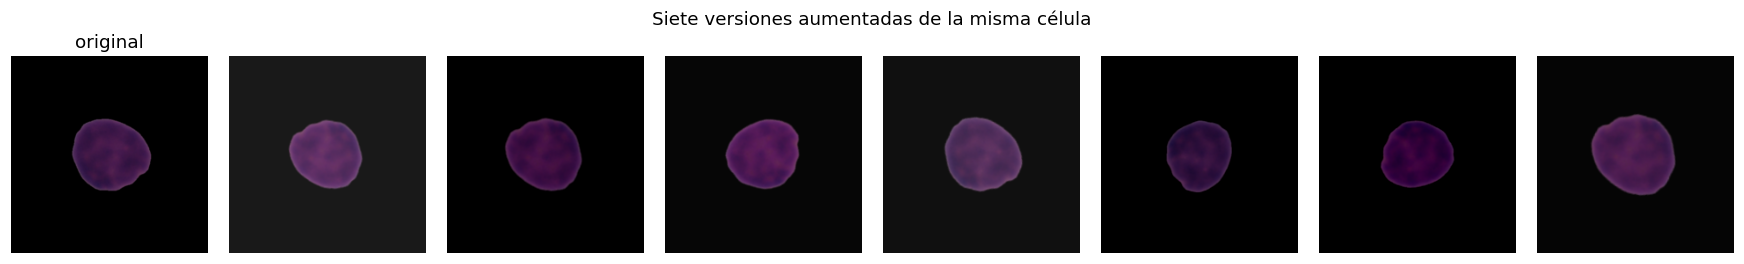

In [14]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, img_size):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (img_size, img_size), antialias=True)
    return tf.cast(tf.clip_by_value(img, 0, 255), tf.uint8)

def color_jitter(img):
    img = tf.image.random_hue(img / 255.0, 0.03)
    img = tf.image.random_saturation(img, 0.85, 1.15)
    return tf.clip_by_value(img, 0.0, 1.0) * 255.0

augmenter = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.5, fill_mode="constant", fill_value=0.0),
    layers.RandomZoom((-0.1, 0.1), fill_mode="constant", fill_value=0.0),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.1, value_range=(0, 255)),
], name="aumento")

def make_dataset(df, training=False, img_size=None, batch_size=BATCH_SIZE):
    img_size = img_size or IMG_SIZE
    ds = tf.data.Dataset.from_tensor_slices((df.path.values, df.label.values.astype("float32")))
    ds = ds.map(lambda p, y: (load_image(p, img_size), y), num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda x, y: (color_jitter(tf.cast(x, tf.float32)), y), num_parallel_calls=AUTOTUNE)
        ds = ds.batch(batch_size)
        ds = ds.map(lambda x, y: (augmenter(x, training=True), y), num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.batch(batch_size).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

def class_weights(df):
    n, n_pos = len(df), int(df.label.sum())
    return {0: n / (2 * (n - n_pos)), 1: n / (2 * n_pos)}

CLASS_WEIGHT = class_weights(tr_df)
print("Pesos de clase:", {CLASS_NAMES[k]: round(v, 3) for k, v in CLASS_WEIGHT.items()})

# Visualización del aumento de datos
demo = load_image(tr_df.path.iloc[0], IMG_SIZE)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(demo.numpy()); axes[0].set_title("original"); axes[0].axis("off")
for ax in axes[1:]:
    aug = augmenter(color_jitter(tf.cast(demo, tf.float32))[None], training=True)[0]
    ax.imshow(np.clip(aug.numpy(), 0, 255).astype("uint8")); ax.axis("off")
plt.suptitle("Siete versiones aumentadas de la misma célula"); plt.tight_layout(); savefig("aumento"); plt.show()

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       6.1 Experimento: ¿cuánto infla la fuga de datos el resultado?
    </h3>
</div>

Entrenamos la misma CNN pequeña dos veces, cambiando solo cómo se separa la validación:
1. **Aleatoria por imagen** (lo que hacen muchos trabajos y el ejemplo de tumores cerebrales): las células de un mismo paciente quedan a ambos lados.
2. **Por paciente** (nuestra partición).

Las dos se evalúan además en la prueba externa. Si la validación aleatoria da un número mucho más alto que la prueba externa, está midiendo memoria del paciente, no capacidad diagnóstica.

,AUC validación,AUC prueba externa,brecha (val − prueba)
partición,,,
Aleatoria por imagen (con fuga),0.839,0.529,0.310
Por paciente (sin fuga),0.753,0.529,0.224


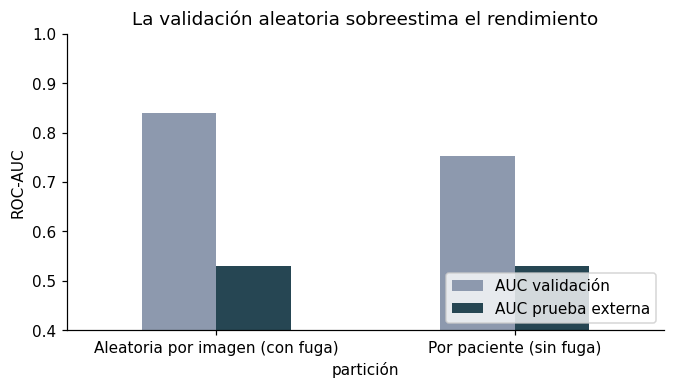

In [15]:
def compile_metrics():
    return [keras.metrics.BinaryAccuracy(name="acc"), keras.metrics.AUC(name="auc"),
            keras.metrics.AUC(curve="PR", name="pr_auc"),
            keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")]

def tiny_cnn(img_size):
    inp = keras.Input((img_size, img_size, 3))
    x = layers.Rescaling(1 / 255.)(inp)
    for f in [32, 64, 128]:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    out = layers.Dense(1, activation="sigmoid", dtype="float32")(x)
    m = keras.Model(inp, out)
    m.compile(keras.optimizers.Adam(1e-3), "binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    return m

rnd_tr, rnd_va = train_test_split(train_df, test_size=VAL_FRACTION_SUBJECTS, stratify=train_df.label, random_state=SEED)
leak_test_ds = make_dataset(test_df, img_size=LEAK_IMG_SIZE)
leak_rows = []
for name, (a, b) in {"Aleatoria por imagen (con fuga)": (rnd_tr, rnd_va),
                     "Por paciente (sin fuga)": (tr_df, va_df)}.items():
    set_seed()
    m = tiny_cnn(LEAK_IMG_SIZE)
    m.fit(make_dataset(a, True, LEAK_IMG_SIZE), epochs=EPOCHS_LEAK, class_weight=class_weights(a), verbose=0)
    leak_rows.append({"partición": name,
                      "AUC validación": m.evaluate(make_dataset(b, img_size=LEAK_IMG_SIZE), verbose=0)[1],
                      "AUC prueba externa": m.evaluate(leak_test_ds, verbose=0)[1]})
    del m; gc.collect()

leak = pd.DataFrame(leak_rows).set_index("partición")
leak["brecha (val − prueba)"] = leak["AUC validación"] - leak["AUC prueba externa"]
display(leak.round(3))
leak[["AUC validación", "AUC prueba externa"]].plot.bar(figsize=(7, 3.5), rot=0, color=["#8d99ae", "#264653"])
plt.ylim(0.4, 1); plt.ylabel("ROC-AUC"); plt.title("La validación aleatoria sobreestima el rendimiento")
plt.legend(loc="lower right"); savefig("fuga_datos"); plt.show()

**Interpretación:** la brecha entre validación y prueba externa mide cuánto se engaña uno al validar. Con la partición por paciente la validación es un estimador honesto de lo que pasará con pacientes nuevos. Desde aquí, **todas las decisiones se toman con la validación por paciente**.

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        7. Modelo 1: CNN propia (línea base)
    </h2>
</div>

Arquitectura VGG compacta: cuatro bloques convolucionales con normalización por lotes y dropout creciente.

| Capa | Configuración | Justificación |
|---|---|---|
| `Rescaling` | ÷255 | Lleva los píxeles a [0, 1] para estabilizar el gradiente |
| Bloque 1 | 2× Conv 3×3 (32) + BN + ReLU, MaxPool, Dropout 0.10 | Bordes y textura de la membrana |
| Bloque 2 | 2× Conv 3×3 (64) + BN + ReLU, MaxPool, Dropout 0.15 | Forma del núcleo |
| Bloque 3 | 2× Conv 3×3 (128) + BN + ReLU, MaxPool, Dropout 0.20 | Cromatina y nucléolos, relación núcleo/citoplasma |
| `last_conv` | Conv 3×3 (256) + BN + ReLU | Mapa de características de alto nivel (lo usa Grad-CAM) |
| `GlobalAveragePooling` | | Mucho menos parámetros que `Flatten` y es invariante a la posición |
| Densa 128 + Dropout 0.4 | ReLU | Combina rasgos; el dropout reduce el sobreajuste |
| Salida | 1 neurona sigmoide | Probabilidad de leucemia (clasificación binaria) |

- Dos convoluciones 3×3 seguidas ven lo mismo que una 5×5, pero con menos parámetros y una no linealidad extra.
- BatchNorm permite tasas de aprendizaje más altas y regulariza.
- Optimizador **AdamW** (Adam con decaimiento de pesos desacoplado).

In [16]:
def conv_block(x, filters, drop, name):
    for i in (1, 2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv{i}")(x)
        x = layers.BatchNormalization(name=f"{name}_bn{i}")(x)
        x = layers.Activation("relu", name=f"{name}_relu{i}")(x)
    x = layers.MaxPooling2D(name=f"{name}_pool")(x)
    return layers.Dropout(drop, name=f"{name}_drop")(x)

def build_baseline(img_size=None):
    img_size = img_size or IMG_SIZE
    inp = keras.Input((img_size, img_size, 3), name="imagen")
    x = layers.Rescaling(1 / 255.)(inp)
    x = conv_block(x, 32, 0.10, "b1")
    x = conv_block(x, 64, 0.15, "b2")
    x = conv_block(x, 128, 0.20, "b3")
    x = layers.Conv2D(256, 3, padding="same", use_bias=False, name="last_conv")(x)
    x = layers.BatchNormalization(name="last_bn")(x)
    x = layers.Activation("relu", name="last_conv_relu")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(128, activation="relu", name="densa")(x)
    x = layers.Dropout(0.4, name="drop_densa")(x)
    out = layers.Dense(1, activation="sigmoid", dtype="float32", name="pred")(x)
    return keras.Model(inp, out, name="cnn_base")

baseline = build_baseline()
baseline.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv1 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn1 (BatchNormalization)     │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu1 (Activation)           │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv2 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn2 (BatchNormalization)     │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu2 (Activation)           │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_pool (MaxPooling2D)          │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_drop (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn1 (BatchNormalization)     │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu1 (Activation)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv2 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn2 (BatchNormalization)     │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu2 (Activation)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_pool (MaxPooling2D)          │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_drop (Dropout)               │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_conv1 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_bn1 (BatchNormalization)     │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_relu1 (Activation)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_conv2 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_bn2 (BatchNormalization)     │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_relu2 (Activation)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_pool (MaxPooling2D)          │ (None, 28, 28, 128)    │             

 Total params: 617,313 (2.35 MB)

 Trainable params: 615,905 (2.35 MB)

 Non-trainable params: 1,408 (5.50 KB)

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       7.1 Diagrama de la arquitectura
    </h3>
</div>

Cada pila de cuadrados es un bloque convolucional: el tamaño del cuadrado representa la resolución espacial y el número de capas apiladas sugiere cuántos filtros tiene. Arriba va el tipo de capa y el número de filtros; abajo, las operaciones que siguen (BatchNorm, ReLU, MaxPool y Dropout). Al final, el *Global Average Pooling* resume cada canal en un número, una capa densa combina esos valores y una neurona sigmoide da la probabilidad de LLA.

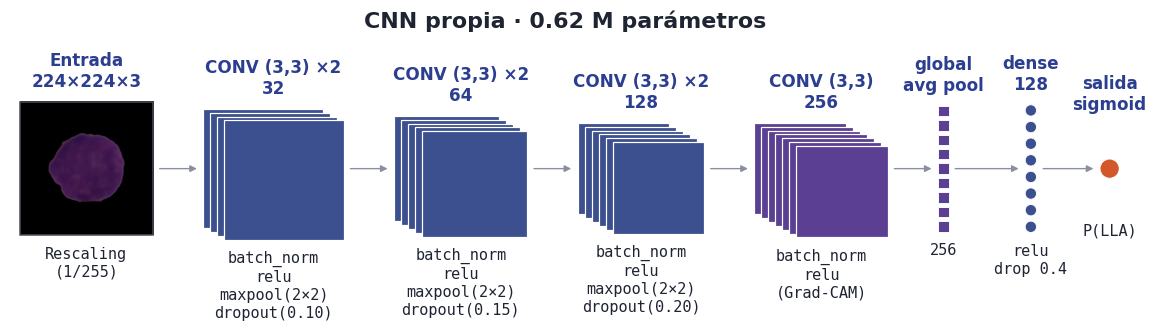

In [ ]:
from matplotlib.patches import Rectangle, Circle, FancyArrowPatch, FancyBboxPatch
from matplotlib.patches import Rectangle, Circle, FancyArrowPatch, FancyBboxPatch

# Paleta pastel con bordes oscuros, al estilo de los diagramas de ResNet y NN-SVG
OP_COLORS = {
    "input": "#E9ECF2", "pad": "#F4F4F4", "conv": "#CFE0F7", "bn": "#F7A35C", "act": "#F4D35E",
    "pool": "#8DB596", "mb1": "#B9D7EA", "mb3": "#9FC5E8", "mb5": "#A7B8E8", "se": "#E8A0BF",
    "dw": "#C3B1E1", "gap": "#F2B5B5", "flat": "#FBE7A1", "drop": "#D9D9D9", "dense": "#CDE8C5",
    "cnx": "#B5D8CC", "ln": "#F7C59F", "xc": "#BFD7B5", "down": "#E6C79C",
}
INK = "#1F2433"


def _arrow(ax, x0, x1, y, color="#2F80ED", w=0.10, head=0.22):
    ax.add_patch(FancyArrowPatch((x0, y), (x1, y), arrowstyle=f"simple,head_width={head * 4},head_length={head * 3},tail_width={w * 4}",
                                 mutation_scale=10, color=color, lw=0))


def draw_bars(ax, groups, title=None, bar_w=0.46, bar_h=2.9, gap_in=0.04, gap_out=0.34,
              in_label="Entrada", out_label="P(LLA)", fs=9.5, fs_group=9.5, fs_note=None, min_group_w=0.0, in_len=1.15):
    # Diagrama por bloques: cada operación es una barra vertical con su nombre en vertical.
    # groups = [(nombre_del_grupo, nota_debajo, [(texto, color), ...]), ...]
    x = in_len + 0.2
    ax.text(in_len / 2, bar_h / 2 + 0.3, in_label, ha="center", va="bottom", fontsize=fs + 1.5, color=INK)
    _arrow(ax, 0.0, in_len, bar_h / 2)
    prev_end = None
    for gi, (gname, note, ops) in enumerate(groups):
        w_ops = len(ops) * (bar_w + gap_in) - gap_in
        pad = max(0.0, (min_group_w - w_ops) / 2)
        x += pad
        x_start = x
        if prev_end is not None:
            ax.plot([prev_end, x], [bar_h / 2, bar_h / 2], ls=(0, (3, 2)), color="#555", lw=0.9)
        for text, color in ops:
            ax.add_patch(Rectangle((x, 0), bar_w, bar_h, facecolor=OP_COLORS.get(color, color), edgecolor="#4B4F5C", lw=0.9))
            ax.text(x + bar_w / 2, bar_h / 2, text, rotation=90, ha="center", va="center", fontsize=fs, color=INK,
                    fontweight="bold" if color not in ("pad", "drop") else "normal")
            x += bar_w + gap_in
        x_end = x - gap_in
        if gname:
            yb = -0.18
            ax.plot([x_start + 0.03, x_start + 0.03, x_end - 0.03, x_end - 0.03], [yb, yb - 0.16, yb - 0.16, yb], color="#333", lw=1)
            ax.text((x_start + x_end) / 2, yb - 0.3, gname, ha="center", va="top", fontsize=fs_group, color=INK)
            if note:
                ax.text((x_start + x_end) / 2, yb - 0.72, note, ha="center", va="top", fontsize=fs_note or fs_group - 1.5, color="#6A6F80")
        prev_end = x_end
        x = x_end + pad + gap_out
    x = x - gap_out + 0.2
    _arrow(ax, x, x + in_len, bar_h / 2)
    ax.text(x + in_len / 2, bar_h / 2 + 0.3, out_label, ha="center", va="bottom", fontsize=fs + 1.5, color=INK)
    x = x - 1.0 + in_len
    ax.set_xlim(-0.1, x + 1.2); ax.set_ylim(-1.55, bar_h + 0.95)
    ax.set_aspect("equal"); ax.axis("off")
    if title:
        ax.text((x + 2.2) / 2, bar_h + 0.75, title, ha="center", va="bottom", fontsize=fs + 3.5, color=INK, fontweight="bold")
    return ax


def draw_feature_maps(ax, blocks, title=None, input_img=None, fs=9.5):
    x = 0.0
    centers = []
    for b in blocks:
        k = b["kind"]
        if k in ("input", "conv"):
            s, n = b["size"], b.get("n", 1)
            off = 0.16
            for i in range(n):
                xi, yi = x + i * off, -s / 2 - i * off * 0.55
                if k == "input" and input_img is not None and i == n - 1:
                    ax.imshow(input_img, extent=(xi, xi + s, yi, yi + s), zorder=3 + i)
                    ax.add_patch(Rectangle((xi, yi), s, s, fill=False, edgecolor="#4B4F5C", lw=1, zorder=4 + i))
                else:
                    ax.add_patch(Rectangle((xi, yi), s, s, facecolor=b.get("color", "#3C4F8F"), edgecolor="white", lw=0.8, zorder=3 + i))
            w = s + (n - 1) * off
            top_y = s / 2 + 0.25
            bot_y = -s / 2 - (n - 1) * off * 0.55 - 0.25
        elif k == "gap":
            n = b.get("n", 8); s = 0.24; gap = 0.09
            h = n * s + (n - 1) * gap
            for i in range(n):
                ax.add_patch(Rectangle((x, h / 2 - (i + 1) * s - i * gap), s, s, facecolor=b.get("color", "#3C4F8F"), edgecolor="white", lw=0.6))
            w = s; top_y = h / 2 + 0.25; bot_y = -h / 2 - 0.25
        else:  # dense / out: neuronas como círculos
            n = b.get("n", 7); r = 0.13 if k == "dense" else 0.22; gap = 0.12
            h = n * 2 * r + (n - 1) * gap
            for i in range(n):
                ax.add_patch(Circle((x + r, h / 2 - r - i * (2 * r + gap)), r, facecolor=b.get("color", "#3C4F8F"), edgecolor="white", lw=0.6))
            w = 2 * r; top_y = h / 2 + 0.25; bot_y = -h / 2 - 0.25
        cx = x + w / 2
        centers.append((x, x + w))
        if b.get("top"):
            ax.text(cx, max(top_y, 1.25), b["top"], ha="center", va="bottom", fontsize=fs, color="#2C3E8F", fontweight="bold", linespacing=1.2)
        if b.get("bottom"):
            ax.text(cx, min(bot_y, -1.25), b["bottom"], ha="center", va="top", fontsize=fs - 1, color=INK, family="monospace", linespacing=1.25)
        x += w + b.get("gap_after", 0.75)
    for (a0, a1), (b0, b1) in zip(centers[:-1], centers[1:]):
        ax.add_patch(FancyArrowPatch((a1 + 0.08, 0), (b0 - 0.08, 0), arrowstyle="-|>", mutation_scale=9, color="#8A8FA0", lw=0.9, zorder=1))
    ax.set_xlim(-0.2, x - 0.4); ax.set_ylim(-3.3, 3.0)
    ax.set_aspect("equal"); ax.axis("off")
    if title:
        ax.set_title(title, fontsize=fs + 3.5, color=INK, fontweight="bold")
    return ax


# ----------------------- Especificaciones de cada red -----------------------
def cnn_blocks(s=224, gap=0.75):
    def side(h):  # lado del cuadrado ∝ log de la resolución
        return 0.55 + 0.32 * np.log2(h)
    return [
        {"kind": "input", "size": side(s), "n": 1, "top": f"Entrada\n{s}×{s}×3", "bottom": "Rescaling\n(1/255)", "gap_after": gap},
        {"kind": "conv", "size": side(s // 2), "n": 4, "top": "CONV (3,3) ×2\n32", "bottom": f"batch_norm\nrelu\nmaxpool(2×2)\ndropout(0.10)", "color": "#3C4F8F", "gap_after": gap},
        {"kind": "conv", "size": side(s // 4), "n": 5, "top": "CONV (3,3) ×2\n64", "bottom": "batch_norm\nrelu\nmaxpool(2×2)\ndropout(0.15)", "color": "#3C4F8F", "gap_after": gap},
        {"kind": "conv", "size": side(s // 8), "n": 6, "top": "CONV (3,3) ×2\n128", "bottom": "batch_norm\nrelu\nmaxpool(2×2)\ndropout(0.20)", "color": "#3C4F8F", "gap_after": gap},
        {"kind": "conv", "size": side(s // 8), "n": 7, "top": "CONV (3,3)\n256", "bottom": "batch_norm\nrelu\n(Grad-CAM)", "color": "#5B3F92", "gap_after": gap},
        {"kind": "gap", "n": 9, "top": "global\navg pool", "bottom": "256", "color": "#5B3F92", "gap_after": 1.75},
        {"kind": "dense", "n": 8, "top": "dense\n128", "bottom": "relu\ndrop 0.4", "color": "#3C4F8F", "gap_after": 1.45},
        {"kind": "out", "n": 1, "top": "salida\nsigmoid", "bottom": "P(LLA)", "color": "#D2582C", "gap_after": 0.4},
    ]


def effnet_groups(s=224, compact=False):
    r = lambda d: f"{s // d}×{s // d}" if not compact else f"{s // d}²"
    st = lambda txt, color, n: [(f"{txt} ×{n}" if n > 1 else txt, color)] if compact else [(txt, color)] * n
    return [
        ("Stem", f"{r(2)}×32", [("Conv 3×3 /2", "conv"), ("Batch Norm", "bn"), ("Swish", "act")]),
        ("Etapa 1", f"{r(2)}×16", st("MBConv1 3×3", "mb1", 1)),
        ("Etapa 2", f"{r(4)}×24", st("MBConv6 3×3", "mb3", 2)),
        ("Etapa 3", f"{r(8)}×40", st("MBConv6 5×5", "mb5", 2)),
        ("Etapa 4", f"{r(16)}×80", st("MBConv6 3×3", "mb3", 3)),
        ("Etapa 5", f"{r(16)}×112", st("MBConv6 5×5", "mb5", 3)),
        ("Etapa 6", f"{r(32)}×192", st("MBConv6 5×5", "mb5", 4)),
        ("Etapa 7", f"{r(32)}×320", st("MBConv6 3×3", "mb3", 1)),
        ("Cabeza", "1280 → 1", [("Conv 1×1", "conv"), ("Avg Pool", "gap"), ("Batch Norm", "bn"), ("Dropout 0.3", "drop"), ("Dense", "dense")]),
    ]


def mbconv_groups(short=False):
    return [
        ("Expande" if short else "Expande ×6", None, [("Conv 1×1", "conv"), ("Batch Norm", "bn"), ("Swish", "act")]),
        ("Depthwise", None, [("DWConv k×k", "dw"), ("Batch Norm", "bn"), ("Swish", "act")]),
        ("SE" if short else "Atención", None, [("SE atención" if short else "Squeeze-Excite", "se")]),
        ("Proyecta", None, [("Conv 1×1", "conv"), ("Batch Norm", "bn")]),
    ]


def convnext_groups(s=224):
    r = lambda d: f"{s // d}×{s // d}"
    return [
        ("Stem", f"{r(4)}×96", [("Conv 4×4 /4", "conv"), ("LayerNorm", "ln")]),
        ("Etapa 1", f"{r(4)}×96", [("ConvNeXt", "cnx")] * 3),
        ("Etapa 2", f"{r(8)}×192", [("Downsample", "down")] + [("ConvNeXt", "cnx")] * 3),
        ("Etapa 3", f"{r(16)}×384", [("Downsample", "down")] + [("ConvNeXt", "cnx")] * 9),
        ("Etapa 4", f"{r(32)}×768", [("Downsample", "down")] + [("ConvNeXt", "cnx")] * 3),
        ("Cabeza", "768 → 1", [("Avg Pool", "gap"), ("LayerNorm", "ln"), ("Dropout 0.3", "drop"), ("Dense", "dense")]),
    ]


def convnext_block_groups():
    return [
        ("Espacial", None, [("DWConv 7×7", "dw"), ("LayerNorm", "ln")]),
        ("Canales", None, [("Conv 1×1 ×4", "conv"), ("GELU", "act"), ("Conv 1×1", "conv")]),
        ("Escala", None, [("LayerScale", "se")]),
    ]


def xception_groups(s=299):
    return [
        ("Entry flow", "convs + 3 bloques\nseparables /2", [("Conv 3×3 /2", "conv"), ("Conv 3×3", "conv"),
                                                              ("SepConv ×2", "xc"), ("SepConv ×2", "xc"), ("SepConv ×2", "xc")]),
        ("Middle flow", "8 bloques residuales\nde 728 canales", [("SepConv ×3", "xc")] * 8),
        ("Exit flow", "1536 → 2048", [("SepConv ×2", "xc"), ("SepConv", "xc"), ("SepConv", "xc")]),
        ("Cabeza", "2048 → 1", [("Avg Pool", "gap"), ("LayerNorm", "ln"), ("Dropout 0.3", "drop"), ("Dense", "dense")]),
    ]


def draw_residual_arc(ax, x0, x1, y, label="+ conexión residual", fs=10):
    ax.plot([x0, x0, x1, x1], [y - 0.15, y + 0.35, y + 0.35, y - 0.15], color="#D2582C", lw=1.6)
    ax.add_patch(FancyArrowPatch((x1, y + 0.1), (x1, y - 0.2), arrowstyle="-|>", mutation_scale=11, color="#D2582C", lw=1.6))
    ax.text((x0 + x1) / 2, y + 0.45, label, ha="center", va="bottom", fontsize=fs, color="#D2582C")
    lo, hi = ax.get_ylim(); ax.set_ylim(lo, max(hi, y + 1.1))


def draw_residual_title(ax, title):
    ax.set_title(title, fontsize=13, color=INK, fontweight="bold")

ejemplo = load_image(tr_df[tr_df.label == 1].path.iloc[0], IMG_SIZE).numpy()
fig, ax = plt.subplots(figsize=(13, 4.3))
draw_feature_maps(ax, cnn_blocks(IMG_SIZE, gap=1.15), f"CNN propia · {baseline.count_params() / 1e6:.2f} M parámetros",
                  input_img=ejemplo, fs=11)
savefig("arquitectura_cnn_propia"); plt.show()

### Utilidades de entrenamiento
- **EarlyStopping** y **ModelCheckpoint** sobre el AUC de validación (el AUC no depende del umbral ni del desbalance).
- **ReduceLROnPlateau:** divide la tasa de aprendizaje a la mitad si el AUC se estanca.
- **EnergyMeter:** mide tiempo, energía y CO₂ de cada entrenamiento con CodeCarbon (sección 13).

In [18]:
ENERGY_LOG = []

class EnergyMeter:
    # Mide tiempo, energía (kWh) y emisiones (kg CO2eq) de un bloque de código
    def __init__(self, name): self.name = name
    def __enter__(self):
        self.t0, self.tracker = time.time(), None
        try:
            from codecarbon import OfflineEmissionsTracker
            self.tracker = OfflineEmissionsTracker(country_iso_code=COUNTRY_ISO, project_name=self.name,
                                                   log_level="error", save_to_file=False)
            self.tracker.start()
        except Exception as e:
            print("CodeCarbon no disponible, se estimará con la potencia nominal:", type(e).__name__)
        return self
    def __exit__(self, *exc):
        secs = time.time() - self.t0
        kwh = kg = None
        if self.tracker is not None:
            try:
                kg = self.tracker.stop()
                kwh = getattr(self.tracker.final_emissions_data, "energy_consumed", None)
            except Exception:
                pass
        if kwh is None:   # estimación: GPU T4 (70 W) + CPU/RAM (~40 W); intensidad de red ~0.2 kg/kWh
            kwh = secs / 3600 * 0.110
            kg = kwh * 0.2
        ENERGY_LOG.append({"experimento": self.name, "minutos": secs / 60, "kWh": kwh, "kg CO2eq": kg})

def make_callbacks(name):
    ckpt = f"{OUT_DIR}/{name}.weights.h5"
    return ckpt, [
        keras.callbacks.ModelCheckpoint(ckpt, monitor="val_auc", mode="max", save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=3, min_lr=1e-6),
        keras.callbacks.CSVLogger(f"{OUT_DIR}/{name}_log.csv"),
    ]

def train(model, name, train_ds, val_ds, epochs, class_weight=None):
    ckpt, cbs = make_callbacks(name)
    with EnergyMeter(name):
        hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                         class_weight=class_weight, callbacks=cbs, verbose=2)
    if os.path.exists(ckpt):
        model.load_weights(ckpt)   # recupera la mejor época según val_auc
    return hist.history

def plot_history(histories, title, name):
    h = {k: sum((hh.get(k, []) for hh in histories), []) for k in histories[0]}
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    for a, key in zip(ax, ["loss", "auc", "recall"]):
        a.plot(h[key], label="entrenamiento"); a.plot(h[f"val_{key}"], label="validación")
        a.set_title(key); a.set_xlabel("época"); a.legend()
    if len(histories) > 1:
        for a in ax: a.axvline(len(histories[0]["loss"]) - .5, color="gray", ls=":", lw=1)
    plt.suptitle(title); plt.tight_layout(); savefig(name); plt.show()

train_ds = make_dataset(tr_df, training=True)
val_ds = make_dataset(va_df)
test_ds = make_dataset(test_df)

[codecarbon INFO @ 17:58:50] offline tracker init
[codecarbon WARNING @ 17:58:50] Multiple instances of codecarbon are allowed to run at the same time.


Epoch 1/25
273/273 - 24s - 89ms/step - acc: 0.7385 - auc: 0.7939 - loss: 0.5485 - pr_auc: 0.8565 - precision: 0.8348 - recall: 0.7576 - val_acc: 0.2486 - val_auc: 0.6934 - val_loss: 3.5138 - val_pr_auc: 0.8597 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/25
273/273 - 3s - 12ms/step - acc: 0.7717 - auc: 0.8077 - loss: 0.5261 - pr_auc: 0.8591 - precision: 0.8398 - recall: 0.8127 - val_acc: 0.2894 - val_auc: 0.7658 - val_loss: 1.5318 - val_pr_auc: 0.8858 - val_precision: 0.8692 - val_recall: 0.0640 - learning_rate: 0.0010
Epoch 3/25
273/273 - 3s - 12ms/step - acc: 0.7736 - auc: 0.8105 - loss: 0.5227 - pr_auc: 0.8649 - precision: 0.8424 - recall: 0.8123 - val_acc: 0.2486 - val_auc: 0.7578 - val_loss: 2.8425 - val_pr_auc: 0.8859 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/25
273/273 - 3s - 12ms/step - acc: 0.7796 - auc: 0.8148 - loss: 0.5179 - pr_auc: 0.8638 - precision: 0.8423 - recall: 0.8237 - val_acc: 0.524

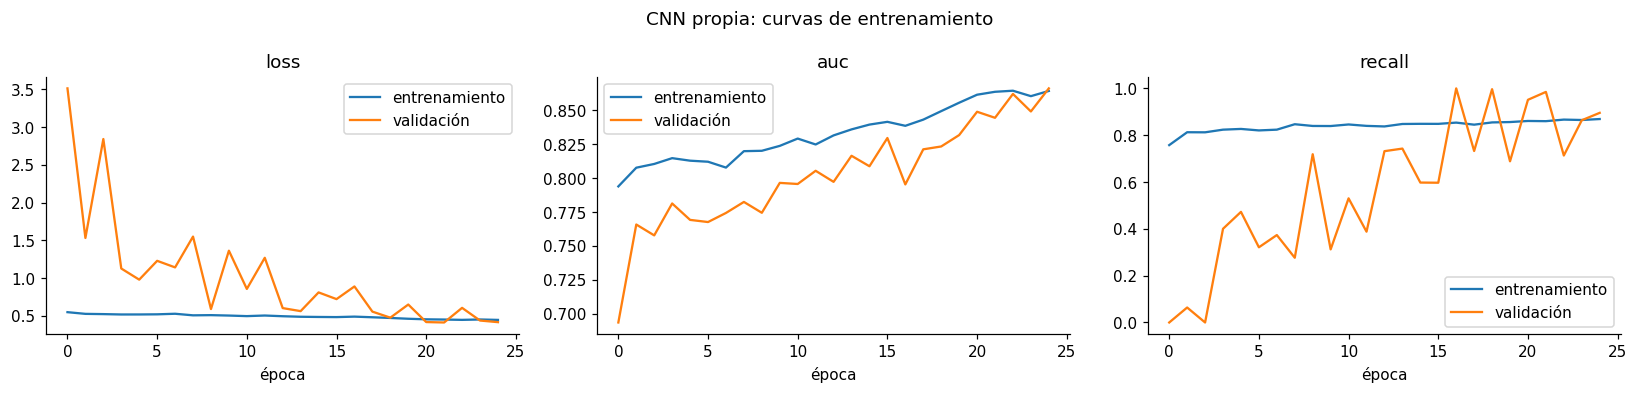

In [19]:
set_seed()
baseline = build_baseline()
baseline.compile(optimizer=keras.optimizers.AdamW(1e-3, weight_decay=1e-4),
                 loss="binary_crossentropy", metrics=compile_metrics())
hist_base = train(baseline, "cnn_base", train_ds, val_ds, EPOCHS_BASELINE, CLASS_WEIGHT)
plot_history([hist_base], "CNN propia: curvas de entrenamiento", "curvas_cnn_base")

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        8. Modelo 2: EfficientNet-B0 con transfer learning
    </h2>
</div>

**Por qué EfficientNet-B0:**
- Es una red preentrenada en ImageNet. Sus filtros ya detectan bordes y texturas, algo valioso con solo ~70 pacientes de entrenamiento.
- Sus bloques MBConv tienen **conexiones residuales** y **atención por canal (Squeeze-and-Excitation)**: la red aprende a dar más peso a los canales informativos. Son las técnicas avanzadas que pide la rúbrica.
- Tiene solo ~4M de parámetros, así que se puede desplegar en hardware modesto (sección 13).

**Estrategia de entrenamiento en dos etapas:**
1. **Cabeza:** congelamos la base y entrenamos solo la capa de clasificación con una tasa de aprendizaje alta.
2. **Ajuste fino:** descongelamos las últimas capas con una tasa 10 veces menor. Las capas de BatchNorm quedan congeladas para no destruir sus estadísticas.

In [20]:
def build_effnet(img_size=None, dropout=0.3, weights=None):
    img_size = img_size or IMG_SIZE
    base = keras.applications.EfficientNetB0(include_top=False, weights=weights or PRETRAINED_WEIGHTS,
                                             input_shape=(img_size, img_size, 3))
    base.trainable = False
    x = layers.GlobalAveragePooling2D(name="head_gap")(base.output)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dropout(dropout, name="head_drop")(x)
    out = layers.Dense(1, activation="sigmoid", dtype="float32", name="pred")(x)
    return keras.Model(base.input, out, name="efficientnet_b0"), base

def unfreeze_top(base, n_layers=60):
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

def make_loss(kind, df):
    # BCE con pesos de clase, o pérdida focal que se enfoca en los ejemplos difíciles
    if kind == "focal":
        alpha = float((df.label == 0).mean())   # peso para la clase positiva (mayoritaria)
        return keras.losses.BinaryFocalCrossentropy(gamma=2.0, apply_class_balancing=True, alpha=alpha), None
    return keras.losses.BinaryCrossentropy(), class_weights(df)

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       8.1 Diagrama de la arquitectura
    </h3>
</div>

EfficientNet-B0 apila 16 bloques **MBConv** en 7 etapas. Cada MBConv expande los canales, aplica una convolución *depthwise* (un filtro por canal, muy barata), usa **Squeeze-and-Excitation** para dar peso a los canales informativos y vuelve a comprimir. Cuando la entrada y la salida tienen la misma forma, suma la entrada (**conexión residual**).

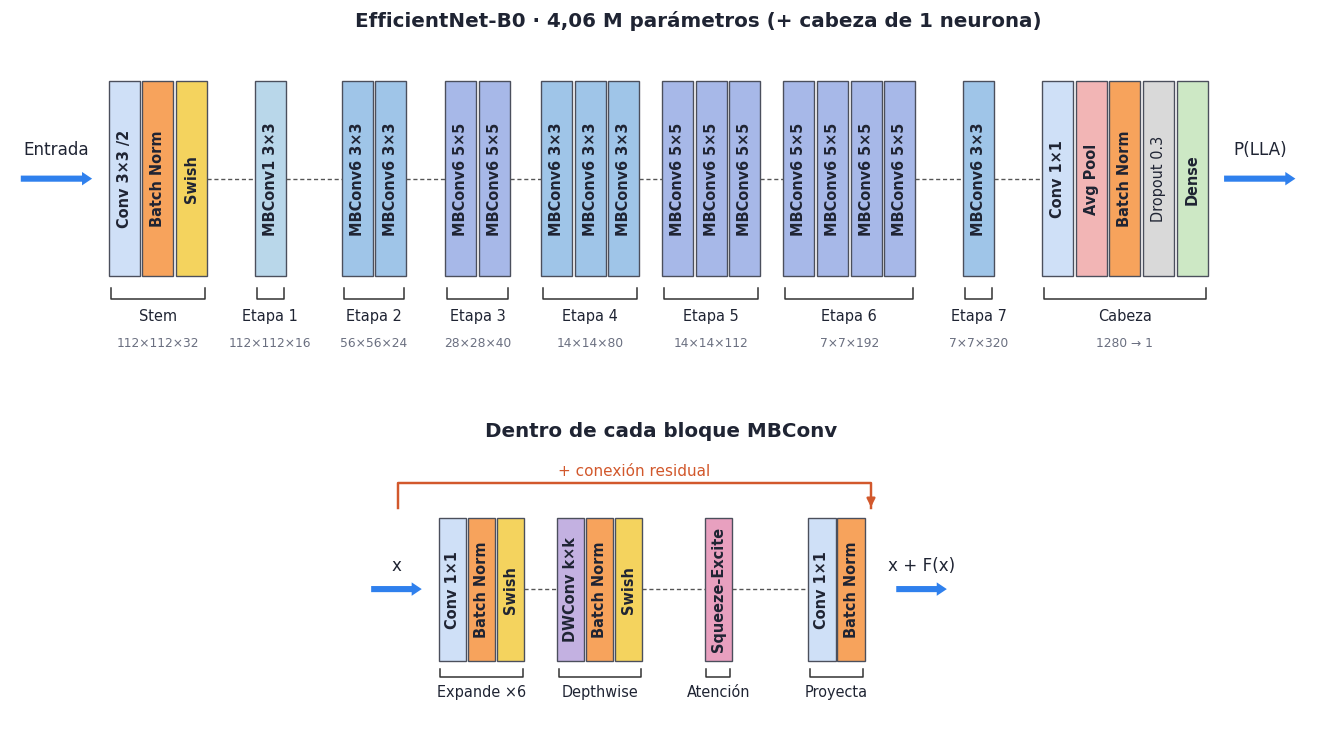

In [21]:
fig, ax = plt.subplots(2, 1, figsize=(16, 8.5), gridspec_kw={"height_ratios": [1.25, 1]})
draw_bars(ax[0], effnet_groups(IMG_SIZE), "EfficientNet-B0 · 4,06 M parámetros (+ cabeza de 1 neurona)", min_group_w=1.2)
draw_bars(ax[1], mbconv_groups(), None, in_label="x", out_label="x + F(x)", bar_w=0.55, gap_out=0.5, min_group_w=1.9)
draw_residual_arc(ax[1], 0.6, 10.2, 3.25)
draw_residual_title(ax[1], "Dentro de cada bloque MBConv")
savefig("arquitectura_efficientnet"); plt.show()

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        9. Experimentación con hiperparámetros
    </h2>
</div>

Comparamos cuatro configuraciones entrenando solo la cabeza de EfficientNet (es rápido) y elegimos la mejor por **AUC en validación**:
- **Pérdida:** BCE con pesos de clase vs. **pérdida focal** (Lin et al., 2017).
- **Tasa de aprendizaje:** 1e-3 vs. 3e-4.
- **Dropout de la cabeza:** 0.3 vs. 0.5.

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/6
273/273 - 35s - 128ms/step - acc: 0.7320 - auc: 0.7950 - loss: 0.5788 - pr_auc: 0.8584 - precision: 0.8411 - recall: 0.7372 - val_acc: 0.8036 - val_auc: 0.8153 - val_loss: 0.4839 - val_pr_auc: 0.9105 - val_precision: 0.8729 - val_recall: 0.8645 - learning_rate: 0.0010
Epoch 2/6
273/273 - 3s - 10ms/step - acc: 0.7659 - auc: 0.8332 - loss: 0.5126 - pr_auc: 0.8870 - precision: 0.8575 - recall: 0.7781 - val_acc: 0.8134 - val_auc: 0.8221 - val_loss: 0.4206 - val_pr_auc: 0.9185 - val_precision: 0.8519 - val_recall: 0.9099 - learning_rate: 0.0010
Epoch 3/6
273/273 - 3s - 10ms/step - acc: 0.7713 - auc: 0.8438 - loss: 0.4915 - pr_auc: 0.8953 - precision: 0.8607 - recall: 0.7838 - val_acc: 0.8305 - val_auc: 0.8465 - val_loss: 0.3905 - val_pr_auc: 0.9332 - val_precision: 0.8591 - val_recall: 0.9264 - learning_rate: 0.0010
Epoch 4/6
273/273 - 3s - 10ms/step - acc: 0.7809 - auc: 0.8490 - loss: 0.4856 - pr_auc: 0.8998 - precision: 0.8644 -

,pérdida,lr,dropout,AUC val,PR-AUC val,F1 val (umbral 0.5),minutos
3,bce_pesada,0.0010,0.5,0.8501,0.9355,0.8913,0.6729
0,bce_pesada,0.0010,0.3,0.8466,0.9333,0.8915,0.9414
1,focal,0.0010,0.3,0.8441,0.9260,0.8819,0.8181
2,bce_pesada,0.0003,0.3,0.8370,0.9258,0.8780,0.6736


Mejor configuración: {'pérdida': 'bce_pesada', 'lr': 0.001, 'dropout': 0.5}


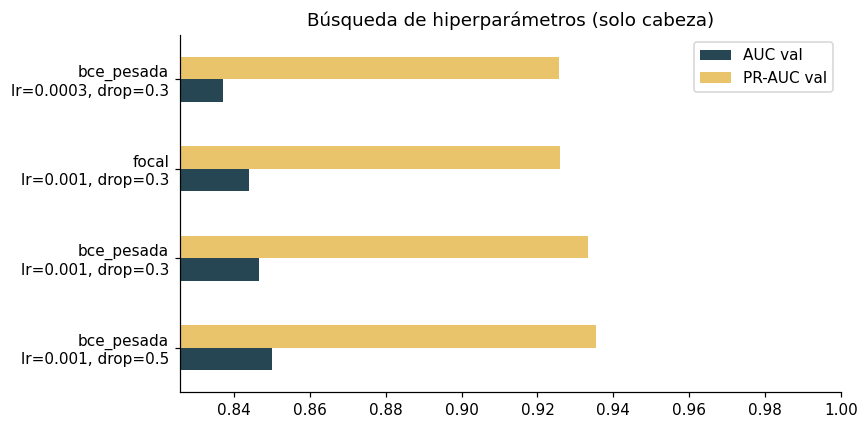

In [22]:
GRID = [
    {"pérdida": "bce_pesada", "lr": 1e-3, "dropout": 0.3},
    {"pérdida": "focal",      "lr": 1e-3, "dropout": 0.3},
    {"pérdida": "bce_pesada", "lr": 3e-4, "dropout": 0.3},
    {"pérdida": "bce_pesada", "lr": 1e-3, "dropout": 0.5},
]
grid_rows = []
for i, cfg in enumerate(GRID):
    set_seed()
    model, _ = build_effnet(dropout=cfg["dropout"])
    loss, cw = make_loss(cfg["pérdida"], tr_df)
    model.compile(keras.optimizers.AdamW(cfg["lr"], weight_decay=1e-4), loss=loss, metrics=compile_metrics())
    t0 = time.time()
    h = train(model, f"grid_{i}", train_ds, val_ds, EPOCHS_GRID, cw)
    p = model.predict(val_ds, verbose=0).ravel()
    grid_rows.append({**cfg, "AUC val": skm.roc_auc_score(va_df.label, p),
                      "PR-AUC val": skm.average_precision_score(va_df.label, p),
                      "F1 val (umbral 0.5)": skm.f1_score(va_df.label, p >= .5),
                      "minutos": (time.time() - t0) / 60})
    del model; gc.collect(); keras.backend.clear_session()

grid = pd.DataFrame(grid_rows).sort_values("AUC val", ascending=False)
display(grid.round(4))
BEST = grid.iloc[0][["pérdida", "lr", "dropout"]].to_dict()
print("Mejor configuración:", BEST)

ax = grid.assign(cfg=grid.apply(lambda r: f"{r['pérdida']}\nlr={r.lr:g}, drop={r.dropout}", axis=1)) \
         .plot.barh(x="cfg", y=["AUC val", "PR-AUC val"], figsize=(8, 4), color=["#264653", "#e9c46a"])
ax.set_xlim(max(0, grid["PR-AUC val"].min() - .1), 1); ax.set_ylabel("")
plt.title("Búsqueda de hiperparámetros (solo cabeza)"); plt.tight_layout(); savefig("grid_hiperparametros"); plt.show()

Epoch 1/5
273/273 - 20s - 73ms/step - acc: 0.7223 - auc: 0.7898 - loss: 0.6067 - pr_auc: 0.8559 - precision: 0.8353 - recall: 0.7269 - val_acc: 0.7328 - val_auc: 0.7939 - val_loss: 0.5292 - val_pr_auc: 0.9013 - val_precision: 0.8831 - val_recall: 0.7428 - learning_rate: 0.0010
Epoch 2/5
273/273 - 3s - 11ms/step - acc: 0.7510 - auc: 0.8200 - loss: 0.5427 - pr_auc: 0.8783 - precision: 0.8505 - recall: 0.7601 - val_acc: 0.7948 - val_auc: 0.8138 - val_loss: 0.4573 - val_pr_auc: 0.9138 - val_precision: 0.8740 - val_recall: 0.8494 - learning_rate: 0.0010
Epoch 3/5
273/273 - 3s - 11ms/step - acc: 0.7608 - auc: 0.8298 - loss: 0.5189 - pr_auc: 0.8869 - precision: 0.8565 - recall: 0.7704 - val_acc: 0.8300 - val_auc: 0.8430 - val_loss: 0.3996 - val_pr_auc: 0.9303 - val_precision: 0.8660 - val_recall: 0.9154 - learning_rate: 0.0010
Epoch 4/5
273/273 - 3s - 10ms/step - acc: 0.7650 - auc: 0.8358 - loss: 0.5056 - pr_auc: 0.8901 - precision: 0.8580 - recall: 0.7759 - val_acc: 0.8284 - val_auc: 0.8373 

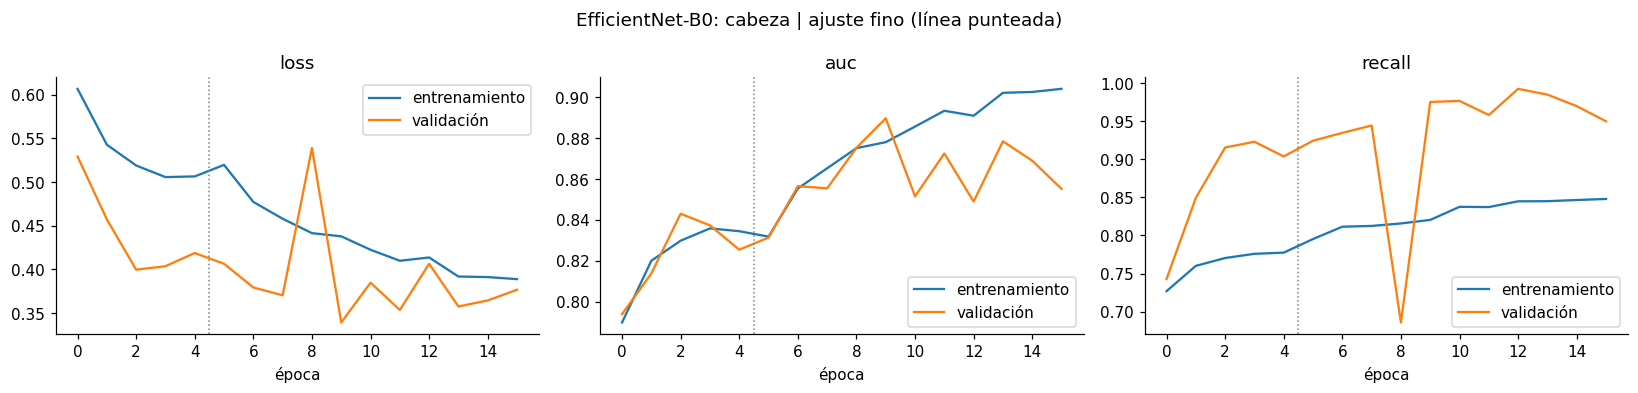

In [23]:
# Entrenamiento final de EfficientNet con la mejor configuración
set_seed()
effnet, base = build_effnet(dropout=BEST["dropout"])
loss, cw = make_loss(BEST["pérdida"], tr_df)

effnet.compile(keras.optimizers.AdamW(BEST["lr"], weight_decay=1e-4), loss=loss, metrics=compile_metrics())
hist_head = train(effnet, "effnet_cabeza", train_ds, val_ds, EPOCHS_HEAD, cw)

unfreeze_top(base, n_layers=60)
effnet.compile(keras.optimizers.AdamW(BEST["lr"] / 10, weight_decay=1e-4), loss=loss, metrics=compile_metrics())
print("Parámetros entrenables en el ajuste fino:",
      f"{sum(np.prod(w.shape) for w in effnet.trainable_weights):,}")
hist_ft = train(effnet, "effnet_finetune", train_ds, val_ds, EPOCHS_FINETUNE, cw)
plot_history([hist_head, hist_ft], "EfficientNet-B0: cabeza | ajuste fino (línea punteada)", "curvas_effnet")

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        10. Evaluación en el conjunto de prueba externo
    </h2>
</div>

**Protocolo:**
1. El **umbral de decisión se elige en validación**, nunca en prueba. Probamos tres criterios: máximo F1, índice de Youden, y el umbral más alto que logre **sensibilidad ≥ 95%** (en tamizaje es peor no detectar una célula leucémica que generar una falsa alarma). El criterio principal es **Youden**: con la clase positiva como mayoritaria, "máximo F1" tiende a umbrales que marcan casi todo como leucemia.
2. Con ese umbral fijo se evalúa una sola vez en los 28 pacientes de prueba.
3. Reportamos métricas por **célula** y por **paciente**, con intervalos de confianza por *bootstrap* sobre pacientes.

La clase positiva es **leucemia** (`all`). Sensibilidad = proporción de células leucémicas detectadas; especificidad = proporción de células sanas reconocidas como sanas.

In [24]:
def choose_thresholds(y, p, target_recall=0.95):
    prec, rec, thr = skm.precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    fpr, tpr, thr_roc = skm.roc_curve(y, p)
    ok = np.where(rec[:-1] >= target_recall)[0]
    return {"max F1": float(thr[np.argmax(f1)]),
            "Youden": float(np.clip(thr_roc[np.argmax(tpr - fpr)], 0, 1)),
            f"sensibilidad ≥{target_recall:.0%}": float(thr[ok].max()) if len(ok) else 0.5}

def compute_metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = skm.confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"umbral": thr, "exactitud": (tp + tn) / len(y),
            "exactitud balanceada": skm.balanced_accuracy_score(y, yhat),
            "sensibilidad": tp / max(tp + fn, 1), "especificidad": tn / max(tn + fp, 1),
            "precisión (VPP)": tp / max(tp + fp, 1), "F1": skm.f1_score(y, yhat, zero_division=0),
            "F1 ponderado": skm.f1_score(y, yhat, average="weighted", zero_division=0),
            "MCC": skm.matthews_corrcoef(y, yhat),
            "ROC-AUC": skm.roc_auc_score(y, p), "PR-AUC": skm.average_precision_score(y, p)}

MODELS = {"CNN propia": baseline, "EfficientNet-B0": effnet}
P_VAL = {n: m.predict(val_ds, verbose=0).ravel() for n, m in MODELS.items()}
P_TEST = {n: m.predict(test_ds, verbose=0).ravel() for n, m in MODELS.items()}
y_val, y_test = va_df.label.values, test_df.label.values

THRESHOLDS = {n: choose_thresholds(y_val, P_VAL[n]) for n in MODELS}
rows = []
for n in MODELS:
    for crit, t in THRESHOLDS[n].items():
        rows.append({"modelo": n, "criterio de umbral": crit, **compute_metrics(y_test, P_TEST[n], t)})
results = pd.DataFrame(rows).set_index(["modelo", "criterio de umbral"])
display(results.round(3).style.background_gradient(cmap="Greens", subset=["F1", "ROC-AUC", "MCC"]))
results.to_csv(f"{OUT_DIR}/metricas_prueba.csv")

MAIN_CRIT = "Youden"   # Youden equilibra sensibilidad y especificidad; "max F1" favorece marcar todo como leucemia
MAIN = "EfficientNet-B0" if results.loc[("EfficientNet-B0", MAIN_CRIT), "F1 ponderado"] >= \
                            results.loc[("CNN propia", MAIN_CRIT), "F1 ponderado"] else "CNN propia"
T_MAIN = THRESHOLDS[MAIN][MAIN_CRIT]
print(f"Modelo principal: {MAIN} (umbral {T_MAIN:.3f}, elegido en validación)")

Modelo principal: EfficientNet-B0 (umbral 0.787, elegido en validación)


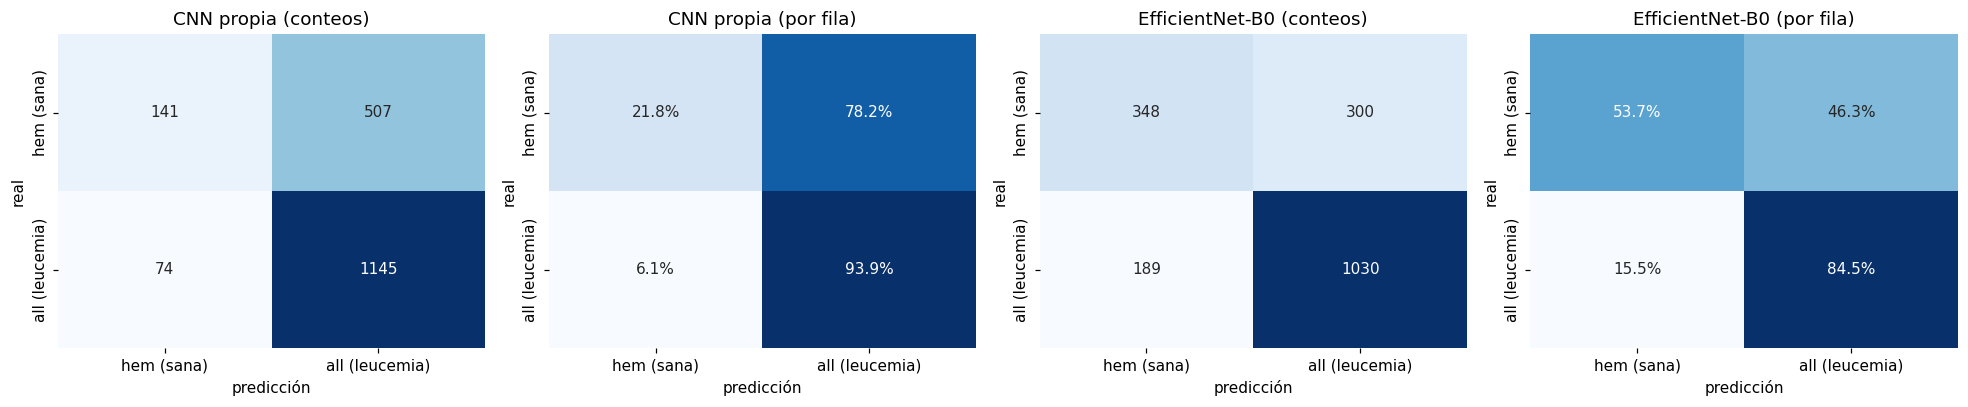

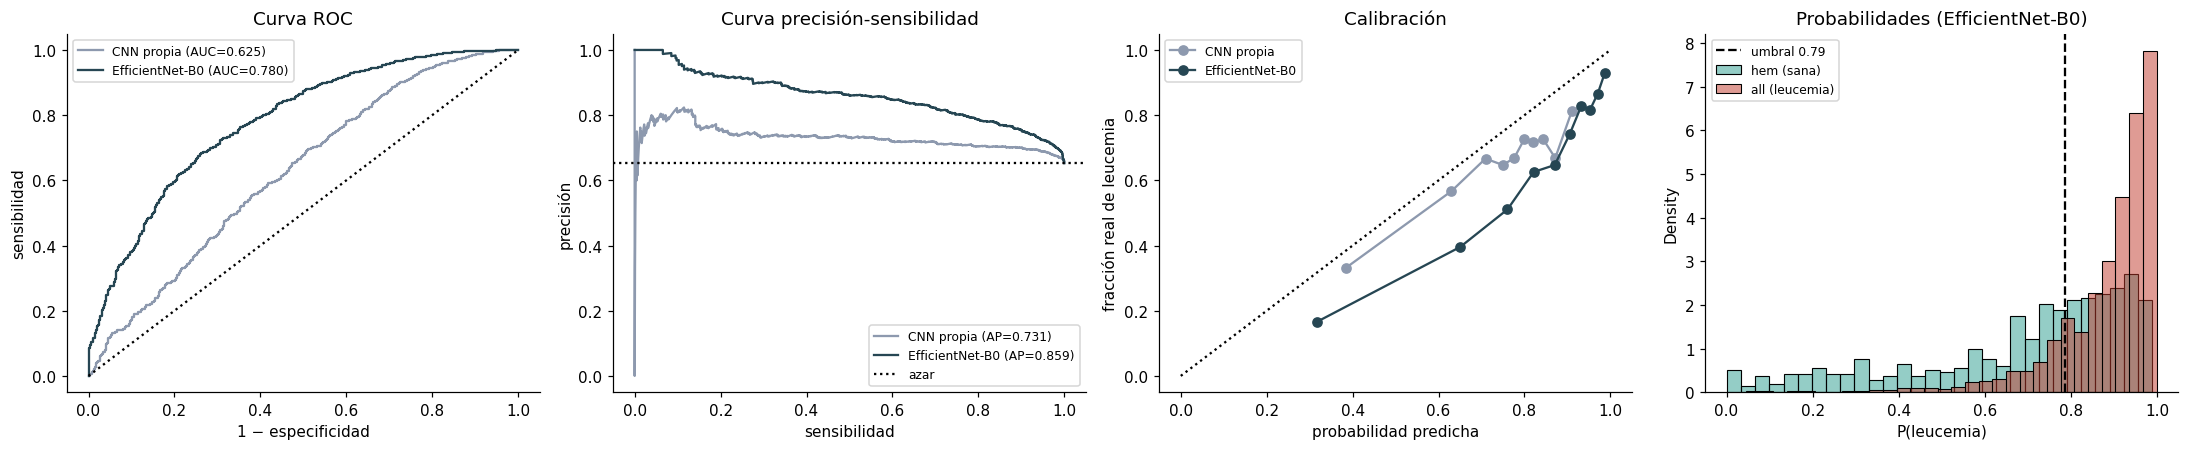

In [25]:
# Matrices de confusión
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for i, n in enumerate(MODELS):
    yhat = (P_TEST[n] >= THRESHOLDS[n][MAIN_CRIT]).astype(int)
    cm = skm.confusion_matrix(y_test, yhat)
    for j, (mat, fmt, ttl) in enumerate([(cm, "d", "conteos"), (cm / cm.sum(1, keepdims=True), ".1%", "por fila")]):
        sns.heatmap(mat, annot=True, fmt=fmt, cmap="Blues", cbar=False, ax=axes[2 * i + j],
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        axes[2 * i + j].set_title(f"{n} ({ttl})"); axes[2 * i + j].set_xlabel("predicción"); axes[2 * i + j].set_ylabel("real")
plt.tight_layout(); savefig("matrices_confusion"); plt.show()

# Curvas ROC, PR, calibración y distribución de probabilidades
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
for n, c in zip(MODELS, ["#8d99ae", "#264653"]):
    fpr, tpr, _ = skm.roc_curve(y_test, P_TEST[n])
    ax[0].plot(fpr, tpr, c=c, label=f"{n} (AUC={skm.roc_auc_score(y_test, P_TEST[n]):.3f})")
    pr, rc, _ = skm.precision_recall_curve(y_test, P_TEST[n])
    ax[1].plot(rc, pr, c=c, label=f"{n} (AP={skm.average_precision_score(y_test, P_TEST[n]):.3f})")
    fp_, mp_ = calibration_curve(y_test, P_TEST[n], n_bins=10, strategy="quantile")
    ax[2].plot(mp_, fp_, "o-", c=c, label=n)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set(title="Curva ROC", xlabel="1 − especificidad", ylabel="sensibilidad")
ax[1].axhline(y_test.mean(), color="k", ls=":", label="azar"); ax[1].set(title="Curva precisión-sensibilidad", xlabel="sensibilidad", ylabel="precisión")
ax[2].plot([0, 1], [0, 1], "k:"); ax[2].set(title="Calibración", xlabel="probabilidad predicha", ylabel="fracción real de leucemia")
for lab in [0, 1]:
    sns.histplot(P_TEST[MAIN][y_test == lab], bins=30, color=PALETTE[lab], alpha=.5, ax=ax[3], label=CLASS_NAMES[lab], stat="density")
ax[3].axvline(T_MAIN, color="k", ls="--", label=f"umbral {T_MAIN:.2f}"); ax[3].set(title=f"Probabilidades ({MAIN})", xlabel="P(leucemia)")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); savefig("curvas_evaluacion"); plt.show()

In [26]:
# Intervalos de confianza por bootstrap sobre PACIENTES (no sobre células)
def bootstrap_ci(df, p, thr, n_boot=N_BOOTSTRAP):
    d = df.assign(p=p)
    groups = {lab: [g for _, g in d[d.label == lab].groupby("subject")] for lab in [0, 1]}
    rng = np.random.default_rng(SEED)
    out = []
    for _ in range(n_boot):
        sample = pd.concat([groups[lab][k] for lab in [0, 1] for k in rng.integers(0, len(groups[lab]), len(groups[lab]))])
        yhat = (sample.p >= thr).astype(int)
        out.append({"F1 ponderado": skm.f1_score(sample.label, yhat, average="weighted"),
                    "ROC-AUC": skm.roc_auc_score(sample.label, sample.p),
                    "sensibilidad": skm.recall_score(sample.label, yhat),
                    "especificidad": skm.recall_score(sample.label, yhat, pos_label=0)})
    b = pd.DataFrame(out)
    return pd.DataFrame({"IC 2.5%": b.quantile(.025), "mediana": b.median(), "IC 97.5%": b.quantile(.975)})

ci = pd.concat({n: bootstrap_ci(test_df, P_TEST[n], THRESHOLDS[n][MAIN_CRIT]) for n in MODELS})
display(ci.round(3))

# Prueba de McNemar: ¿los dos modelos se equivocan en células distintas de forma significativa?
ok_b = (P_TEST["CNN propia"] >= THRESHOLDS["CNN propia"][MAIN_CRIT]).astype(int) == y_test
ok_e = (P_TEST["EfficientNet-B0"] >= THRESHOLDS["EfficientNet-B0"][MAIN_CRIT]).astype(int) == y_test
b, c = int((ok_b & ~ok_e).sum()), int((~ok_b & ok_e).sum())
p_mcnemar = stats.binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0
print(f"McNemar: solo acierta la CNN propia={b}, solo acierta EfficientNet={c}, p={p_mcnemar:.2e}")

IC 2.5%  mediana  IC 97.5%
CNN propia      F1 ponderado     0.511    0.633     0.736
                ROC-AUC          0.495    0.620     0.722
                sensibilidad     0.912    0.939     0.962
                especificidad    0.102    0.215     0.310
EfficientNet-B0 F1 ponderado     0.667    0.730     0.787
                ROC-AUC          0.686    0.774     0.841
                sensibilidad     0.776    0.846     0.902
                especificidad    0.429    0.530     0.609

McNemar: solo acierta la CNN propia=158, solo acierta EfficientNet=250, p=6.09e-06


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       10.1 Diagnóstico a nivel de paciente
    </h3>
</div>

En la práctica el médico no diagnostica una célula, sino un **paciente**. Agregamos las predicciones: un paciente se marca como sospechoso si la fracción de sus células clasificadas como leucémicas supera el 50%.

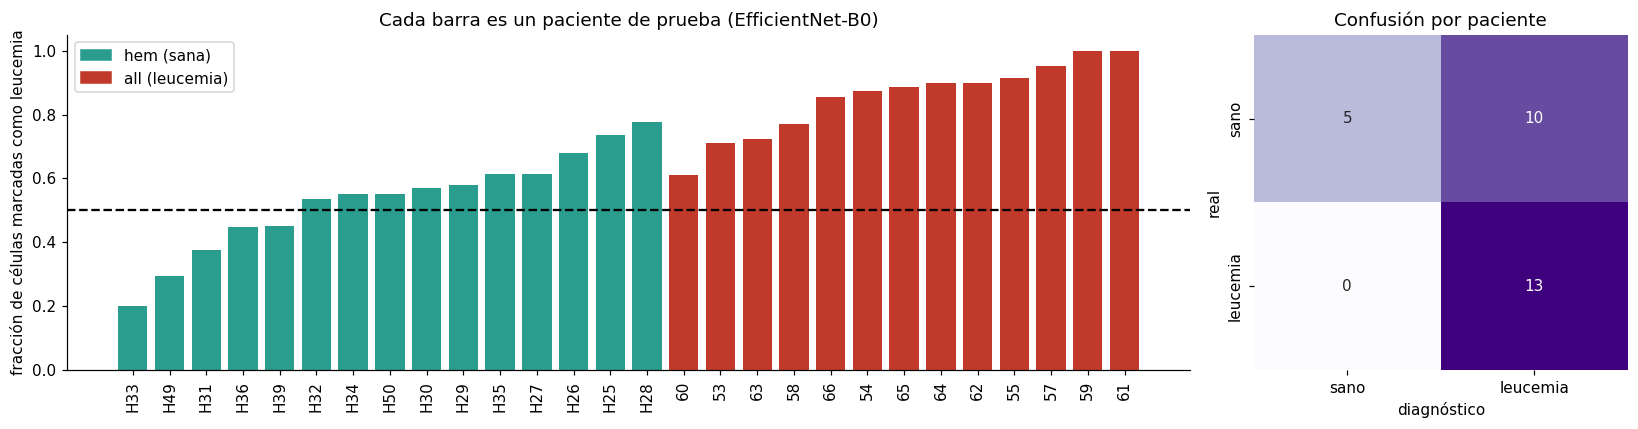

Exactitud por paciente: 64.3% (18/28)


,clase,células,frac_pos,p_media,exactitud_células,diagnóstico
subject,,,,,,
H33,0,5,0.200,0.588,0.800,0
H49,0,162,0.296,0.589,0.704,0
H31,0,77,0.377,0.632,0.623,0
H36,0,47,0.447,0.714,0.553,0
H39,0,84,0.452,0.708,0.548,0
H32,0,54,0.537,0.762,0.463,1
H34,0,20,0.550,0.722,0.450,1
H50,0,29,0.552,0.723,0.448,1
H30,0,35,0.571,0.736,0.429,1


In [27]:
d = test_df.assign(p=P_TEST[MAIN], pred=(P_TEST[MAIN] >= T_MAIN).astype(int))
d["acierto"] = d.pred == d.label
pat = d.groupby("subject").agg(clase=("label", "first"), células=("p", "size"), frac_pos=("pred", "mean"),
                               p_media=("p", "mean"), exactitud_células=("acierto", "mean"))
pat["diagnóstico"] = (pat.frac_pos >= 0.5).astype(int)
pat = pat.sort_values(["clase", "frac_pos"])

fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})
ax[0].bar(pat.index.astype(str), pat.frac_pos, color=pat.clase.map(PALETTE))
ax[0].axhline(.5, color="k", ls="--"); ax[0].set_ylabel("fracción de células marcadas como leucemia")
ax[0].set_title(f"Cada barra es un paciente de prueba ({MAIN})"); ax[0].tick_params(axis="x", rotation=90)
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PALETTE[k]) for k in [0, 1]], labels=CLASS_NAMES)
sns.heatmap(skm.confusion_matrix(pat.clase, pat.diagnóstico, labels=[0, 1]), annot=True, fmt="d", cbar=False,
            cmap="Purples", ax=ax[1], xticklabels=["sano", "leucemia"], yticklabels=["sano", "leucemia"])
ax[1].set_title("Confusión por paciente"); ax[1].set_xlabel("diagnóstico"); ax[1].set_ylabel("real")
plt.tight_layout(); savefig("nivel_paciente"); plt.show()
print(f"Exactitud por paciente: {(pat.clase == pat.diagnóstico).mean():.1%} ({(pat.clase == pat.diagnóstico).sum()}/{len(pat)})")
display(pat.round(3))

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">

<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        11. Análisis de errores y explicabilidad
    </h2>
</div>

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       11.1 ¿Dónde se equivoca el modelo?
    </h3>
</div>

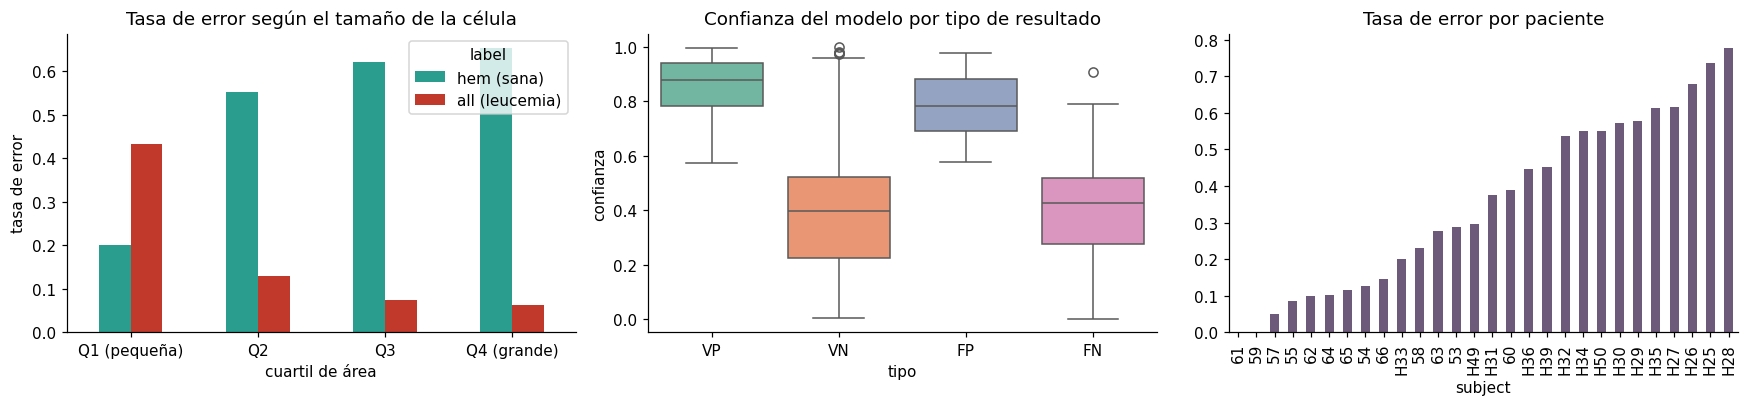

{'VP': 1030, 'VN': 348, 'FP': 300, 'FN': 189}


In [28]:
err = test_df.assign(p=P_TEST[MAIN], pred=(P_TEST[MAIN] >= T_MAIN).astype(int))
err["tipo"] = np.select([(err.label == 1) & (err.pred == 1), (err.label == 0) & (err.pred == 0),
                         (err.label == 0) & (err.pred == 1)], ["VP", "VN", "FP"], "FN")
err = pd.concat([err.reset_index(drop=True), pd.DataFrame([cell_stats(p) for p in err.path])], axis=1)
err["error"] = err.tipo.isin(["FP", "FN"])
err["cuartil de área"] = pd.qcut(err.area_frac, 4, labels=["Q1 (pequeña)", "Q2", "Q3", "Q4 (grande)"])
err["confianza"] = np.abs(err.p - 0.5) * 2

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
err.groupby(["cuartil de área", "label"]).error.mean().unstack().rename(columns=dict(enumerate(CLASS_NAMES))) \
   .plot.bar(ax=ax[0], rot=0, color=[PALETTE[0], PALETTE[1]])
ax[0].set_title("Tasa de error según el tamaño de la célula"); ax[0].set_ylabel("tasa de error")
sns.boxplot(data=err, x="tipo", y="confianza", order=["VP", "VN", "FP", "FN"], ax=ax[1], palette="Set2")
ax[1].set_title("Confianza del modelo por tipo de resultado")
err.groupby("subject").error.mean().sort_values().plot.bar(ax=ax[2], color="#6d597a")
ax[2].set_title("Tasa de error por paciente"); ax[2].tick_params(axis="x", rotation=90)
plt.tight_layout(); savefig("analisis_errores"); plt.show()
print(err.tipo.value_counts().to_dict())

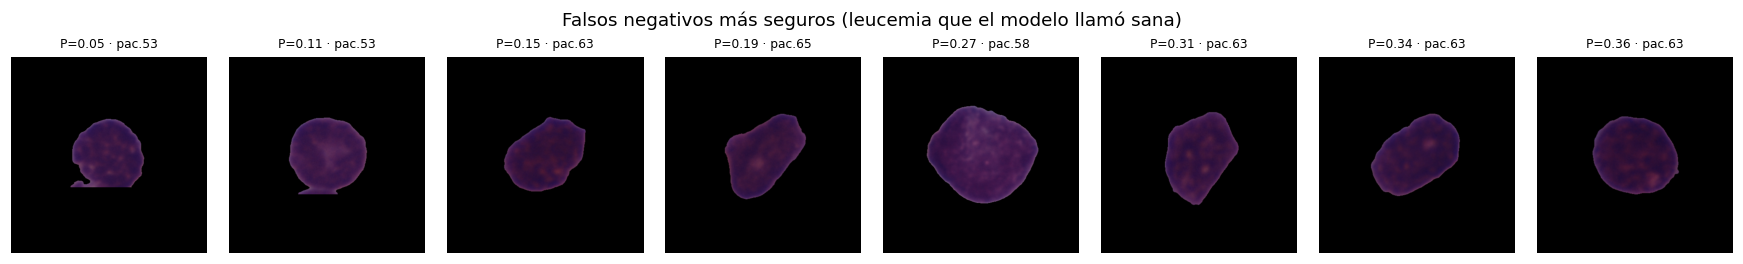

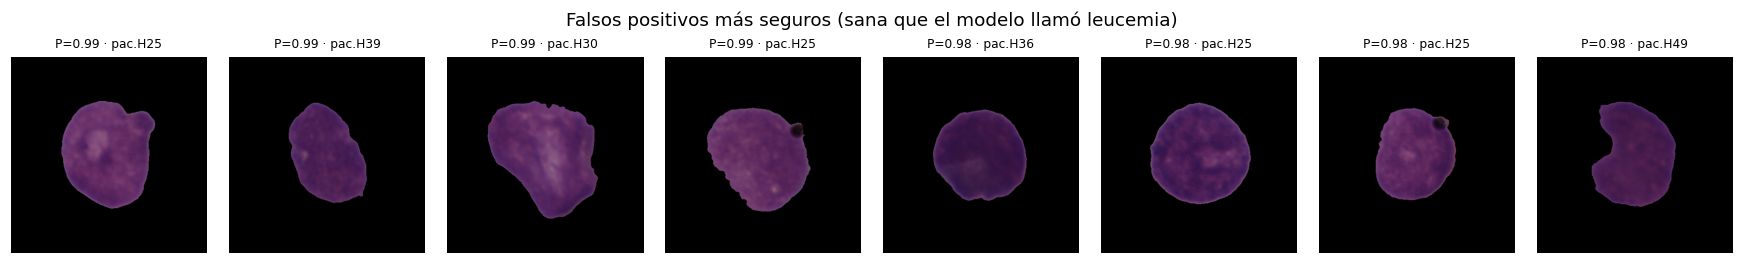

In [29]:
def show_cases(df, title, n=8):
    if df.empty: print("Sin casos para:", title); return
    df = df.head(n)
    fig, axes = plt.subplots(1, len(df), figsize=(2 * len(df), 2.4))
    for a, (_, r) in zip(np.atleast_1d(axes), df.iterrows()):
        a.imshow(Image.open(r.path).convert("RGB")); a.axis("off")
        a.set_title(f"P={r.p:.2f} · pac.{r.subject}", fontsize=8)
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_cases(err[err.tipo == "FN"].sort_values("p"), "Falsos negativos más seguros (leucemia que el modelo llamó sana)")
show_cases(err[err.tipo == "FP"].sort_values("p", ascending=False), "Falsos positivos más seguros (sana que el modelo llamó leucemia)")

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
       11.2 Grad-CAM: ¿en qué se fija el modelo?
    </h3>
</div>

Grad-CAM (Selvaraju et al., 2017) colorea las regiones que más empujan la predicción. Un modelo confiable debería mirar el **núcleo y la cromatina**, no el fondo ni el borde de la imagen. Además lo medimos: **qué fracción de la activación cae dentro de la célula**.

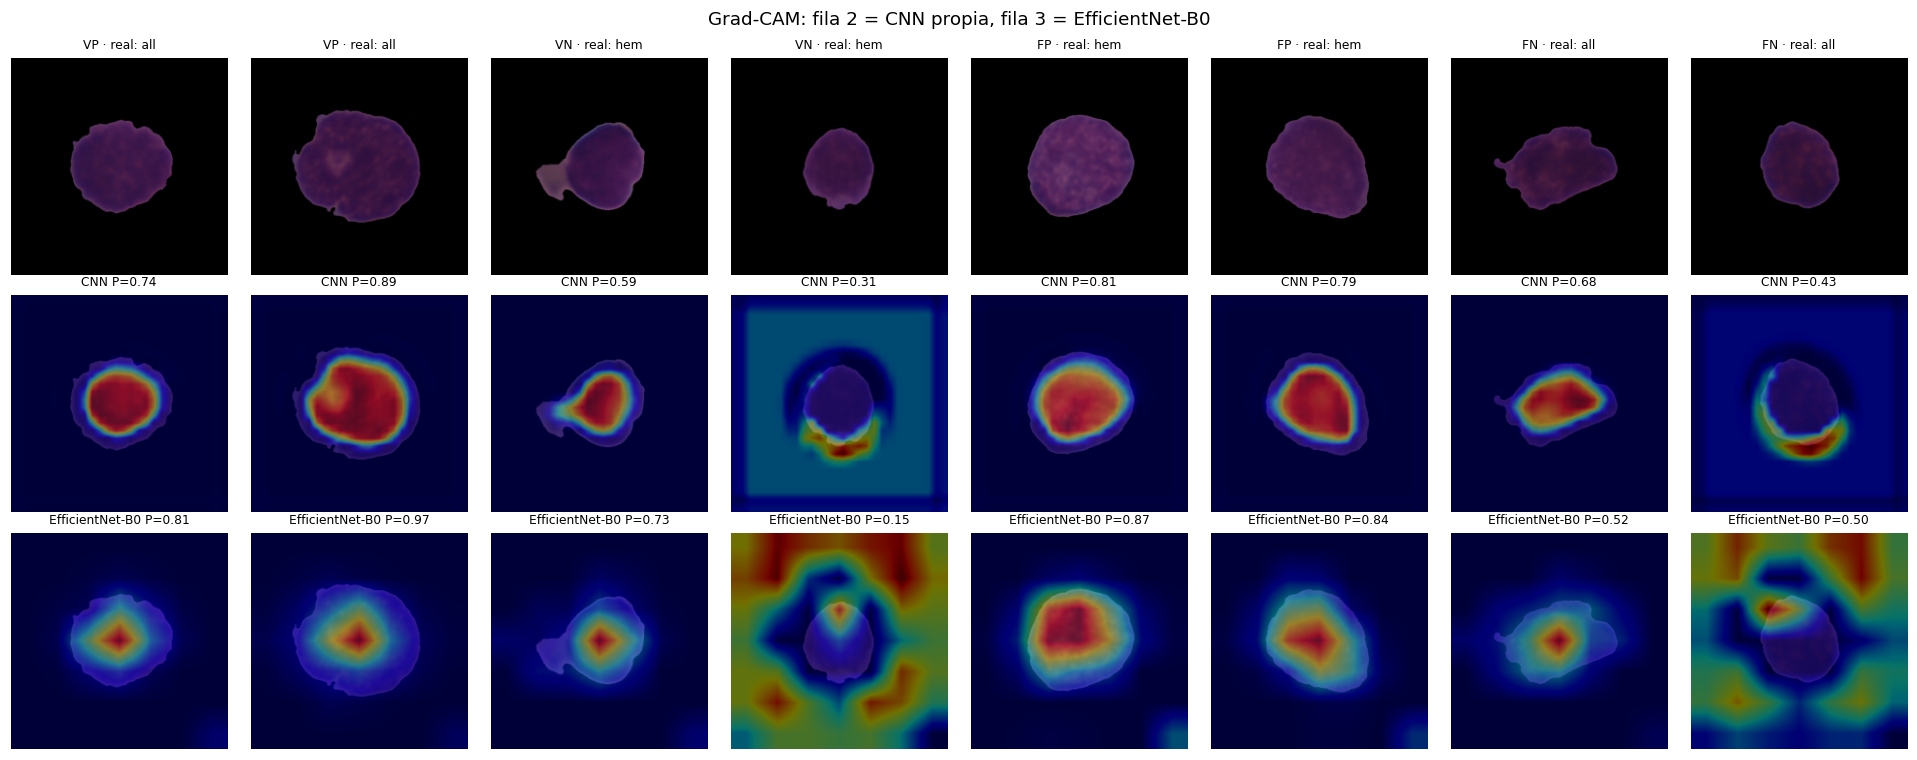

,activación dentro de la célula,área de la célula
modelo,,
CNN propia,0.862,0.168
EfficientNet-B0,0.660,0.168


Si la activación dentro de la célula es mucho mayor que el área que ocupa la célula, el modelo se fija en ella y no en el fondo.


In [30]:
GRADCAM_LAYER = {"CNN propia": "last_conv_relu", "EfficientNet-B0": "top_activation"}

_GRAD_MODELS = {}   # un modelo auxiliar por (modelo, capa): crearlo en cada llamada llena la memoria

def grad_cam(model, layer_name, img_uint8):
    key = (id(model), layer_name)
    if key not in _GRAD_MODELS:
        _GRAD_MODELS[key] = keras.Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    grad_model = _GRAD_MODELS[key]
    x = tf.cast(img_uint8[None], tf.float32)
    with tf.GradientTape() as tape:
        conv_out, pred = grad_model(x, training=False)
        pred = tf.cast(pred, tf.float32)[:, 0]
        target = tf.where(pred >= 0.5, pred, 1 - pred)       # explica la clase predicha
    grads = tape.gradient(target, conv_out)                  # gradiente respecto a la salida ORIGINAL de la capa
    # con precisión mixta (GPU) la capa sale en float16: se pasa a float32 DESPUÉS de derivar
    conv_out, grads = tf.cast(conv_out, tf.float32), tf.cast(grads, tf.float32)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out * w[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], img_uint8.shape[:2]).numpy()[..., 0]
    return cam, float(pred[0])

def overlay(img, cam):
    heat = plt.cm.jet(cam)[..., :3]
    return np.clip(0.55 * img / 255. + 0.45 * heat, 0, 1)

picks = pd.concat([err[err.tipo == t].sample(min(2, (err.tipo == t).sum()), random_state=SEED) for t in ["VP", "VN", "FP", "FN"]])
fig, axes = plt.subplots(3, len(picks), figsize=(2.2 * len(picks), 7))
for j, (_, r) in enumerate(picks.iterrows()):
    img = load_image(r.path, IMG_SIZE).numpy()
    axes[0, j].imshow(img); axes[0, j].set_title(f"{r.tipo} · real: {CLASS_NAMES[r.label].split()[0]}", fontsize=8)
    for i, n in enumerate(MODELS, start=1):
        cam, p = grad_cam(MODELS[n], GRADCAM_LAYER[n], img)
        axes[i, j].imshow(overlay(img, cam)); axes[i, j].set_title(f"{n.split()[0]} P={p:.2f}", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.suptitle("Grad-CAM: fila 2 = CNN propia, fila 3 = EfficientNet-B0"); plt.tight_layout(); savefig("gradcam"); plt.show()

# Explicabilidad cuantitativa: fracción de la activación que cae sobre la célula
rows = []
for _, r in err.sample(min(60, len(err)), random_state=SEED).iterrows():
    img = load_image(r.path, IMG_SIZE).numpy()
    mask = img.sum(axis=2) > 30
    for n in MODELS:
        cam, _ = grad_cam(MODELS[n], GRADCAM_LAYER[n], img)
        rows.append({"modelo": n, "activación dentro de la célula": cam[mask].sum() / (cam.sum() + 1e-8),
                     "área de la célula": mask.mean()})
cam_in = pd.DataFrame(rows).groupby("modelo").mean()
display(cam_in.round(3))
print("Si la activación dentro de la célula es mucho mayor que el área que ocupa la célula, el modelo se fija en ella y no en el fondo.")

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        12. Robustez ante condiciones reales
    </h2>
</div>

Un laboratorio real tendrá otro microscopio, otra cámara y otra tinción. Sin datos de otro hospital, simulamos esas condiciones degradando las imágenes de prueba y medimos cuánto cae el AUC.

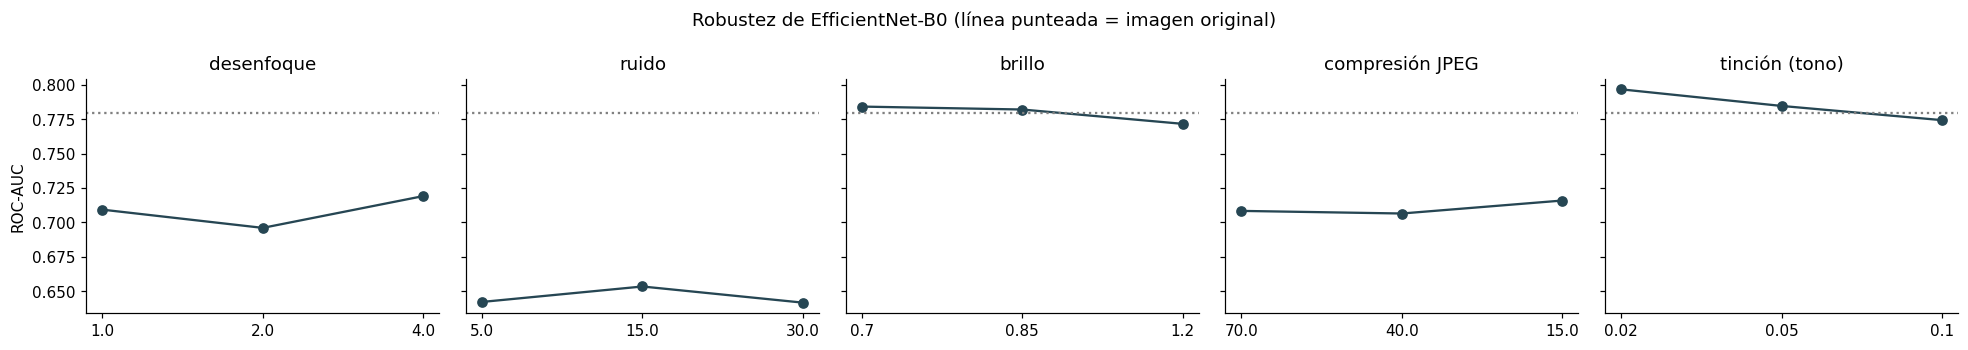

,perturbación,nivel,ROC-AUC,sensibilidad
0,desenfoque,1.00,0.709,0.164
1,desenfoque,2.00,0.696,0.026
2,desenfoque,4.00,0.719,0.000
3,ruido,5.00,0.642,0.999
4,ruido,15.00,0.654,0.998
5,ruido,30.00,0.642,0.999
6,brillo,0.70,0.784,0.693
7,brillo,0.85,0.782,0.788
8,brillo,1.20,0.772,0.883
9,compresión JPEG,70.00,0.708,0.941


In [31]:
def perturb(kind, level):
    def f(x, y):
        if kind == "desenfoque":
            k = int(level) * 2 + 1
            x = tf.nn.avg_pool2d(x, k, 1, "SAME")
        elif kind == "ruido":
            x = x + tf.random.normal(tf.shape(x), stddev=level)
        elif kind == "brillo":
            x = x * level
        elif kind == "compresión JPEG":
            x = tf.map_fn(lambda im: tf.cast(tf.image.decode_jpeg(tf.image.encode_jpeg(tf.cast(im, tf.uint8), quality=int(level)), channels=3), tf.float32),
                          x, fn_output_signature=tf.float32)
        elif kind == "tinción (tono)":
            x = tf.image.adjust_hue(x / 255., level) * 255.
        return tf.clip_by_value(x, 0, 255), y
    return f

PERTURBATIONS = {"desenfoque": [1, 2, 4], "ruido": [5, 15, 30], "brillo": [0.7, 0.85, 1.2],
                 "compresión JPEG": [70, 40, 15], "tinción (tono)": [0.02, 0.05, 0.1]}
base_test = make_dataset(test_df)
rob = []
for kind, levels in PERTURBATIONS.items():
    for lvl in levels:
        p = MODELS[MAIN].predict(base_test.map(perturb(kind, lvl)), verbose=0).ravel()
        rob.append({"perturbación": kind, "nivel": lvl, "ROC-AUC": skm.roc_auc_score(y_test, p),
                    "sensibilidad": skm.recall_score(y_test, p >= T_MAIN)})
rob = pd.DataFrame(rob)
auc_clean = skm.roc_auc_score(y_test, P_TEST[MAIN])
fig, ax = plt.subplots(1, len(PERTURBATIONS), figsize=(18, 3.2), sharey=True)
for a, (kind, g) in zip(ax, rob.groupby("perturbación", sort=False)):
    a.plot(range(len(g)), g["ROC-AUC"], "o-", c="#264653"); a.axhline(auc_clean, ls=":", c="gray")
    a.set_xticks(range(len(g))); a.set_xticklabels(g.nivel); a.set_title(kind)
ax[0].set_ylabel("ROC-AUC"); plt.suptitle(f"Robustez de {MAIN} (línea punteada = imagen original)")
plt.tight_layout(); savefig("robustez"); plt.show()
display(rob.round(3))

Las perturbaciones con la mayor caída indican qué hay que **estandarizar en el protocolo de captura** (o reforzar en el aumento de datos) antes de desplegar.

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        13. Eficiencia, huella de carbono y exportación ligera
    </h2>
</div>


In [32]:
def model_size_mb(model):
    path = f"{OUT_DIR}/{model.name}.keras"; model.save(path)
    return os.path.getsize(path) / 1e6

def latency_ms(model, batch):
    x = tf.zeros((batch, IMG_SIZE, IMG_SIZE, 3))
    model.predict(x, verbose=0)
    t0 = time.time(); [model.predict(x, verbose=0) for _ in range(5)]
    return (time.time() - t0) / 5 / batch * 1000

eff = pd.DataFrame([{"modelo": n, "parámetros (M)": m.count_params() / 1e6, "tamaño (MB)": model_size_mb(m),
                     "ms por imagen (lote 1)": latency_ms(m, 1), "ms por imagen (lote 32)": latency_ms(m, 32)}
                    for n, m in MODELS.items()]).set_index("modelo")
display(eff.round(2))

energy = pd.DataFrame(ENERGY_LOG)
display(energy.round(5))
print(f"TOTAL: {energy.minutos.sum():.1f} min · {energy.kWh.sum():.4f} kWh · {energy['kg CO2eq'].sum()*1000:.1f} g CO2eq")

,parámetros (M),tamaño (MB),ms por imagen (lote 1),ms por imagen (lote 32)
modelo,,,,
CNN propia,0.62,12.48,42.42,1.45
EfficientNet-B0,4.06,38.32,45.01,1.47


,experimento,minutos,kWh,kg CO2eq
0,cnn_base,1.67574,0.00927,0.00240
1,grid_0,0.80689,0.00273,0.00071
2,grid_1,0.72256,0.00252,0.00065
3,grid_2,0.57832,0.00217,0.00056
4,grid_3,0.57863,0.00216,0.00056
5,effnet_cabeza,0.52608,0.00191,0.00050
6,effnet_finetune,0.94923,0.00384,0.00100


TOTAL: 5.8 min · 0.0246 kWh · 6.4 g CO2eq


In [33]:
# Exportación a TensorFlow Lite con cuantización: para equipos de bajo costo (celular, Raspberry Pi)
tflite_path = f"{OUT_DIR}/modelo_leucemia.tflite"
try:
    export_dir = f"{OUT_DIR}/saved_model"
    MODELS[MAIN].export(export_dir)
    conv = tf.lite.TFLiteConverter.from_saved_model(export_dir)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]          # cuantización de pesos a 8 bits
    open(tflite_path, "wb").write(conv.convert())
    interp = tf.lite.Interpreter(model_path=tflite_path); interp.allocate_tensors()
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
    sub = test_df.sample(min(200, len(test_df)), random_state=SEED)
    p_lite = []
    for path in sub.path:
        interp.set_tensor(inp["index"], tf.cast(load_image(path, IMG_SIZE), tf.float32)[None].numpy())
        interp.invoke(); p_lite.append(float(interp.get_tensor(out["index"]).ravel()[0]))
    p_keras = MODELS[MAIN].predict(make_dataset(sub), verbose=0).ravel()
    print(f"TFLite: {os.path.getsize(tflite_path)/1e6:.1f} MB (vs {eff.loc[MAIN, 'tamaño (MB)']:.1f} MB en Keras)")
    print(f"Coincidencia de decisiones Keras vs TFLite: {np.mean((np.array(p_lite) >= T_MAIN) == (p_keras >= T_MAIN)):.1%}")
except Exception as e:
    print("No se pudo exportar a TFLite en este entorno:", type(e).__name__, str(e)[:200])

Saved artifact at '/content/resultados/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139648720034064: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139648720030416: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139649788997520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139649788985808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139649788985616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139649788990032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139649788986000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139649788998096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139649788990224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139649788989648: TensorSpec(shape=(), dtype=tf.reso

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        14. Conclusiones y propuestas de mejora
    </h2>
</div>


La siguiente celda imprime los números clave de la corrida actual. Las conclusiones de abajo se redactaron con la corrida del 8 de noviembre de 2026 (GPU NVIDIA RTX PRO 6000 en Colab). Entre corridas los números del modelo de referencia cambian bastante: su AUC externo fue 0,649, 0,714, 0,689 y 0,780 en cuatro corridas. El del modelo final de la sección 18 fue mucho más estable: 0,931–0,937. Por eso reportamos intervalos de confianza.

In [34]:
r = results.loc[(MAIN, MAIN_CRIT)]
print(f"Modelo principal: {MAIN} · umbral {T_MAIN:.3f} elegido en validación")
print(f"Prueba externa ({test_df.subject.nunique()} pacientes nuevos): ROC-AUC {r['ROC-AUC']:.3f} · F1 ponderado {r['F1 ponderado']:.3f} · "
      f"sensibilidad {r['sensibilidad']:.3f} · especificidad {r['especificidad']:.3f}")
print(f"IC 95% del F1 ponderado (bootstrap por paciente): {ci.loc[(MAIN, 'F1 ponderado'), 'IC 2.5%']:.3f} – {ci.loc[(MAIN, 'F1 ponderado'), 'IC 97.5%']:.3f}")
print(f"Diagnóstico por paciente correcto: {(pat.clase == pat.diagnóstico).sum()}/{len(pat)}")
print(f"Fuga de datos: la validación aleatoria sobreestimó el AUC en {leak.iloc[0]['brecha (val − prueba)']:.3f} puntos")
print("Perturbación más dañina:", rob.loc[rob['ROC-AUC'].idxmin(), ['perturbación', 'nivel', 'ROC-AUC']].to_dict())
json.dump({"modelo": MAIN, "umbral": T_MAIN, **{k: float(v) for k, v in r.items()}},
          open(f"{OUT_DIR}/resumen.json", "w"), indent=2, ensure_ascii=False)

Modelo principal: EfficientNet-B0 · umbral 0.787 elegido en validación
Prueba externa (28 pacientes nuevos): ROC-AUC 0.780 · F1 ponderado 0.732 · sensibilidad 0.845 · especificidad 0.537
IC 95% del F1 ponderado (bootstrap por paciente): 0.667 – 0.787
Diagnóstico por paciente correcto: 18/28
Fuga de datos: la validación aleatoria sobreestimó el AUC en 0.310 puntos
Perturbación más dañina: {'perturbación': 'ruido', 'nivel': 30.0, 'ROC-AUC': 0.6418316217502709}


### Conclusiones del modelo de referencia 
1. **La evaluación honesta cambia la historia.** En validación por paciente, EfficientNet-B0 llegó a un ROC-AUC de 0,89. En la **prueba externa** (28 pacientes nuevos) cayó a **0,780** (IC 95% por *bootstrap* de pacientes: 0,69–0,84). La CNN propia quedó en 0,625 (IC 95%: 0,50–0,72).
2. **EfficientNet supera a la CNN propia.** La diferencia es significativa (McNemar: 250 células que solo acierta EfficientNet frente a 158 que solo acierta la CNN propia, p = 6,1·10⁻⁶). En la corrida del 7 de noviembre no lo fue (p = 0,10): con modelos tan inestables, una sola corrida no basta.
3. **La fuga de datos es real.** Con la misma red, la validación aleatoria por imagen dio un AUC de 0,839 frente a 0,753 por paciente. En la prueba externa ambas cayeron a 0,529. Además de la fuga, hay un **cambio de dominio** entre los pacientes de entrenamiento y los de la fase preliminar del reto.
4. **El modelo aprendió un atajo: el tamaño de la célula.**
   - En el EDA, las células leucémicas ocupan más área (mediana 0,180 frente a 0,124; Mann-Whitney p ≈ 7·10⁻⁵⁴). Usando **solo el área** ya se obtiene un AUC de 0,855 (sección 18.1).
   - En la prueba externa, el modelo falla en ~20% de las células sanas más pequeñas, pero en el **55–65%** de las demás.
   - Grad-CAM: 66% de la activación cae dentro de la célula, que ocupa 17% de la imagen.
5. **Umbral.** Con Youden (umbral 0,787): sensibilidad 0,845, especificidad 0,537, F1 ponderado 0,732, MCC 0,402. Con "máximo F1" el umbral baja a 0,504 y la especificidad cae a 0,22. Por paciente acierta 18 de 28.
6. **Robustez baja.** Con ruido, desenfoque, compresión o cambios de tinción, el AUC osciló entre 0,64 (ruido) y 0,80. Con ruido el modelo marca casi todo como positivo y con desenfoque casi todo como negativo.
7. **Eficiencia.** 1,5 ms por célula en GPU; el modelo en TFLite pesa 4,6 MB (frente a 38,3 MB) y coincide en el 92,0% de las decisiones. Las secciones 7–13 usaron 5,8 min de GPU, 0,025 kWh y ~6 g de CO₂eq.

> **La sección 18 corrige estos problemas:** con resolución nativa, arquitecturas más fuertes y un ensamble, el AUC externo sube a **0,937**.

### Propuestas de mejora basadas en los hallazgos
Las propuestas SIGUIENTES se implementaron y midieron en la **sección 18**:
- **Usar la resolución nativa** (recorte central de 300 px, V2): AUC 0,882. Fue el cambio que más aportó: la receta nueva sola, con la imagen reducida (V1), no mejoró (0,772).
- **Romper el atajo del tamaño** (normalización de tamaño, V3): el área deja de servir (AUC solo con el área: 0,855 → 0,444) y el modelo logra un AUC de 0,900.
- **Arquitecturas más fuertes y ensambles** (V4–V10): Xception 0,901, ConvNeXt-Tiny 0,922 y el ensamble final 0,937. La validación cruzada por paciente (V7) no ayudó: 0,908.
- **Aumento de tinción** (V9): no ayudó en C-NMC (0,912 frente a 0,922) y apenas movió Irán (sección 18.8).
- **Normalización de tinción**, **datos de varios centros con ID de paciente** y **validación local por paciente**: pendientes (sección 19).

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">

<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        15. Implementación en un entorno real
    </h2>
</div>

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    15.1 Cómo funcionaría el sistema    
</h3>
</div>

El caso de uso clínico está en la sección 1.6; aquí se describe la parte técnica.
```
Frotis teñido → Microscopio con cámara → Detección y recorte de leucocitos → Clasificador CNN
             → Agregación por paciente → Panel para el hematólogo (con Grad-CAM) → Sistema del laboratorio (LIS)
```
C-NMC trae las células **ya recortadas**. En un laboratorio real se necesita antes un **detector o segmentador de leucocitos** (p. ej. YOLO o U-Net), que debe desarrollarse y validarse aparte. **La sección 17 implementa este paso con YOLO11 + SAM 2.**


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    15.2 Servicios necesarios en un entorno profesional  
</h3>
</div>

| Componente | Opciones | Comentario |
|---|---|---|
| Captura de imágenes | Cámara acoplada al microscopio o escáner de láminas | Estandarizar aumento, iluminación y tinción |
| Cómputo de entrenamiento | GPU en la nube (por horas) | Solo para reentrenar; no es un costo permanente |
| Inferencia | CPU local o dispositivo de borde con el modelo TFLite | Las imágenes no salen del hospital (privacidad) |
| Almacenamiento | Servidor local cifrado o nube con cumplimiento sanitario | Retención según la normativa de historia clínica |
| Integración | HL7 / FHIR hacia el sistema de información del laboratorio | El resultado queda en la orden del paciente |
| MLOps | Versionado de datos y modelos (DVC, MLflow), monitoreo de deriva | Alertas si cambia la distribución de las imágenes |
| Seguridad | Control de acceso, registro de auditoría, firma de los modelos | Requisito de cualquier software clínico |
| Regulatorio | Registro como software dispositivo médico (INVIMA en Colombia, COFEPRIS en México) | Requiere evidencia clínica |
| Personal | Hematólogo para anotar y validar, ingeniero de ML, soporte de TI | |


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    15.3 Plan por fases 
</h3>
</div>
| Fase | Duración estimada | Qué se hace | Criterio para avanzar |
|---|---|---|---|
| 0. Validación retrospectiva local | 0–3 meses | Etiquetar láminas históricas de 1–2 laboratorios aliados con un hematólogo; medir la caída frente a C-NMC; ajuste fino local | AUC local sin caída mayor a 0.05 |
| 1. Piloto silencioso | 3–9 meses | El sistema corre en paralelo **sin mostrar resultados**; se compara con el diagnóstico real | Sensibilidad por paciente ≥ 95% |
| 2. Uso asistido (triaje) | 9–18 meses | Prioriza las láminas sospechosas para revisión urgente; **el hematólogo decide siempre** | Menor tiempo hasta el diagnóstico sin aumentar errores |
| 3. Escalamiento | 18+ meses | Más sedes, monitoreo de deriva, reentrenamiento periódico con datos locales | Desempeño estable entre sedes |


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    15.4 Costo-beneficio 
</h3>
</div>

USE la celda siguiente para estimar la capacidad con la latencia **medida** en este notebook. Los costos de equipos y personal deben cotizarse localmente; aquí van como supuestos editables.

In [35]:
# Supuestos editables (cotizar localmente; valores ilustrativos)
CELULAS_POR_LAMINA = 200          # una lectura diferencial típica cuenta del orden de 100–200 células
MIN_HEMATOLOGO_POR_LAMINA = 15    # supuesto: tiempo de lectura manual
LAMINAS_POR_DIA = 40              # supuesto: volumen de un laboratorio mediano

ms = eff.loc[MAIN, "ms por imagen (lote 32)"]
seg_modelo = CELULAS_POR_LAMINA * ms / 1000
print(f"Clasificar una lámina toma ~{seg_modelo:.1f} s en este hardware ({MAIN}).")
print(f"Un solo equipo procesaría ~{3600 / max(seg_modelo, 1e-3):,.0f} láminas por hora; la demanda supuesta es {LAMINAS_POR_DIA}/día.")
print(f"Si el triaje permite al hematólogo descartar rápido la mitad de las láminas claramente negativas,")
print(f"se liberarían ~{LAMINAS_POR_DIA * 0.5 * MIN_HEMATOLOGO_POR_LAMINA / 60:.1f} horas de especialista por día (supuesto a validar en la fase 1).")

Clasificar una lámina toma ~0.3 s en este hardware (EfficientNet-B0).
Un solo equipo procesaría ~12,283 láminas por hora; la demanda supuesta es 40/día.
Si el triaje permite al hematólogo descartar rápido la mitad de las láminas claramente negativas,
se liberarían ~5.0 horas de especialista por día (supuesto a validar en la fase 1).


| Costos | Beneficios |
|---|---|
| Cámara de microscopio y equipo de inferencia (una sola vez) | Menor tiempo hasta el diagnóstico → tratamiento más temprano |
| Anotación de datos locales por hematólogos | Más capacidad de lectura sin contratar especialistas escasos |
| Desarrollo del detector de células e integración con el LIS | Segunda opinión consistente, sin fatiga |
| Validación clínica y trámite regulatorio | Acceso al tamizaje en zonas sin hematólogo |
| Mantenimiento, monitoreo y reentrenamiento | Datos estructurados para vigilancia epidemiológica |

El costo de cómputo es marginal (ver sección 13): el gasto dominante es **humano y regulatorio**.

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">

<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        16. Consideraciones éticas y prácticas
    </h2>
</div>


| Aspecto | Riesgo | Mitigación propuesta |
|---|---|---|
| **Sesgos en los datos** | C-NMC proviene de un único origen (India): una tinción, un microscopio, una población. Puede fallar con otros equipos, otras poblaciones o subtipos de LLA no representados. No hay información de edad ni sexo para auditar subgrupos: no sabemos cuántos pacientes son niños. | Validación externa local (fase 0); normalización de tinción; aumento de color; reportar métricas por sede y por subgrupo cuando haya metadatos |
| **Privacidad y consentimiento** | Las imágenes son anónimas, pero en producción se vincularían a pacientes, muchos de ellos menores de edad | Consentimiento informado de los representantes legales; procesamiento local (TFLite); cifrado; minimización de datos; cumplimiento de la Ley 1581 de 2012 (Colombia) o la LFPDPPP (México) |
| **Impacto social y laboral** | Sesgo de automatización: el especialista podría confiar demasiado en el sistema | Uso como **apoyo y triaje, nunca diagnóstico autónomo**; capacitación; el hematólogo firma el resultado; mostrar la incertidumbre |
| **Seguridad y vulnerabilidades** | Ataques adversariales, envenenamiento de datos en el reentrenamiento, manipulación del archivo del modelo | Firmar y verificar el hash de los modelos; control de acceso; auditar los datos nuevos antes de reentrenar; pruebas de robustez (sección 12) |
| **Transparencia y explicabilidad** | Una "caja negra" no genera confianza clínica | Grad-CAM en cada caso, medida cuantitativa de dónde mira el modelo (sección 11), ficha del modelo con sus límites |
| **Consumo energético** | El entrenamiento y la inferencia consumen energía | Medido con CodeCarbon (sección 13); transfer learning en lugar de entrenar desde cero; modelo cuantizado para inferir en CPU |
| **Accesibilidad y equidad** | Las herramientas de IA suelen llegar primero a hospitales ricos | Modelo ligero que corre sin GPU ni internet; interfaz en español; priorizar laboratorios sin hematólogo |

### Ficha del modelo (resumen)
- **Uso previsto:** apoyo al tamizaje de LLA en imágenes de células individuales ya segmentadas, con revisión obligatoria de un hematólogo.
- **Fuera de alcance:** diagnóstico autónomo; leucemia mieloide u otras enfermedades; imágenes sin segmentar; tinciones o microscopios no validados.
- **Datos:** C-NMC 2019 (73 pacientes de entrenamiento, 28 de prueba externa).
- **Métricas:** ver la sección 10 (por célula y por paciente, con intervalos de confianza).
- **Limitaciones conocidas:** un solo origen de datos, prueba externa pequeña (28 pacientes), sin metadatos demográficos.

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        17. Extensión: sistema completo con YOLO y SAM 2 (frotis completos)
    </h2>
</div>


Hasta aquí el clasificador recibía **células ya recortadas** (así viene C-NMC). En un laboratorio real llega la foto de un **frotis completo**, con glóbulos rojos, plaquetas y varios leucocitos. Esta sección arma el sistema completo:

```
Foto del frotis ─► YOLO11 (detecta leucocitos) ─► SAM 2 de Meta (recorta el contorno exacto)
                ─► recorte "estilo C-NMC" (célula sobre fondo negro) ─► clasificador de la sección 10
                ─► agregación por imagen ─► ¿frotis sospechoso de LLA?
```

| Pieza | Modelo | Por qué |
|---|---|---|
| Detección | **YOLO11n** (Ultralytics), una CNN de una sola etapa | Encuentra todas las células de un vistazo; es rápido y liviano |
| Segmentación | **SAM 2** (Segment Anything 2, Meta AI) | Con la caja de YOLO como indicación dibuja el contorno exacto, **sin necesidad de entrenarlo** |
| Clasificación | Nuestro mejor modelo (sección 10) | Ya sabe distinguir blastos de hematogonas |

> SAM 2 es un Vision Transformer, no una CNN. Aquí funciona como **herramienta de apoyo** (recortar); las redes que entrenamos (YOLO y el clasificador) son CNN, como pide el proyecto.

**Datos de prueba externa:** el dataset *Acute Lymphoblastic Leukemia (ALL) image dataset* (Ghaderzadeh, Aria et al., Kaggle 2021), del laboratorio de médula ósea del Hospital Taleqani (Teherán, Irán):
- 3.256 imágenes de frotis de sangre periférica de **89 pacientes**: 25 sanos con hematogonas y 64 con LLA.
- Cuatro clases: Benign (504), Early Pre-B (985), Pre-B (963) y Pro-B (804).
- El diagnóstico de referencia se hizo con **citometría de flujo**.
- **Cada imagen tiene varios leucocitos**: justo lo que necesitamos para probar el sistema completo.

Esto es una **validación externa real**: el clasificador aprendió con pacientes de India (C-NMC) y aquí lo probamos en pacientes de otro país, otro microscopio y otra tinción.

**Limitaciones de diseño, dichas desde el inicio:**
1. Este dataset **no trae cajas** de los leucocitos. Para entrenar YOLO generamos **pseudo-etiquetas** a partir de máscaras de color (las imágenes segmentadas que trae el dataset o un umbral HSV propio). Por eso las revisamos visualmente.
2. Los archivos **no traen el ID del paciente**, así que la partición es por imagen. Varias imágenes de un mismo paciente pueden quedar en lotes distintos; lo tenemos en cuenta al interpretar.
3. Las etiquetas son **por imagen**, no por célula: suponemos que los leucocitos de una imagen "LLA" son blastos (etiqueta débil).

In [36]:
# ================= CONFIGURACIÓN DEL SISTEMA COMPLETO =================
ALL_KAGGLE_SLUG = "mehradaria/leukemia"     # dataset ALL del Hospital Taleqani en Kaggle
ALL_DIR = f"{DATA_DIR}/all_frotis"
PIPE_DIR = f"{OUT_DIR}/sistema_completo"
YOLO_WEIGHTS = "yolo11n.pt"                  # se descarga solo la primera vez
SAM_WEIGHTS = "sam2.1_b.pt"                  # SAM 2.1 base de Meta (vía Ultralytics)
YOLO_EPOCHS = 40
FINETUNE_EPOCHS = 5
MAX_FROTIS_POR_SUBTIPO = None
if FAST_MODE:
    YOLO_EPOCHS, FINETUNE_EPOCHS, SAM_WEIGHTS, MAX_FROTIS_POR_SUBTIPO = 1, 1, "sam2.1_t.pt", 40
os.makedirs(PIPE_DIR, exist_ok=True)

# YOLO y SAM 2 usan PyTorch. Para evitar conflictos con TensorFlow dentro del mismo proceso
# (y que compitan por la memoria de la GPU), los ejecutamos en un proceso aparte con el script yolo_sam.py.
if importlib.util.find_spec("ultralytics") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=False)
from scipy import ndimage as ndi

def find_original_root(base):
    # Carpeta que contiene Benign/Early/Pre/Pro (las imágenes originales, no las segmentadas)
    for root, dirs, _ in os.walk(base):
        if {"benign", "early", "pre", "pro"} <= {d.lower() for d in dirs} and "segment" not in root.lower():
            return Path(root)
    return None

if find_original_root(ALL_DIR) is None:
    os.makedirs(ALL_DIR, exist_ok=True)
    setup_kaggle()                                   # mismas credenciales de la sección 3
    !kaggle datasets download -d {ALL_KAGGLE_SLUG} -p {ALL_DIR} --unzip -q
ORIG_ROOT = find_original_root(ALL_DIR)
SEG_ROOT = next((p for p in Path(ALL_DIR).rglob("*") if p.is_dir() and "segment" in p.name.lower()), None)
print("Frotis originales:", ORIG_ROOT, "| segmentados del dataset:", SEG_ROOT)

Dataset URL: https://www.kaggle.com/datasets/mehradaria/leukemia
License(s): ODbL-1.0
Frotis originales: /content/data/all_frotis/Original | segmentados del dataset: /content/data/all_frotis/Segmented


Imágenes por subtipo: {'Early': 985, 'Pre': 963, 'Pro': 804, 'Benign': 504}
Tamaños de imagen: {(224, 224): 50} → YOLO_IMGSZ = 320
Imágenes con versión segmentada del dataset: 3256
Lote A: 1302 entrenamiento + 326 validación · Lote B (prueba): 1628


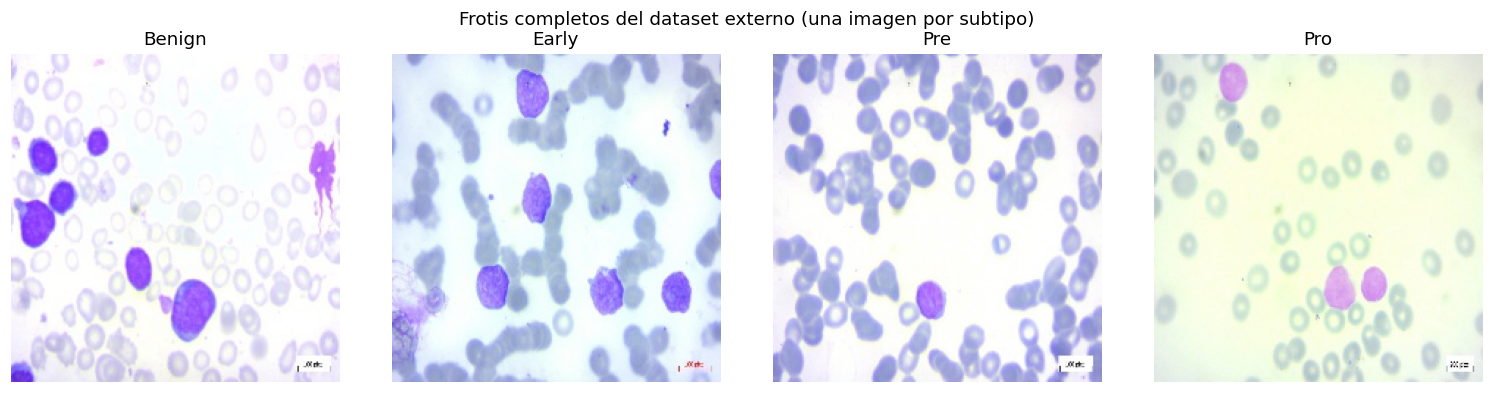

In [37]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
SUBTYPES = {"benign": 0, "early": 1, "pre": 1, "pro": 1}

rows = []
for d in sorted(p for p in ORIG_ROOT.iterdir() if p.is_dir() and p.name.lower() in SUBTYPES):
    for p in sorted(d.iterdir()):
        if p.suffix.lower() in IMG_EXT:
            seg = None
            if SEG_ROOT is not None:
                cand = [c for c in SEG_ROOT.rglob(p.stem + ".*") if c.parent.name.lower() == d.name.lower()]
                seg = str(cand[0]) if cand else None
            rows.append({"path": str(p), "seg_path": seg, "subtipo": d.name.capitalize(), "label": SUBTYPES[d.name.lower()]})
frotis = pd.DataFrame(rows)
if MAX_FROTIS_POR_SUBTIPO:
    idx = [i for _, g in frotis.groupby("subtipo") for i in g.sample(min(len(g), MAX_FROTIS_POR_SUBTIPO), random_state=SEED).index]
    frotis = frotis.loc[idx].reset_index(drop=True)

def load_rgb(path):
    return np.asarray(Image.open(path).convert("RGB"))

sizes = pd.Series([Image.open(p).size for p in frotis.path.sample(min(50, len(frotis)), random_state=SEED)]).value_counts()
max_dim = max(max(s) for s in sizes.index)
YOLO_IMGSZ = int(min(640, max(320, 32 * np.ceil(max_dim / 32))))
print("Imágenes por subtipo:", frotis.subtipo.value_counts().to_dict())
print("Tamaños de imagen:", sizes.to_dict(), "→ YOLO_IMGSZ =", YOLO_IMGSZ)
print("Imágenes con versión segmentada del dataset:", frotis.seg_path.notna().sum())

# Lote A: entrenar YOLO y adaptar el clasificador · Lote B: prueba final del sistema completo
lote_a, lote_b = train_test_split(frotis, test_size=0.5, stratify=frotis.subtipo, random_state=SEED)
a_train, a_val = train_test_split(lote_a, test_size=0.2, stratify=lote_a.subtipo, random_state=SEED)
print(f"Lote A: {len(a_train)} entrenamiento + {len(a_val)} validación · Lote B (prueba): {len(lote_b)}")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (st, g) in zip(axes, frotis.groupby("subtipo")):
    ax.imshow(load_rgb(g.path.iloc[0])); ax.set_title(st); ax.axis("off")
plt.suptitle("Frotis completos del dataset externo (una imagen por subtipo)"); plt.tight_layout()
savefig("frotis_ejemplos"); plt.show()

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    17.1 Pseudo-etiquetas para entrenar YOLO
</h3>
</div>

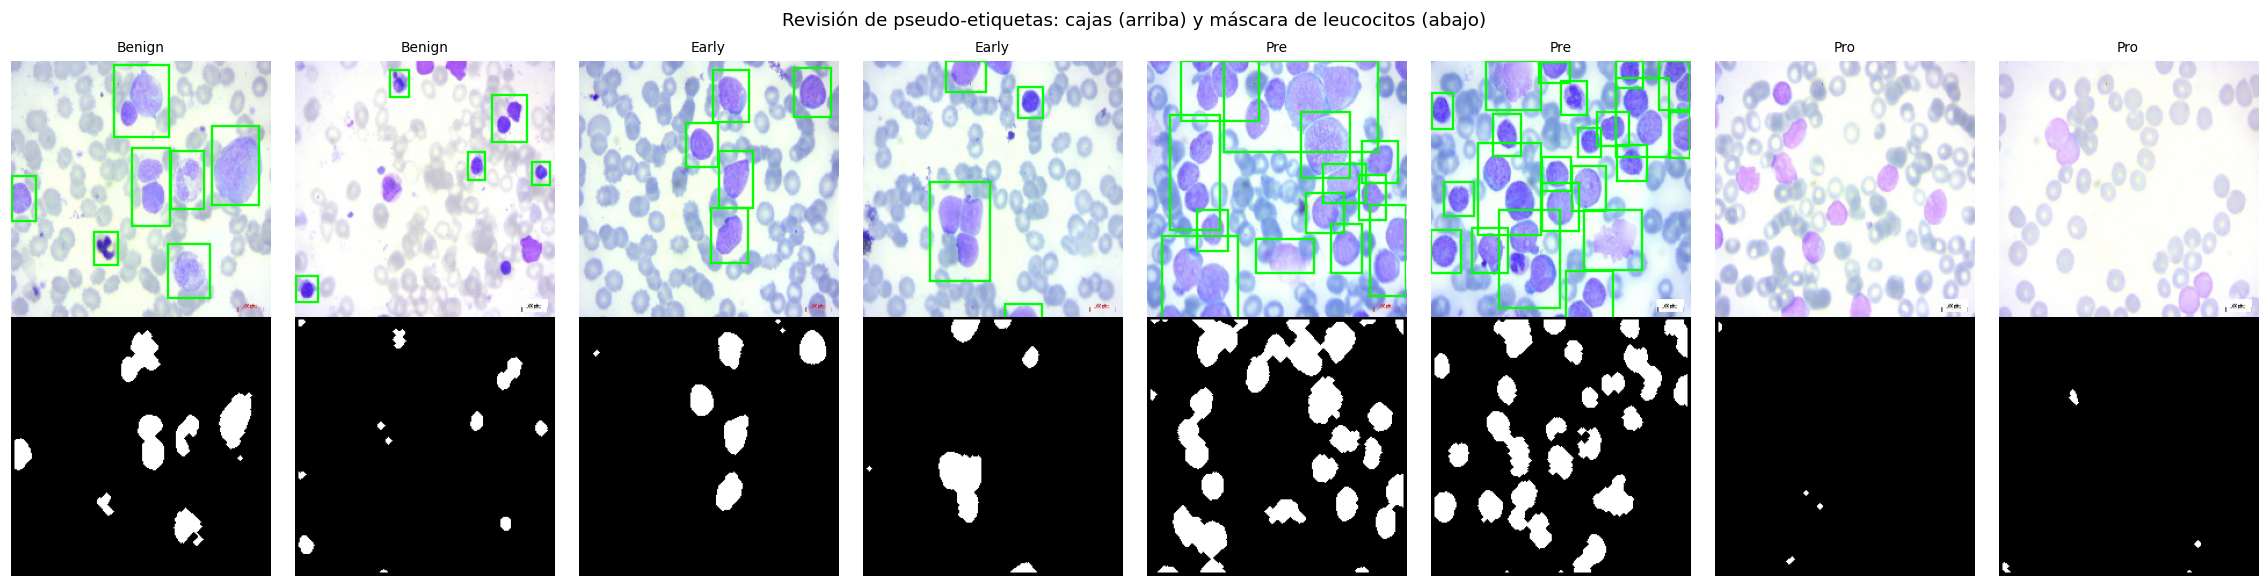

Leucocitos por imagen en el lote A: media 6.8, sin ninguno: 293 imágenes


In [38]:
HUE_RANGE = (0.58, 0.90)   # tono en [0, 1]: azul-violeta-magenta (núcleos teñidos)
MIN_SAT = 0.30             # los glóbulos rojos son menos saturados
MIN_AREA_FRAC = 0.003      # descarta manchas pequeñas (plaquetas, ruido)
BOX_MARGIN = 0.20          # margen alrededor del núcleo para incluir el citoplasma

def clean(mask):
    mask = ndi.binary_opening(mask, iterations=2)
    mask = ndi.binary_closing(mask, iterations=3)
    return ndi.binary_fill_holes(mask)

def hsv_mask(img):
    hsv = np.asarray(Image.fromarray(img).convert("HSV")).astype(np.float32) / 255.0
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    return clean((h >= HUE_RANGE[0]) & (h <= HUE_RANGE[1]) & (s >= MIN_SAT) & (v < 0.9))

def provided_mask(seg_path, shape):
    seg = np.asarray(Image.open(seg_path).convert("RGB").resize(shape[1::-1])).astype(np.int32)
    border = np.concatenate([seg[0], seg[-1], seg[:, 0], seg[:, -1]])
    bg = np.median(border, axis=0)               # color de fondo (negro o blanco)
    return clean(np.abs(seg - bg).sum(axis=2) > 60)

def reference_mask(row, img):
    if isinstance(row.seg_path, str) and os.path.exists(row.seg_path):
        return provided_mask(row.seg_path, img.shape)
    return hsv_mask(img)

def mask_to_boxes(mask, margin=BOX_MARGIN):
    lab, _ = ndi.label(mask)
    H, W = mask.shape
    boxes = []
    for sl in ndi.find_objects(lab):
        y0, y1, x0, x1 = sl[0].start, sl[0].stop, sl[1].start, sl[1].stop
        if (y1 - y0) * (x1 - x0) < MIN_AREA_FRAC * H * W:
            continue
        dy, dx = (y1 - y0) * margin, (x1 - x0) * margin
        boxes.append([max(0, x0 - dx), max(0, y0 - dy), min(W, x1 + dx), min(H, y1 + dy)])
    return boxes

def draw_boxes(ax, img, boxes, color="lime", scores=None):
    ax.imshow(img); ax.axis("off")
    for k, (x0, y0, x1, y1) in enumerate(boxes):
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=color, lw=1.5))
        if scores is not None:
            ax.text(x0, y0, f"{scores[k]:.2f}", color=color, fontsize=7, va="bottom")

qa = frotis.groupby("subtipo", group_keys=False).sample(2, random_state=SEED)
fig, axes = plt.subplots(2, len(qa), figsize=(2.6 * len(qa), 5.4))
for j, (_, r) in enumerate(qa.iterrows()):
    img = load_rgb(r.path); m = reference_mask(r, img)
    draw_boxes(axes[0, j], img, mask_to_boxes(m)); axes[0, j].set_title(r.subtipo, fontsize=9)
    axes[1, j].imshow(m, cmap="gray"); axes[1, j].axis("off")
plt.suptitle("Revisión de pseudo-etiquetas: cajas (arriba) y máscara de leucocitos (abajo)")
plt.tight_layout(); savefig("pseudo_etiquetas"); plt.show()

n_boxes = [len(mask_to_boxes(reference_mask(r, load_rgb(r.path)))) for _, r in lote_a.iterrows()]
print(f"Leucocitos por imagen en el lote A: media {np.mean(n_boxes):.1f}, sin ninguno: {np.sum(np.array(n_boxes) == 0)} imágenes")

In [39]:
# Dataset en formato YOLO: images/{train,val}/*.jpg y labels/{train,val}/*.txt
YOLO_DIR = Path(PIPE_DIR) / "yolo_data"

def write_yolo(df, split):
    img_dir, lbl_dir = YOLO_DIR / "images" / split, YOLO_DIR / "labels" / split
    img_dir.mkdir(parents=True, exist_ok=True); lbl_dir.mkdir(parents=True, exist_ok=True)
    for i, r in df.iterrows():
        img = load_rgb(r.path); H, W = img.shape[:2]
        Image.fromarray(img).save(img_dir / f"{i}.jpg", quality=95)
        with open(lbl_dir / f"{i}.txt", "w") as f:
            for x0, y0, x1, y1 in mask_to_boxes(reference_mask(r, img)):
                f.write(f"0 {(x0 + x1) / 2 / W:.6f} {(y0 + y1) / 2 / H:.6f} {(x1 - x0) / W:.6f} {(y1 - y0) / H:.6f}\n")

write_yolo(a_train, "train"); write_yolo(a_val, "val")
YOLO_YAML = str(YOLO_DIR / "leucocitos.yaml")
with open(YOLO_YAML, "w") as f:
    f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames:\n  0: leucocito\n")
print("Dataset YOLO listo:", YOLO_YAML)

Dataset YOLO listo: /content/resultados/sistema_completo/yolo_data/leucocitos.yaml


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    17.2 Script de YOLO y SAM 2 
</h3>
</div>

TensorFlow y PyTorch pueden chocar si se cargan en el mismo proceso, y además compiten por la memoria de la GPU. Por eso todo lo que usa PyTorch (YOLO y SAM 2) vive en un script que el notebook ejecuta aparte. El script tiene dos modos:
- `train`: entrena YOLO11 con las pseudo-etiquetas y guarda sus métricas.
- `infer`: para cada imagen guarda las cajas de YOLO y las máscaras de SAM 2 en un archivo `.npz`.

In [40]:
%%writefile yolo_sam.py
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image
from ultralytics import YOLO

mode, cfg = sys.argv[1], json.load(open(sys.argv[2]))
pipe = Path(cfg["pipe_dir"])

if mode == "train":
    yolo = YOLO(cfg["yolo_weights"])                      # YOLO11n preentrenado en COCO
    yolo.train(data=cfg["yaml"], epochs=cfg["epochs"], imgsz=cfg["imgsz"], batch=16, seed=cfg["seed"],
               patience=10, project=str(pipe), name="yolo", exist_ok=True, plots=True, verbose=False, workers=2)
    best = YOLO(str(pipe / "yolo" / "weights" / "best.pt"))
    m = best.val(data=cfg["yaml"], imgsz=cfg["imgsz"], verbose=False, plots=False)
    json.dump({"precisión": float(m.box.mp), "sensibilidad": float(m.box.mr),
               "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map)}, open(cfg["metrics_out"], "w"), indent=2)

elif mode == "infer":
    yolo = YOLO(str(pipe / "yolo" / "weights" / "best.pt"))
    try:                                                   # SAM 2.1 de Meta con indicaciones de caja
        from ultralytics.models.sam.predict import SAM2Predictor
        sam = SAM2Predictor(overrides=dict(model=cfg["sam_weights"], save=False, verbose=False))
        def segment(img_bgr, boxes):
            sam.set_image(img_bgr)
            return sam(bboxes=boxes)[0]
        seg_name = cfg["sam_weights"]
    except Exception as e:                                 # respaldo: SAM original
        print("SAM 2 no disponible:", type(e).__name__)
        from ultralytics import SAM
        sam = SAM("sam_b.pt")
        def segment(img_bgr, boxes):
            return sam(img_bgr, bboxes=boxes, verbose=False)[0]
        seg_name = "sam_b.pt"

    times = {"segmentador": seg_name}
    for split, csv in cfg["splits"].items():
        out = Path(cfg["det_dir"]) / split
        out.mkdir(parents=True, exist_ok=True)
        df, t_det, t_sam = pd.read_csv(csv), 0.0, 0.0
        for _, r in df.iterrows():
            img = np.ascontiguousarray(np.asarray(Image.open(r.path).convert("RGB"))[..., ::-1])  # BGR
            t0 = time.time()
            det = yolo.predict(img, imgsz=cfg["imgsz"], conf=0.25, verbose=False)[0]
            t_det += time.time() - t0
            boxes, confs = det.boxes.xyxy.cpu().numpy(), det.boxes.conf.cpu().numpy()
            masks = np.zeros((0,) + img.shape[:2], bool)
            if len(boxes):
                t0 = time.time()
                seg = segment(img, boxes.astype(np.float32))
                t_sam += time.time() - t0
                if seg.masks is not None:
                    masks = seg.masks.data.cpu().numpy().astype(bool)
            np.savez_compressed(out / f"{r.img_idx}.npz", boxes=boxes, confs=confs, masks=masks)
        n = max(len(df), 1)
        times[split] = {"YOLO (ms/imagen)": 1000 * t_det / n, "SAM 2 (ms/imagen)": 1000 * t_sam / n}
        print(f"{split}: {len(df)} imágenes procesadas")
    json.dump(times, open(pipe / "tiempos.json", "w"), indent=2)

Writing yolo_sam.py


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    17.3 Entrenamiento del detector YOLO11  
</h3>
</div>

Partimos de YOLO11n preentrenado en COCO (transfer learning) y lo ajustamos para una sola clase: `leucocito`. YOLO trae su propio aumento de datos (mosaico, volteos, cambios de color HSV).

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/resultados/sistema_completo/yolo_data/leucocitos.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_

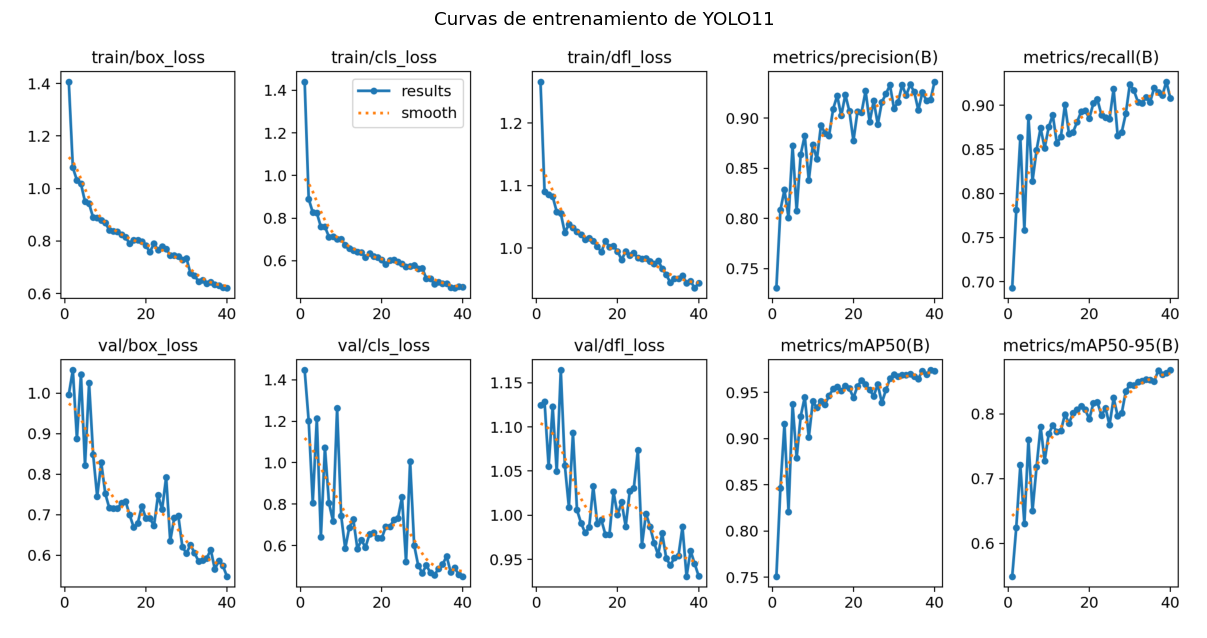

In [41]:
DET_DIR = Path(PIPE_DIR) / "deteccion"
CFG_PATH = f"{PIPE_DIR}/config_yolo_sam.json"
cfg = {"pipe_dir": PIPE_DIR, "yaml": YOLO_YAML, "yolo_weights": YOLO_WEIGHTS, "sam_weights": SAM_WEIGHTS,
       "epochs": YOLO_EPOCHS, "imgsz": YOLO_IMGSZ, "seed": SEED, "det_dir": str(DET_DIR),
       "metrics_out": f"{PIPE_DIR}/yolo_metricas.json", "splits": {}}
for name, df in {"a_train": a_train, "a_val": a_val, "lote_b": lote_b}.items():
    csv = f"{PIPE_DIR}/split_{name}.csv"
    df[["path"]].rename_axis("img_idx").reset_index().to_csv(csv, index=False)
    cfg["splits"][name] = csv
json.dump(cfg, open(CFG_PATH, "w"), indent=2)

with EnergyMeter("yolo11_leucocitos"):
    !{sys.executable} yolo_sam.py train {CFG_PATH}

YOLO_METRICS = json.load(open(cfg["metrics_out"]))
print("YOLO en validación (contra pseudo-etiquetas):", {k: round(v, 3) for k, v in YOLO_METRICS.items()})
curves = Path(PIPE_DIR) / "yolo" / "results.png"
if curves.exists():
    plt.figure(figsize=(14, 7)); plt.imshow(Image.open(curves)); plt.axis("off")
    plt.title("Curvas de entrenamiento de YOLO11"); plt.show()

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    17.4 Segmentación con SAM 2 y recortes "estilo C-NMC"
</h3>
</div>

Para cada caja de YOLO, SAM 2 devuelve la máscara exacta de la célula. Con ella construimos un recorte parecido a los de C-NMC:
- La célula sobre **fondo negro**.
- La célula ocupa **la misma fracción de la imagen** que en C-NMC (usamos la mediana medida en el EDA, sección 4.3).

Así reducimos la diferencia entre lo que el clasificador vio al entrenar y lo que recibe ahora.

In [42]:
with EnergyMeter("yolo_sam_inferencia"):
    !{sys.executable} yolo_sam.py infer {CFG_PATH}
TIEMPOS = json.load(open(Path(PIPE_DIR) / "tiempos.json"))
print("Segmentador usado:", TIEMPOS["segmentador"])

TARGET_AREA_FRAC = float(props.area_frac.median())   # tamaño relativo de una célula en C-NMC (sección 4.3)

def load_det(split, i, shape):
    d = np.load(DET_DIR / split / f"{i}.npz")
    masks = [m if m.shape == shape else np.asarray(Image.fromarray(m).resize(shape[::-1])) for m in d["masks"]]
    return d["boxes"].tolist(), d["confs"].tolist(), masks

def cnmc_style_crop(img_rgb, mask, out_size=450):
    ys, xs = np.nonzero(mask)
    if len(ys) < 20:
        return None
    side = max(int(np.sqrt(mask.sum() / TARGET_AREA_FRAC)), 8)
    y0, x0 = int(round(ys.mean() - side / 2)), int(round(xs.mean() - side / 2))
    cell = np.where(mask[..., None], img_rgb, 0).astype(np.uint8)
    canvas = np.zeros((side, side, 3), np.uint8)
    H, W = mask.shape
    sy0, sx0, sy1, sx1 = max(0, y0), max(0, x0), min(H, y0 + side), min(W, x0 + side)
    canvas[sy0 - y0:sy1 - y0, sx0 - x0:sx1 - x0] = cell[sy0:sy1, sx0:sx1]
    return np.asarray(Image.fromarray(canvas).resize((out_size, out_size), Image.BILINEAR))

def build_cells(df, split):
    crop_dir = Path(PIPE_DIR) / "recortes" / split
    crop_dir.mkdir(parents=True, exist_ok=True)
    cells, imgs = [], []
    for i, r in df.iterrows():
        img = load_rgb(r.path)
        boxes, confs, masks = load_det(split, i, img.shape[:2])
        ref = reference_mask(r, img)
        for k, (b, c, m) in enumerate(zip(boxes, confs, masks)):
            crop = cnmc_style_crop(img, m)
            if crop is None:
                continue
            cp = crop_dir / f"{i}_{k}.png"
            Image.fromarray(crop).save(cp)
            x0, y0, x1, y1 = (int(v) for v in b)
            rb = ref[y0:y1, x0:x1]
            cells.append({"img_idx": i, "path": str(cp), "label": r.label, "subtipo": r.subtipo, "conf_yolo": c,
                          "cobertura_nucleo": (rb & m[y0:y1, x0:x1]).sum() / max(rb.sum(), 1)})
        imgs.append({"img_idx": i, "path": r.path, "label": r.label, "subtipo": r.subtipo, "n_leucocitos": len(boxes)})
    return pd.DataFrame(cells), pd.DataFrame(imgs)

cells_a_tr, imgs_a_tr = build_cells(a_train, "a_train")
cells_a_va, imgs_a_va = build_cells(a_val, "a_val")
cells_b, imgs_b = build_cells(lote_b, "lote_b")
print(f"Lote B: {len(cells_b)} leucocitos recortados en {len(imgs_b)} imágenes "
      f"(media {imgs_b.n_leucocitos.mean():.1f} por imagen; {int((imgs_b.n_leucocitos == 0).sum())} imágenes sin detecciones)")
if len(cells_b):
    print(f"Cobertura del núcleo de referencia por la máscara de SAM 2: mediana {cells_b.cobertura_nucleo.median():.2f}")

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
a_train: 1302 imágenes procesadas
a_val: 326 imágenes procesadas
lote_b: 1628 imágenes procesadas
Segmentador usado: sam2.1_b.pt
Lote B: 13327 leucocitos recortados en 1628 imágenes (media 8.2 por imagen; 311 imágenes sin detecciones)
Cobertura del núcleo de referencia por la máscara de SAM 2: mediana 1.00



<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    17.5 Diagnóstico por imagen en el lote de prueba
</h3>
</div>

Cada imagen recibe la **probabilidad máxima** entre sus leucocitos: basta un blasto convincente para marcar el frotis como sospechoso. Comparamos tres versiones del sistema:

| Versión | Qué cambia | Para qué |
|---|---|---|
| **A. Sin adaptar** | Clasificador y umbral tal como salieron de C-NMC | Mide cuánto cae el rendimiento al cambiar de hospital (**cambio de dominio**) |
| **B. Umbral recalibrado** | Mismo modelo; el umbral se elige con el lote A de validación | La solución más barata: calibrar con pocas láminas locales |
| **C. Ajuste fino local** | El clasificador se reentrena unas épocas con recortes del lote A | Lo que haría un hospital antes de usar el sistema (fase 0 del plan de la sección 15) |

Ninguna versión ve el lote B antes de esta evaluación.

In [43]:
def image_scores(cells, imgs, p):
    c = cells.assign(p=p)
    agg = c.groupby("img_idx").agg(p_max=("p", "max"))
    return imgs.set_index("img_idx").join(agg).fillna({"p_max": 0.0})   # sin leucocitos → no sospechoso

def predict_cells(model, cells):
    return model.predict(make_dataset(cells), verbose=0).ravel() if len(cells) else np.array([])

base_model = MODELS[MAIN]
SYS = {}

# A. Sin adaptar
sb = image_scores(cells_b, imgs_b, predict_cells(base_model, cells_b))
SYS["A. Sin adaptar"] = (sb, T_MAIN)

# B. Umbral recalibrado con el lote A de validación
sv = image_scores(cells_a_va, imgs_a_va, predict_cells(base_model, cells_a_va))
SYS["B. Umbral recalibrado"] = (sb, choose_thresholds(sv.label, sv.p_max)["Youden"])

# C. Ajuste fino con los recortes del lote A de entrenamiento (etiqueta débil: la de la imagen)
set_seed()
ft_model = keras.models.clone_model(base_model)
ft_model.set_weights(base_model.get_weights())
ft_model.compile(keras.optimizers.AdamW(1e-5, weight_decay=1e-4), loss="binary_crossentropy", metrics=compile_metrics())
with EnergyMeter("ajuste_fino_local"):
    ft_model.fit(make_dataset(cells_a_tr, training=True), epochs=FINETUNE_EPOCHS,
                 class_weight=class_weights(cells_a_tr), verbose=2)
sv_ft = image_scores(cells_a_va, imgs_a_va, predict_cells(ft_model, cells_a_va))
sb_ft = image_scores(cells_b, imgs_b, predict_cells(ft_model, cells_b))
SYS["C. Ajuste fino local"] = (sb_ft, choose_thresholds(sv_ft.label, sv_ft.p_max)["Youden"])

sys_table = pd.DataFrame({name: compute_metrics(s.label.values, s.p_max.values, t) for name, (s, t) in SYS.items()}).T
display(sys_table.round(3))
sys_table.to_csv(f"{PIPE_DIR}/metricas_sistema_completo.csv")
BEST_SYS = sys_table["ROC-AUC"].idxmax()
print("Mejor versión en el lote B:", BEST_SYS)

Epoch 1/5
323/323 - 23s - 70ms/step - acc: 0.6630 - auc: 0.6782 - loss: 0.6983 - pr_auc: 0.9014 - precision: 0.9019 - recall: 0.6738
Epoch 2/5
323/323 - 3s - 10ms/step - acc: 0.7134 - auc: 0.8000 - loss: 0.5445 - pr_auc: 0.9477 - precision: 0.9373 - recall: 0.7076
Epoch 3/5
323/323 - 3s - 10ms/step - acc: 0.7403 - auc: 0.8438 - loss: 0.4960 - pr_auc: 0.9583 - precision: 0.9496 - recall: 0.7309
Epoch 4/5
323/323 - 3s - 10ms/step - acc: 0.7576 - auc: 0.8674 - loss: 0.4624 - pr_auc: 0.9670 - precision: 0.9597 - recall: 0.7439
Epoch 5/5
323/323 - 3s - 10ms/step - acc: 0.7803 - auc: 0.8896 - loss: 0.4313 - pr_auc: 0.9719 - precision: 0.9648 - recall: 0.7675


,umbral,exactitud,exactitud balanceada,sensibilidad,especificidad,precisión (VPP),F1,F1 ponderado,MCC,ROC-AUC,PR-AUC
A. Sin adaptar,0.787,0.159,0.464,0.023,0.905,0.564,0.043,0.075,-0.146,0.302,0.769
B. Umbral recalibrado,0.884,0.157,0.490,0.008,0.972,0.611,0.016,0.054,-0.068,0.302,0.769
C. Ajuste fino local,0.871,0.588,0.735,0.522,0.948,0.982,0.682,0.640,0.342,0.709,0.949


Mejor versión en el lote B: C. Ajuste fino local


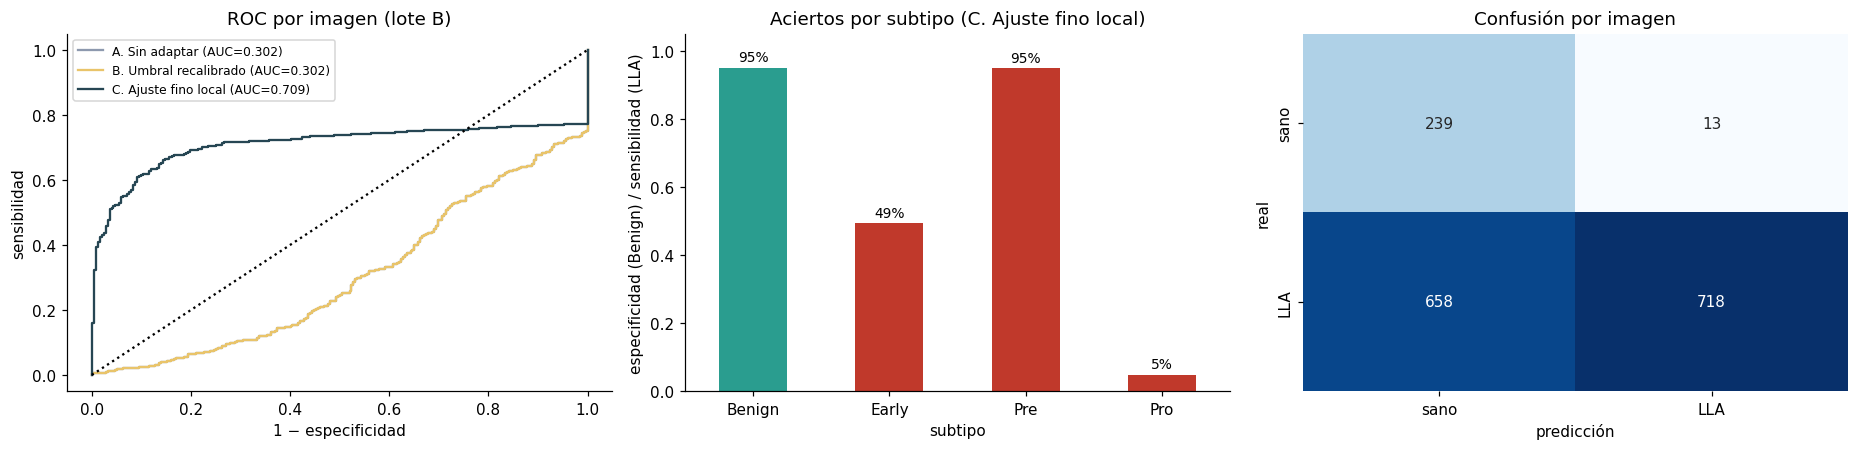

In [44]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for (name, (s, t)), c in zip(SYS.items(), ["#8d99ae", "#e9c46a", "#264653"]):
    fpr, tpr, _ = skm.roc_curve(s.label, s.p_max)
    ax[0].plot(fpr, tpr, c=c, label=f"{name} (AUC={skm.roc_auc_score(s.label, s.p_max):.3f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set(title="ROC por imagen (lote B)", xlabel="1 − especificidad", ylabel="sensibilidad")
ax[0].legend(fontsize=8)

s, t = SYS[BEST_SYS]
pred = (s.p_max >= t).astype(int)
by_sub = s.assign(acierto=(pred == s.label)).groupby("subtipo").acierto.mean().reindex(["Benign", "Early", "Pre", "Pro"])
by_sub.plot.bar(ax=ax[1], rot=0, color=["#2a9d8f", "#c0392b", "#c0392b", "#c0392b"])
ax[1].set(title=f"Aciertos por subtipo ({BEST_SYS})", ylabel="especificidad (Benign) / sensibilidad (LLA)", ylim=(0, 1.05))
for k, v in enumerate(by_sub.values):
    ax[1].text(k, v + .02, f"{v:.0%}", ha="center", fontsize=9)

sns.heatmap(skm.confusion_matrix(s.label, pred, labels=[0, 1]), annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax[2],
            xticklabels=["sano", "LLA"], yticklabels=["sano", "LLA"])
ax[2].set(title="Confusión por imagen", xlabel="predicción", ylabel="real")
plt.tight_layout(); savefig("sistema_completo_resultados"); plt.show()

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    17.6 El sistema completo, paso a paso
</h3>
</div>

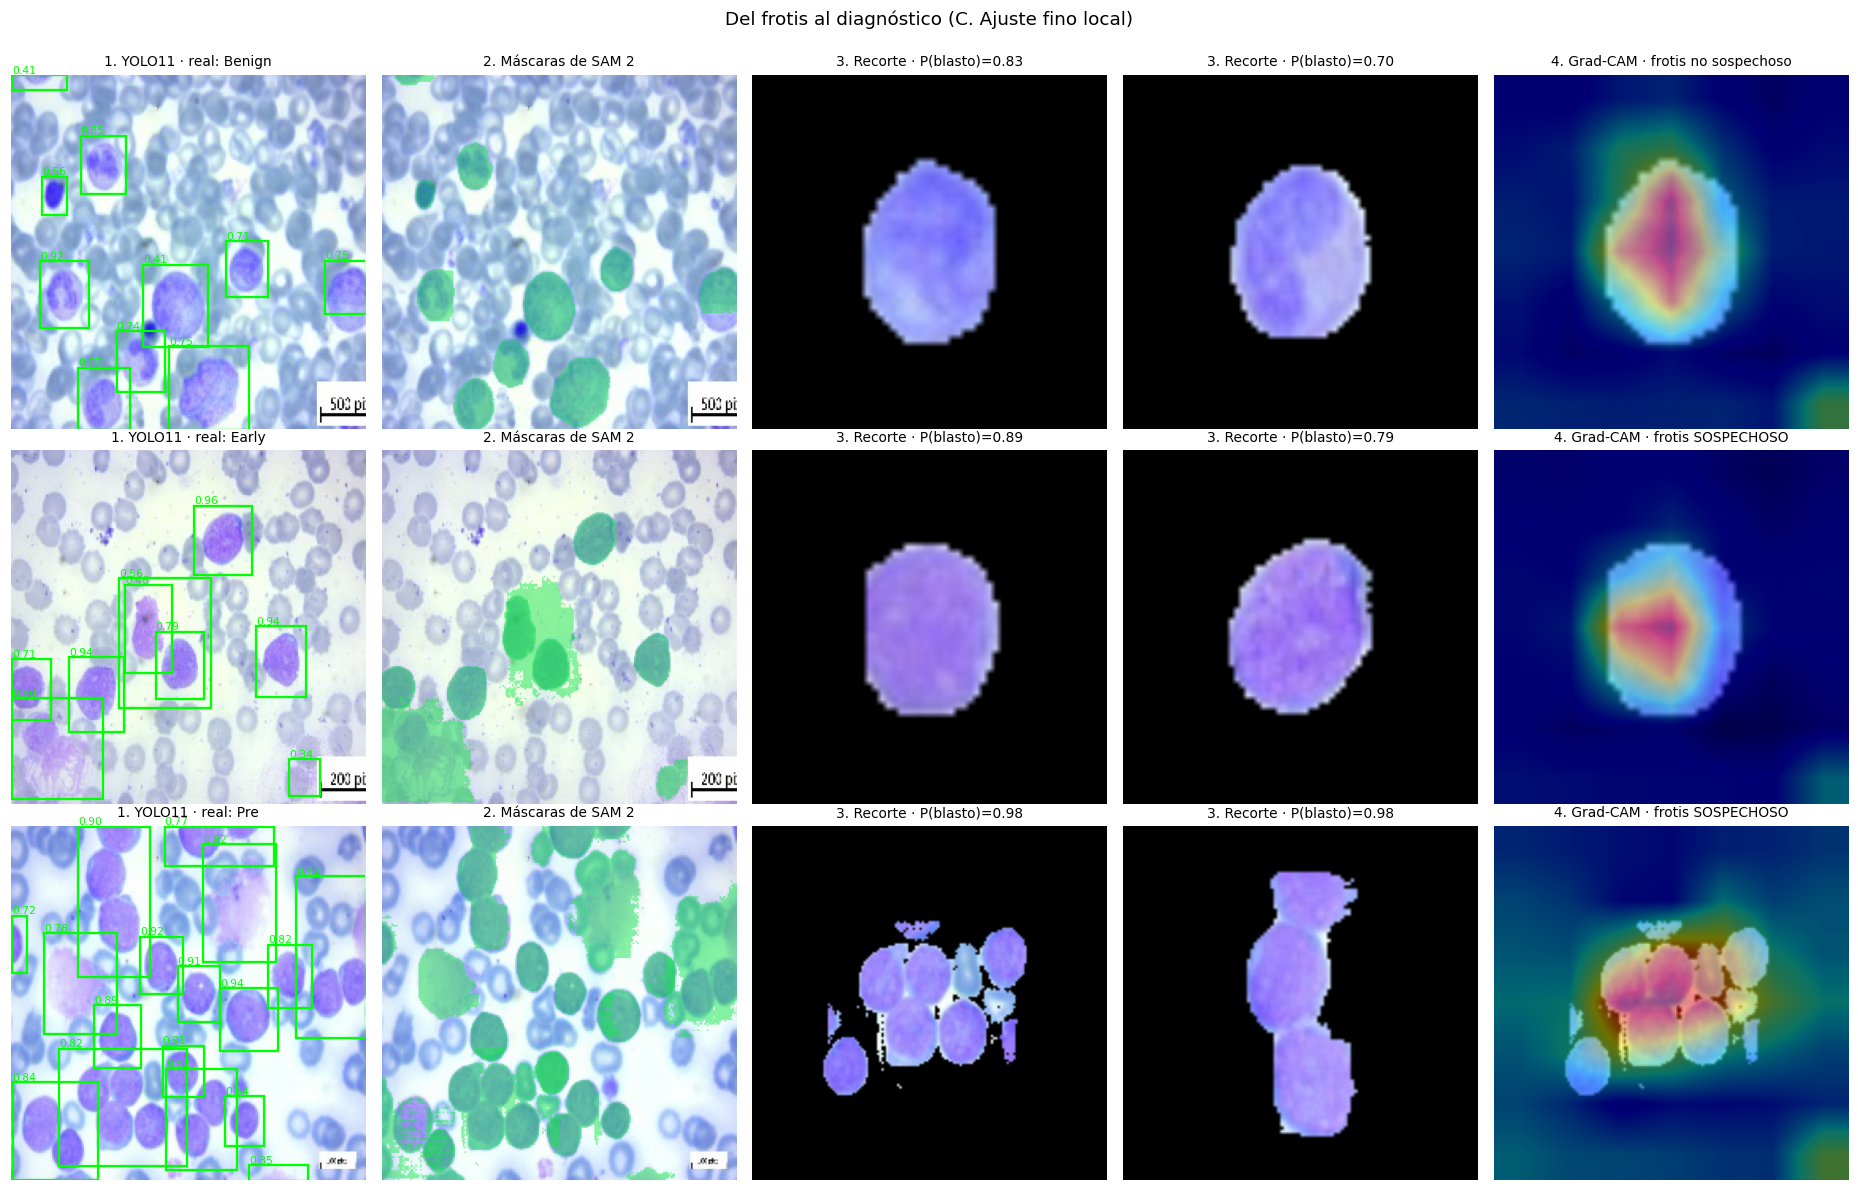

In [45]:
best_model = ft_model if BEST_SYS.startswith("C") else base_model
s_best, t_best = SYS[BEST_SYS]
demo_imgs = imgs_b[imgs_b.n_leucocitos > 0].groupby("subtipo", group_keys=False).sample(1, random_state=SEED).head(3)
cells_b_scored = cells_b.assign(p=predict_cells(best_model, cells_b))

fig, axes = plt.subplots(len(demo_imgs), 5, figsize=(17, 3.6 * len(demo_imgs)), squeeze=False)
for row, (_, r) in enumerate(demo_imgs.iterrows()):
    img = load_rgb(r.path)
    boxes, confs, masks = load_det("lote_b", r.img_idx, img.shape[:2])
    draw_boxes(axes[row, 0], img, boxes, scores=confs)
    axes[row, 0].set_title(f"1. YOLO11 · real: {r.subtipo}", fontsize=9)
    over = img.astype(float) / 255
    for m in masks:
        over[m] = 0.5 * over[m] + 0.5 * np.array([0.1, 0.9, 0.3])
    axes[row, 1].imshow(over); axes[row, 1].axis("off"); axes[row, 1].set_title("2. Máscaras de SAM 2", fontsize=9)
    mine = cells_b_scored[cells_b_scored.img_idx == r.img_idx].sort_values("p", ascending=False).head(2)
    for j in range(2):
        a = axes[row, 2 + j]; a.axis("off")
        if j < len(mine):
            a.imshow(Image.open(mine.path.iloc[j])); a.set_title(f"3. Recorte · P(blasto)={mine.p.iloc[j]:.2f}", fontsize=9)
    a = axes[row, 4]; a.axis("off")
    if len(mine):
        crop = load_image(mine.path.iloc[0], IMG_SIZE).numpy()
        cam, _ = grad_cam(best_model, GRADCAM_LAYER[MAIN], crop)
        a.imshow(overlay(crop, cam))
        verdict = "SOSPECHOSO" if s_best.loc[r.img_idx, "p_max"] >= t_best else "no sospechoso"
        a.set_title(f"4. Grad-CAM · frotis {verdict}", fontsize=9)
plt.suptitle(f"Del frotis al diagnóstico ({BEST_SYS})", y=1.0)
plt.tight_layout(); savefig("sistema_completo_paso_a_paso"); plt.show()

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    17.7 Tiempo por frotis y costo computacional
</h3>
</div>

In [46]:
ms_clf = eff.loc[MAIN, "ms por imagen (lote 32)"]
t = TIEMPOS.get("lote_b", {})
tiempos = pd.Series({**t, "Clasificador (ms/imagen)": ms_clf * imgs_b.n_leucocitos.mean()})
tiempos["TOTAL (ms/imagen)"] = tiempos.sum()
display(tiempos.round(1).to_frame("milisegundos"))
print(f"Un frotis de {CELULAS_POR_LAMINA} leucocitos repartidos en ~{CELULAS_POR_LAMINA / max(imgs_b.n_leucocitos.mean(), 1):.0f} fotos "
      f"tardaría ~{tiempos['TOTAL (ms/imagen)'] * CELULAS_POR_LAMINA / max(imgs_b.n_leucocitos.mean(), 1) / 1000:.0f} s en este hardware.")
display(pd.DataFrame(ENERGY_LOG).round(5))

,milisegundos
YOLO (ms/imagen),3.4
SAM 2 (ms/imagen),11.7
Clasificador (ms/imagen),12.0
TOTAL (ms/imagen),27.1


Un frotis de 200 leucocitos repartidos en ~24 fotos tardaría ~1 s en este hardware.


,experimento,minutos,kWh,kg CO2eq
0,cnn_base,1.67574,0.00927,0.00240
1,grid_0,0.80689,0.00273,0.00071
2,grid_1,0.72256,0.00252,0.00065
3,grid_2,0.57832,0.00217,0.00056
4,grid_3,0.57863,0.00216,0.00056
5,effnet_cabeza,0.52608,0.00191,0.00050
6,effnet_finetune,0.94923,0.00384,0.00100
7,yolo11_leucocitos,1.76457,0.00617,0.00160
8,yolo_sam_inferencia,0.99638,0.00534,0.00138
9,ajuste_fino_local,0.59289,0.00218,0.00057


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    17.8 Interpretación y límites del sistema completo
</div>

**Lo que funcionó:**
- **YOLO11** alcanzó una precisión de 0,937, una sensibilidad de 0,907, un mAP50 de 0,973 y un mAP50-95 de 0,869 frente a las pseudo-etiquetas. Ojo: mide qué tan bien imita las pseudo-etiquetas, no a un experto.
- **SAM 2.1** cubrió el núcleo de referencia por completo (cobertura mediana 1,00).
- **Velocidad:** el sistema completo tarda ~27 ms por foto (YOLO 3,4 ms, SAM 2 11,7 ms, clasificador 12,0 ms); un frotis de ~200 leucocitos, ~1 s.

**Límites:**
- YOLO aprendió de pseudo-etiquetas de color, no de cajas dibujadas por expertos.
- La partición es por imagen, no por paciente, porque el dataset no trae el ID del paciente.
- Las etiquetas por célula son débiles: en una imagen de LLA no todos los leucocitos tienen que ser blastos.

**Mejoras:**
- Un detector que vea las células rosadas: el detector por croma de la sección 19.4 deja de perder imágenes; o entrenar YOLO con cajas de expertos (Raabin-WBC).
- Normalizar la tinción antes de clasificar.
- Validar con datos de otro hospital que traigan ID de paciente y la misma tinción en sanos y enfermos.
- Validar con datos pediátricos (sección 1.8).

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">


<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        18. Mejoras del clasificador
    </h2>
</div>

| Problema encontrado | Evidencia | Mejora que probamos |
|---|---|---|
| Se pierde el detalle de la célula | Reducimos 450 → 224 px; la literatura trabaja a resolución nativa | **Recorte central de 300 px sin reducir** (como Mondal et al.) |
| El modelo usa el **tamaño** como atajo | Área 0,180 vs 0,124; 55–65% de error en las sanas que no son las más pequeñas; Grad-CAM mira el fondo | **Normalización de tamaño:** cada célula se recorta a su contorno y llena la imagen |
| Generaliza mal a pacientes nuevos | Validación ~0,89 vs prueba 0,780 | Receta de entrenamiento moderna, **Xception**, **ConvNeXt-Tiny**, *test-time augmentation* y **ensambles** |

**Reglas del experimento:**
- Todo se elige con la **validación por paciente**. La prueba externa se reporta para todas las variantes, pero no se usa para elegir.
- Cada variante cambia una cosa respecto a otra, así se sabe qué aporta cada mejora (estudio de ablación).


In [47]:
# ======================= CONFIGURACIÓN DE LAS MEJORAS =======================
IMP_IMG_SIZE = 300          # tamaño de entrada de la red (la literatura usa 300)
CROP_PX = 300               # recorte central a resolución nativa (de los 450×450 originales)
IMP_EPOCHS_HEAD = 3         # etapa 1: solo la cabeza
IMP_EPOCHS_FT = 25          # etapa 2: ajuste fino completo (con parada temprana)
PATIENCE_V2 = 6
IMP_BACKBONES = ["xception", "convnext_tiny"]   # además de EfficientNet-B0, que se usa en la ablación
LR_FT = {"efficientnet_b0": 2e-4, "xception": 1e-4, "convnext_tiny": 5e-5}
WD_FT = {"efficientnet_b0": 1e-4, "xception": 1e-4, "convnext_tiny": 0.05}
LABEL_SMOOTHING = 0.05
SIZE_MARGIN = 0.06          # margen alrededor de la célula al recortar
CV_FOLDS = 3                # modelos del ensamble por validación cruzada de pacientes (0 = sin ensamble)
TTA = True                  # promedio de 8 versiones (giros y espejos) de cada imagen al predecir
STAIN_AUG = True            # V9: aumento de tinción (simula el color de otros laboratorios)
STAIN_SIGMA = 0.08          # intensidad del aumento de tinción (0,05 = suave, 0,2 = fuerte)

if FAST_MODE:
    IMP_IMG_SIZE, CROP_PX, IMP_EPOCHS_HEAD, IMP_EPOCHS_FT, CV_FOLDS = 96, 300, 1, 1, 2


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    18.1 Tres formas de preparar la entrada
</div>

| Modo | Qué hace | Conserva el tamaño | Resolución sobre la célula |
|---|---|---|---|
| `resize` | Imagen completa de 450 reducida a `IMP_IMG_SIZE` (lo que hacíamos) | Sí | Baja |
| `crop` | **Recorte central de 300×300** sin reducir (como la literatura) | Sí | **Nativa** |
| `norm` | **Normalización de tamaño**: recorte a la célula y reescalado | **No** | Nativa o mayor |

**Aumento de tinción:** cada laboratorio tiñe distinto, y esa es una de las razones por las que el modelo falla en las láminas de Irán. Durante el entrenamiento convertimos cada imagen a densidad óptica, la separamos en canales de colorante con la deconvolución de color de Ruifrok y Johnston (2001) y escalamos y desplazamos cada canal al azar (Tellez et al., 2018). Así el modelo ve muchas "tinciones" distintas de la misma célula. Usamos la matriz estándar de hematoxilina-eosina como aproximación: la tinción de Giemsa tiene otros colorantes, pero la perturbación en densidad óptica simula igual cambios de concentración e intensidad.

**Normalización de tamaño:** para cada imagen buscamos la caja que encierra la célula (píxeles que no son fondo negro), la hacemos cuadrada con un pequeño margen y la reescalamos a `IMP_IMG_SIZE`. Así todas las células ocupan el mismo espacio: **el tamaño absoluto deja de estar disponible** y la red tiene que decidir por la forma del núcleo, la cromatina y la relación núcleo/citoplasma.

Se recorta desde la imagen original de 450×450, antes de reducirla, para no perder detalle.

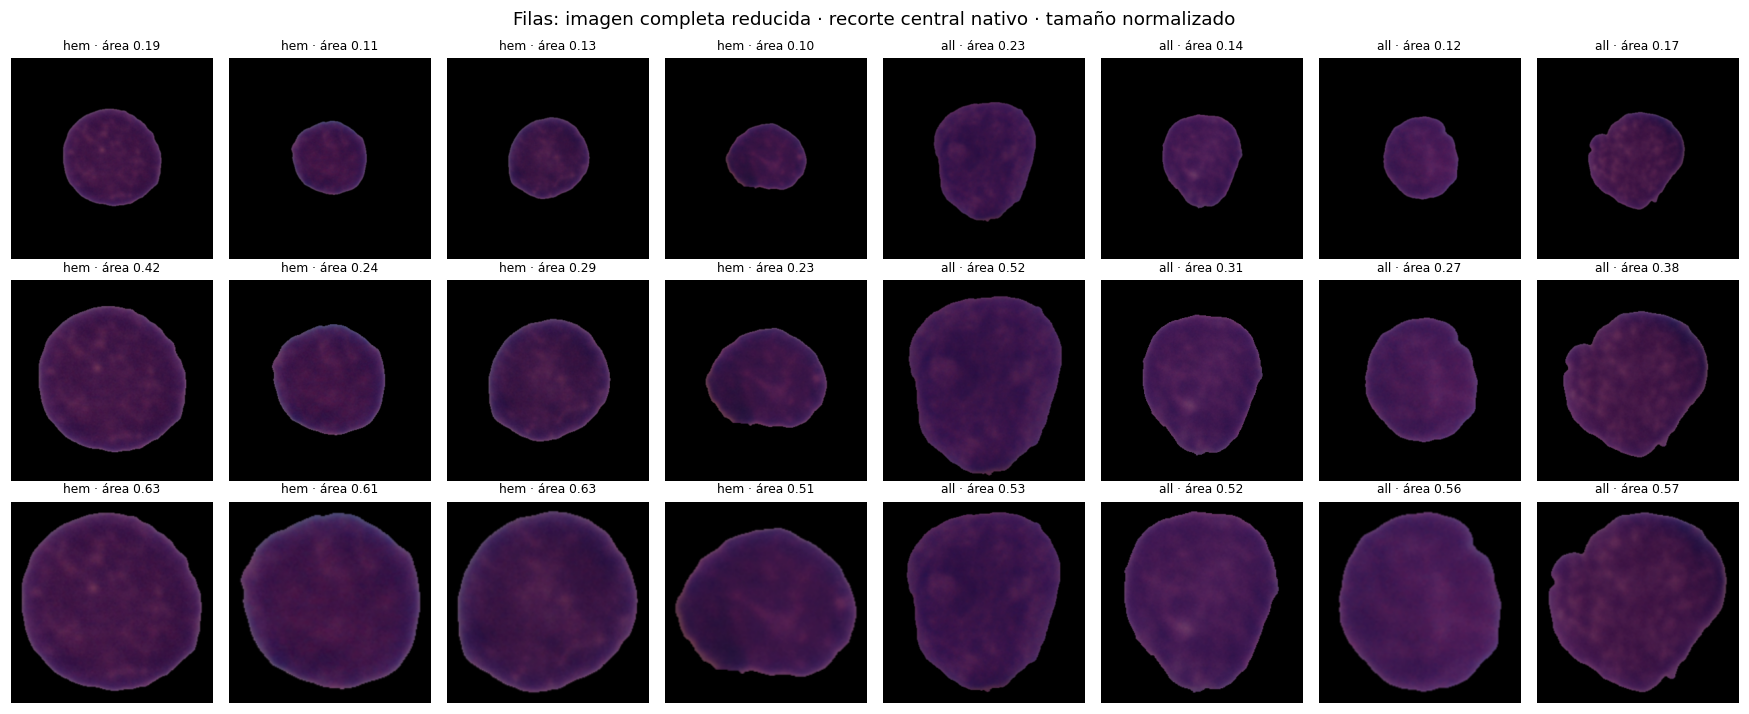

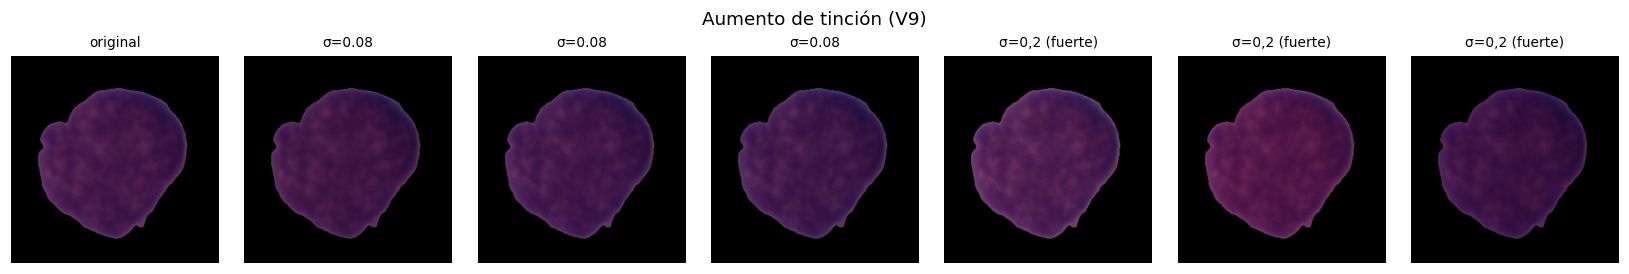

AUC usando SOLO el área (original): 0.855  (0,5 = el tamaño no dice nada)
AUC usando SOLO el área (normalizada): 0.444  (0,5 = el tamaño no dice nada)


In [48]:
def size_normalize(img, out_size, margin=SIZE_MARGIN, thr=12):
    # Recorta la célula a un cuadrado alrededor de su contorno y la reescala a out_size×out_size
    img = tf.convert_to_tensor(img)
    mask = tf.reduce_max(tf.cast(img, tf.int32), axis=-1) > thr
    rows = tf.cast(tf.where(tf.reduce_sum(tf.cast(mask, tf.int32), axis=1) > 2)[:, 0], tf.int32)
    cols = tf.cast(tf.where(tf.reduce_sum(tf.cast(mask, tf.int32), axis=0) > 2)[:, 0], tf.int32)

    def _crop():
        y0, y1, x0, x1 = rows[0], rows[-1] + 1, cols[0], cols[-1] + 1
        side = tf.maximum(y1 - y0, x1 - x0)
        side = side + 2 * tf.cast(tf.cast(side, tf.float32) * margin, tf.int32)
        cy, cx = (y0 + y1) // 2, (x0 + x1) // 2
        padded = tf.pad(img, [[side, side], [side, side], [0, 0]])     # fondo negro alrededor
        top, left = cy - side // 2 + side, cx - side // 2 + side
        return padded[top:top + side, left:left + side]

    ok = tf.logical_and(tf.size(rows) > 0, tf.size(cols) > 0)
    out = tf.cond(ok, _crop, lambda: img)
    out = tf.image.resize(out, (out_size, out_size), antialias=True)
    return tf.cast(tf.clip_by_value(out, 0, 255), tf.uint8)

def load_image_norm(path, img_size):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return size_normalize(img, img_size)

def load_image_crop(path, img_size):
    # Recorte central a resolución nativa: quita borde negro sin reducir la célula
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize_with_crop_or_pad(img, CROP_PX, CROP_PX)
    if img_size != CROP_PX:
        img = tf.cast(tf.clip_by_value(tf.image.resize(img, (img_size, img_size), antialias=True), 0, 255), tf.uint8)
    return img

LOADERS = {"resize": load_image, "crop": load_image_crop, "norm": load_image_norm}
MODE_NAMES = {"resize": "imagen completa reducida", "crop": "recorte central nativo", "norm": "tamaño normalizado"}

augmenter_v2 = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.5, fill_mode="constant", fill_value=0.0),
    layers.RandomZoom((-0.12, 0.08), fill_mode="constant", fill_value=0.0),
    layers.RandomTranslation(0.04, 0.04, fill_mode="constant", fill_value=0.0),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.12, value_range=(0, 255)),
], name="aumento_v2")

def color_jitter_batch(x):
    # Tono y saturación aleatorios distintos para cada imagen del lote (simula variaciones de tinción)
    hsv = tf.image.rgb_to_hsv(x / 255.0)
    n = tf.shape(x)[0]
    dh = tf.random.uniform([n, 1, 1], -0.03, 0.03)
    ds_ = tf.random.uniform([n, 1, 1], 0.85, 1.15)
    hsv = tf.stack([tf.math.floormod(hsv[..., 0] + dh, 1.0), tf.clip_by_value(hsv[..., 1] * ds_, 0, 1), hsv[..., 2]], -1)
    return tf.image.hsv_to_rgb(hsv) * 255.0

# Aumento de tinción en el espacio de colorantes (densidad óptica). El fondo negro no se toca.
RGB_FROM_HED = np.array([[0.65, 0.70, 0.29], [0.07, 0.99, 0.11], [0.27, 0.57, 0.78]], np.float32)
HED_FROM_RGB = np.linalg.inv(RGB_FROM_HED).astype(np.float32)

def stain_jitter_batch(x, sigma=None):
    sigma = STAIN_SIGMA if sigma is None else sigma
    bg = tf.reduce_max(x, axis=-1, keepdims=True) < 12.0
    od = -tf.math.log((x + 1.0) / 256.0)                      # densidad óptica
    hed = tf.einsum("bhwc,cd->bhwd", od, HED_FROM_RGB)        # canales de colorante
    n = tf.shape(x)[0]
    alpha = tf.random.uniform([n, 1, 1, 3], 1 - sigma, 1 + sigma)
    beta = tf.random.uniform([n, 1, 1, 3], -sigma, sigma)
    od2 = tf.einsum("bhwd,dc->bhwc", hed * alpha + beta, RGB_FROM_HED)
    out = tf.clip_by_value(256.0 * tf.exp(-od2) - 1.0, 0.0, 255.0)
    return tf.where(bg, x, out)

# Banco de imágenes: cada imagen se lee y se recorta UNA sola vez y queda en RAM como uint8.
# Todas las variantes y los folds de validación cruzada comparten el mismo arreglo (sin copias),
# lo que evita llenar la memoria de Colab con un caché por cada entrenamiento.
BANKS = {}

def get_bank(mode, img_size=None):
    img_size = img_size or IMP_IMG_SIZE
    key = (mode, img_size)
    if key not in BANKS:
        df_all = pd.concat([train_df, test_df], ignore_index=True)
        loader = LOADERS[mode]
        X = np.empty((len(df_all), img_size, img_size, 3), np.uint8)
        ds = tf.data.Dataset.from_tensor_slices(df_all.path.values) \
               .map(lambda p: loader(p, img_size), num_parallel_calls=AUTOTUNE).batch(256)
        k = 0
        for b in ds:
            X[k:k + len(b)] = b.numpy(); k += len(b)
        BANKS[key] = {"X": X, "index": {p: i for i, p in enumerate(df_all.path.values)}}
        print(f"Banco de imágenes ({MODE_NAMES[mode]}, {img_size}px): {X.nbytes / 1e9:.2f} GB en RAM")
    return BANKS[key]

def release_bank(mode, img_size=None):
    BANKS.pop((mode, img_size or IMP_IMG_SIZE), None); gc.collect()

def make_dataset_v2(df, training=False, mode="norm", img_size=None, batch_size=BATCH_SIZE, stain=False):
    img_size = img_size or IMP_IMG_SIZE
    y = df.label.values.astype("float32")
    bank = BANKS.get((mode, img_size))
    if bank is not None and all(p in bank["index"] for p in df.path.values):
        X = bank["X"]
        idx = np.array([bank["index"][p] for p in df.path.values], np.int64)
        ds = tf.data.Dataset.from_tensor_slices((idx, y))
        if training:
            ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.batch(batch_size).map(
            lambda i, yy: (tf.ensure_shape(tf.numpy_function(lambda j: X[j], [i], tf.uint8), [None, img_size, img_size, 3]), yy),
            num_parallel_calls=AUTOTUNE)
    else:   # imágenes fuera del banco (p. ej. recortes del sistema completo): se leen del disco
        loader = LOADERS[mode]
        ds = tf.data.Dataset.from_tensor_slices((df.path.values, y))
        ds = ds.map(lambda p, yy: (loader(p, img_size), yy), num_parallel_calls=AUTOTUNE)
        if training:
            ds = ds.cache().shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.batch(batch_size)
    ds = ds.map(lambda x, yy: (tf.cast(x, tf.float32), yy), num_parallel_calls=AUTOTUNE)
    if training:
        aug = augmenter if mode == "resize" else augmenter_v2
        if stain:
            ds = ds.map(lambda x, yy: (stain_jitter_batch(x), yy), num_parallel_calls=AUTOTUNE)
        ds = ds.map(lambda x, yy: (aug(color_jitter_batch(x), training=True), yy), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

# Antes y después: el tamaño deja de distinguir las clases
demo = pd.concat([tr_df[tr_df.label == 0].sample(4, random_state=SEED), tr_df[tr_df.label == 1].sample(4, random_state=SEED)])
fig, axes = plt.subplots(3, len(demo), figsize=(2 * len(demo), 6.6))
for j, (_, r) in enumerate(demo.iterrows()):
    for i, mode in enumerate(["resize", "crop", "norm"]):
        im = LOADERS[mode](r.path, IMP_IMG_SIZE).numpy()
        axes[i, j].imshow(im); axes[i, j].axis("off")
        axes[i, j].set_title(f"{CLASS_NAMES[r.label].split()[0]} · área {(im.max(-1) > 12).mean():.2f}", fontsize=8)
plt.suptitle("Filas: imagen completa reducida · recorte central nativo · tamaño normalizado"); plt.tight_layout()
savefig("modos_entrada"); plt.show()

# Cómo se ve el aumento de tinción: la misma célula con 6 "tinciones" al azar
ej = tf.cast(load_image_crop(demo.path.iloc[-1], IMP_IMG_SIZE), tf.float32)[None]
tf.random.set_seed(SEED)
vistas = [ej[0]] + [stain_jitter_batch(ej, 0.2 if k > 3 else STAIN_SIGMA)[0] for k in range(1, 7)]
fig, axes = plt.subplots(1, 7, figsize=(15, 2.5))
for k, (a, v) in enumerate(zip(axes, vistas)):
    a.imshow(tf.cast(v, tf.uint8).numpy()); a.axis("off")
    a.set_title("original" if k == 0 else (f"σ={STAIN_SIGMA}" if k <= 3 else "σ=0,2 (fuerte)"), fontsize=9)
plt.suptitle("Aumento de tinción (V9)"); plt.tight_layout(); savefig("aumento_tincion"); plt.show()

areas = pd.DataFrame([{"label": r.label, "original": (load_image(r.path, 96).numpy().max(-1) > 12).mean(),
                       "normalizada": (load_image_norm(r.path, 96).numpy().max(-1) > 12).mean()}
                      for _, r in tr_df.sample(min(400, len(tr_df)), random_state=SEED).iterrows()])
for col in ["original", "normalizada"]:
    auc_size = skm.roc_auc_score(areas.label, areas[col])
    print(f"AUC usando SOLO el área ({col}): {auc_size:.3f}  (0,5 = el tamaño no dice nada)")

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    18.2 Arquitecturas y receta de entrenamiento
</div>

**Xception** (Chollet, 2017) reemplaza las convoluciones normales por convoluciones **separables en profundidad** (*depthwise separable*), con conexiones residuales entre bloques. Tiene 21 M de parámetros. Es el mejor modelo individual de Mondal et al. (2021) en este mismo dataset.

**ConvNeXt-Tiny** (Liu et al., 2022) es una CNN moderna, diseñada para competir con los *Vision Transformers*. No la vimos en clase. Sus diferencias con una CNN clásica:
- Convoluciones *depthwise* de 7×7: campo receptivo grande con pocos parámetros.
- **LayerNorm** en lugar de BatchNorm, GELU en lugar de ReLU, y *LayerScale* en cada bloque residual.
- Tiene 28 M de parámetros, frente a 4 M de EfficientNet-B0. Es más lenta, pero suele transferir mejor a imágenes médicas.

**Receta nueva**, igual para todas las variantes:

| Elemento | Antes (sección 8) | Ahora | Por qué |
|---|---|---|---|
| Capas que se ajustan | Últimas 60 | **Toda la red** (BatchNorm congelado en EfficientNet) | Las células se parecen poco a ImageNet: conviene adaptar también los filtros iniciales |
| Tasa de aprendizaje | Fija y se reduce al estancarse | **Coseno con calentamiento** | Arranque suave, sin destruir los pesos preentrenados, y convergencia estable |
| Etiquetas | 0 / 1 | ***Label smoothing* 0,05** | Evita que la red se vuelva sobreconfiada; mejora la calibración |
| Predicción | Una pasada | **TTA: 8 giros y espejos** | Una célula no tiene orientación; promediar reduce la varianza |

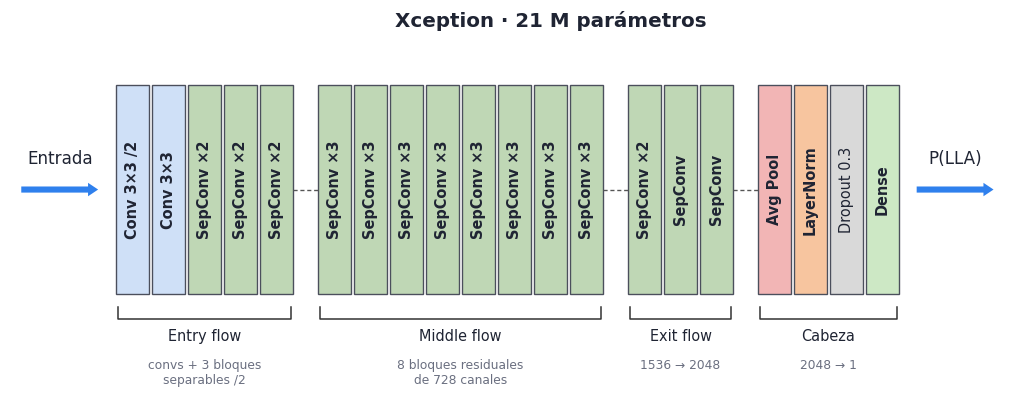

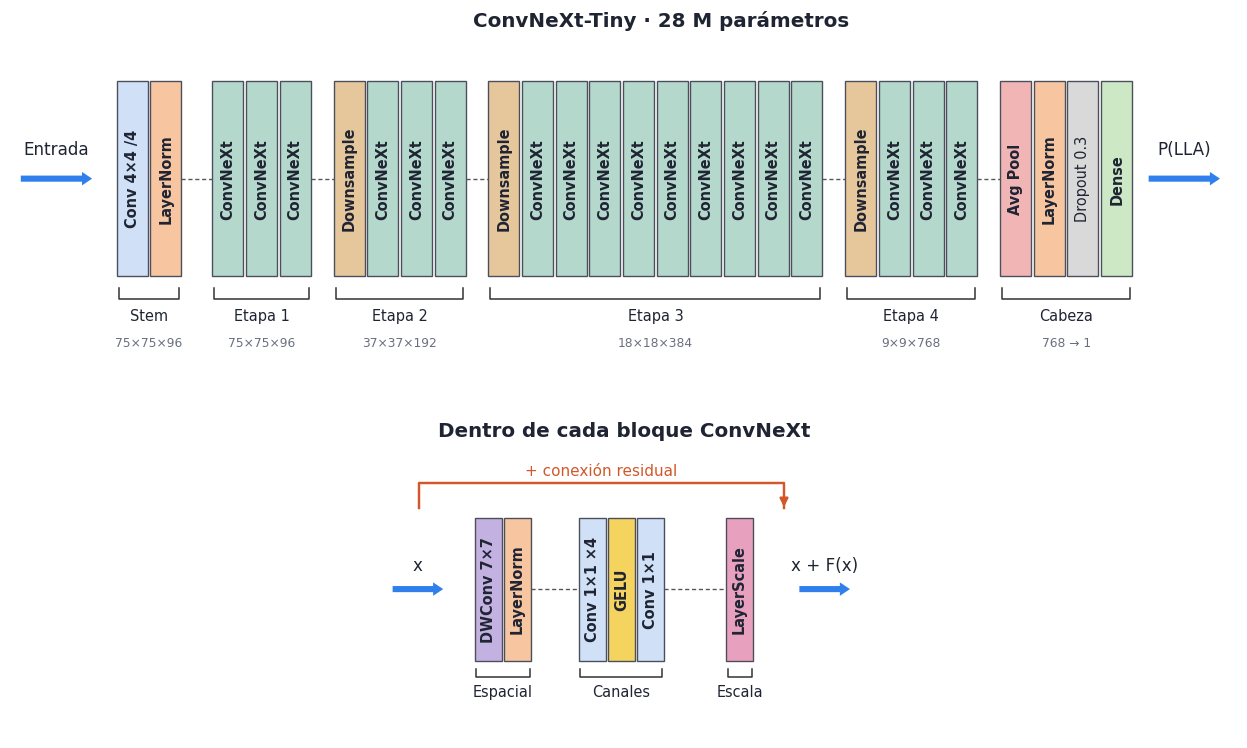

In [49]:
def build_v2(backbone, img_size=None, dropout=0.3):
    img_size = img_size or IMP_IMG_SIZE
    inp = keras.Input((img_size, img_size, 3), name="imagen")
    if backbone == "efficientnet_b0":       # trae su propia normalización (entrada 0–255)
        base = keras.applications.EfficientNetB0(include_top=False, weights=PRETRAINED_WEIGHTS, input_tensor=inp)
    elif backbone == "xception":            # espera la entrada en [-1, 1]
        x0 = layers.Rescaling(1 / 127.5, offset=-1, name="escala_xception")(inp)
        base = keras.applications.Xception(include_top=False, weights=PRETRAINED_WEIGHTS, input_tensor=x0)
    elif backbone == "convnext_tiny":
        base = keras.applications.ConvNeXtTiny(include_top=False, weights=PRETRAINED_WEIGHTS, input_tensor=inp,
                                               include_preprocessing=True)
    else:
        raise ValueError(backbone)
    base.trainable = False
    x = layers.GlobalAveragePooling2D(name="head_gap")(base.output)
    x = layers.LayerNormalization(name="head_ln")(x)
    x = layers.Dropout(dropout, name="head_drop")(x)
    out = layers.Dense(1, activation="sigmoid", dtype="float32", name="pred")(x)
    return keras.Model(inp, out, name=f"{backbone}_v2"), base

def last_feature_layer(model):
    # Última capa con salida espacial (alto × ancho × canales): la que usa Grad-CAM
    for layer in reversed(model.layers):
        try:
            if len(layer.output.shape) == 4:
                return layer.name
        except Exception:
            continue

def train_v2(backbone, name, df_tr, df_va, mode="norm", stain=False):
    # Etapa 1: cabeza con la base congelada · Etapa 2: ajuste fino completo con tasa coseno
    set_seed()
    model, base = build_v2(backbone)
    loss = keras.losses.BinaryCrossentropy(label_smoothing=LABEL_SMOOTHING)
    ds_tr = make_dataset_v2(df_tr, training=True, mode=mode, stain=stain)
    ds_va = make_dataset_v2(df_va, mode=mode)
    cw = class_weights(df_tr)
    ckpt = f"{OUT_DIR}/{name}.weights.h5"
    cbs = [keras.callbacks.ModelCheckpoint(ckpt, monitor="val_auc", mode="max", save_best_only=True, save_weights_only=True),
           keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=PATIENCE_V2),
           keras.callbacks.CSVLogger(f"{OUT_DIR}/{name}_log.csv")]
    with EnergyMeter(name):
        model.compile(keras.optimizers.AdamW(1e-3, weight_decay=1e-4), loss=loss, metrics=compile_metrics())
        h1 = model.fit(ds_tr, validation_data=ds_va, epochs=IMP_EPOCHS_HEAD, class_weight=cw, callbacks=cbs, verbose=2)
        base.trainable = True
        for layer in base.layers:
            if isinstance(layer, layers.BatchNormalization):
                layer.trainable = False
        steps = int(np.ceil(len(df_tr) / BATCH_SIZE))
        lr = keras.optimizers.schedules.CosineDecay(
            initial_learning_rate=LR_FT[backbone] / 20, warmup_target=LR_FT[backbone], warmup_steps=steps,
            decay_steps=max(1, (IMP_EPOCHS_FT - 1) * steps), alpha=0.01)
        model.compile(keras.optimizers.AdamW(lr, weight_decay=WD_FT[backbone]), loss=loss, metrics=compile_metrics())
        h2 = model.fit(ds_tr, validation_data=ds_va, epochs=IMP_EPOCHS_FT, class_weight=cw, callbacks=cbs, verbose=2)
    if os.path.exists(ckpt):
        model.load_weights(ckpt)
    return model, [h1.history, h2.history]

def tta_views(x, k, flip):
    x = tf.image.rot90(x, k)
    return tf.image.flip_left_right(x) if flip else x

def predict_v2(models, df, mode="norm", tta=TTA):
    # Promedia modelos (ensamble) y, si tta=True, 8 orientaciones de cada imagen
    if len(df) == 0:
        return np.array([])
    ds = make_dataset_v2(df, mode=mode, img_size=models[0].input_shape[1])
    views = [(k, f) for k in range(4) for f in (False, True)] if tta else [(0, False)]
    preds = []
    for m in models:
        for k, f in views:
            preds.append(m.predict(ds.map(lambda x, y, k=k, f=f: (tta_views(x, k, f), y)), verbose=0).ravel())
    return np.mean(preds, axis=0)

def n_params(models):
    return models[0].count_params() / 1e6

# Un candidato puede mezclar modelos que usan entradas distintas (p. ej. recorte nativo + tamaño normalizado).
# "parts" = [(modelos, modo de entrada), ...]; cada modelo pesa lo mismo en el promedio.
def parts_of(c):
    return c.get("parts") or [(c["models"], c["mode"])]

def predict_cand(c, df, tta=TTA):
    parts = parts_of(c)
    total = sum(len(ms) for ms, _ in parts)
    return sum(predict_v2(ms, df, md_, tta) * len(ms) for ms, md_ in parts) / total

# Diagramas de Xception y ConvNeXt-Tiny (funciones de la sección 7.1)
fig, ax = plt.subplots(figsize=(15, 4.6))
draw_bars(ax, xception_groups(IMP_IMG_SIZE), "Xception · 21 M parámetros", min_group_w=1.2)
savefig("arquitectura_xception"); plt.show()

fig, ax = plt.subplots(2, 1, figsize=(16, 8.5), gridspec_kw={"height_ratios": [1.25, 1]})
draw_bars(ax[0], convnext_groups(IMP_IMG_SIZE), "ConvNeXt-Tiny · 28 M parámetros", min_group_w=1.2)
draw_bars(ax[1], convnext_block_groups(), None, in_label="x", out_label="x + F(x)", bar_w=0.55, gap_out=0.5, min_group_w=1.9)
draw_residual_arc(ax[1], 0.6, 8.0, 3.25)
draw_residual_title(ax[1], "Dentro de cada bloque ConvNeXt")
savefig("arquitectura_convnext"); plt.show()

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    18.3 Estudio de ablación
</div>

In [ ]:
CANDS = {}   # nombre → {"models": [...], "mode": str, "p_val": ..., "p_test": ..., "p_test_sin_tta": ...}
CANDS["Referencia · EfficientNet-B0 (sección 8)"] = {
    "models": [effnet], "mode": "resize", "p_val": P_VAL["EfficientNet-B0"],
    "p_test": P_TEST["EfficientNet-B0"], "p_test_sin_tta": P_TEST["EfficientNet-B0"], "original": True}
CFG = {}     # nombre → (arquitectura, modo de entrada)
hist_v2 = {}

def run_variant(name, backbone, mode, stain=False):
    print(f"\n===== {name} =====")
    get_bank(mode)
    t0 = time.time()
    model, hist_v2[name] = train_v2(backbone, re.sub(r"\W+", "_", name.split(" · ")[0]).lower(), tr_df, va_df, mode, stain)
    CANDS[name] = {"models": [model], "mode": mode,
                   "p_val": predict_v2([model], va_df, mode),
                   "p_test": predict_v2([model], test_df, mode),
                   "p_test_sin_tta": predict_v2([model], test_df, mode, tta=False),
                   "minutos": (time.time() - t0) / 60}
    CFG[name] = (backbone, mode, stain)
    print(f"AUC val = {skm.roc_auc_score(y_val, CANDS[name]['p_val']):.3f}")
    gc.collect()

for mode, tag in [("resize", "V1"), ("crop", "V2"), ("norm", "V3")]:
    run_variant(f"{tag} · B0 · {MODE_NAMES[mode]}", "efficientnet_b0", mode)
    release_bank(mode)   # libera RAM; el banco ganador se vuelve a crear abajo

_best = max([n for n in CFG], key=lambda n: skm.roc_auc_score(y_val, CANDS[n]["p_val"]))
BEST_MODE = CANDS[_best]["mode"]
print(f"\nMejor entrada según validación: {MODE_NAMES[BEST_MODE]}")

for tag, backbone, label in [("V4", "xception", "Xception"), ("V5", "convnext_tiny", "ConvNeXt-T")]:
    if backbone in IMP_BACKBONES:
        run_variant(f"{tag} · {label} · {MODE_NAMES[BEST_MODE]}", backbone, BEST_MODE)

def make_ensemble(name, members):
    CANDS[name] = {"models": sum((CANDS[n]["models"] for n in members), []), "mode": CANDS[members[0]]["mode"],
                   "parts": [p for n in members for p in parts_of(CANDS[n])], "members": list(members),
                   "p_val": np.mean([CANDS[n]["p_val"] for n in members], 0),
                   "p_test": np.mean([CANDS[n]["p_test"] for n in members], 0),
                   "p_test_sin_tta": np.mean([CANDS[n]["p_test_sin_tta"] for n in members], 0)}
    print(f"{name.split(' · ')[0]} combina:", members)

ens_members = [n for n in CFG if CANDS[n]["mode"] == BEST_MODE]
if len(ens_members) >= 2:
    make_ensemble("V6 · Ensamble de arquitecturas", ens_members)

OTHER_MODE = "norm" if BEST_MODE == "crop" else "crop"
otra = [n for n in CFG if CFG[n][0] == "efficientnet_b0" and CFG[n][1] == OTHER_MODE]
if len(ens_members) >= 2 and otra:
    make_ensemble("V8 · Ensamble mixto (recorte + tamaño normalizado)", ens_members + otra)

V9 = None
if STAIN_AUG and "convnext_tiny" in IMP_BACKBONES:
    V9 = f"V9 · ConvNeXt-T · {MODE_NAMES[BEST_MODE]} + aumento de tinción"
    run_variant(V9, "convnext_tiny", BEST_MODE, stain=True)

if V9 and len(ens_members) >= 2 and otra:
    make_ensemble("V10 · Ensamble mixto + tinción", ens_members + otra + [V9])

def ablation_table(cands, y_val_, y_test_):
    rows = []
    for n, c in cands.items():
        rows.append({"variante": n, "parámetros (M)": sum(m.count_params() for m in c["models"]) / 1e6,
                     "AUC val": skm.roc_auc_score(y_val_, c["p_val"]),
                     "AUC prueba sin TTA": skm.roc_auc_score(y_test, c["p_test_sin_tta"]),
                     "AUC prueba": skm.roc_auc_score(y_test, c["p_test"]),
                     "PR-AUC prueba": skm.average_precision_score(y_test, c["p_test"]),
                     "minutos": c.get("minutos", np.nan)})
    return pd.DataFrame(rows).set_index("variante")

abl = ablation_table(CANDS, y_val, y_test)
display(abl.round(3).style.background_gradient(cmap="Greens", subset=["AUC val", "AUC prueba"]))


===== V1 · B0 · imagen completa reducida =====
Banco de imágenes (imagen completa reducida, 300px): 3.38 GB en RAM
Epoch 1/3
273/273 - 33s - 121ms/step - acc: 0.7065 - auc: 0.7704 - loss: 0.6117 - pr_auc: 0.8437 - precision: 0.8204 - recall: 0.7167 - val_acc: 0.7354 - val_auc: 0.7863 - val_loss: 0.5539 - val_pr_auc: 0.8946 - val_precision: 0.8817 - val_recall: 0.7483
Epoch 2/3
273/273 - 6s - 21ms/step - acc: 0.7482 - auc: 0.8127 - loss: 0.5539 - pr_auc: 0.8704 - precision: 0.8434 - recall: 0.7644 - val_acc: 0.7101 - val_auc: 0.8048 - val_loss: 0.5810 - val_pr_auc: 0.9058 - val_precision: 0.8976 - val_recall: 0.6933
Epoch 3/3
273/273 - 6s - 21ms/step - acc: 0.7623 - auc: 0.8259 - loss: 0.5362 - pr_auc: 0.8818 - precision: 0.8540 - recall: 0.7762 - val_acc: 0.7695 - val_auc: 0.8244 - val_loss: 0.5117 - val_pr_auc: 0.9172 - val_precision: 0.8962 - val_recall: 0.7840
Epoch 1/25
273/273 - 61s - 224ms/step - acc: 0.7755 - auc: 0.8383 - loss: 0.5191 - pr_auc: 0.8922 - precision: 0.8558 - rec

,parámetros (M),AUC val,AUC prueba sin TTA,AUC prueba,PR-AUC prueba,minutos
variante,,,,,,
Referencia · EfficientNet-B0 (sección 8),4.056000,0.889000,0.780000,0.780000,0.859000,nan
V1 · B0 · imagen completa reducida,4.053000,0.978000,0.757000,0.772000,0.834000,5.175000
V2 · B0 · recorte central nativo,4.053000,0.992000,0.868000,0.882000,0.929000,4.176000
V3 · B0 · tamaño normalizado,4.053000,0.991000,0.891000,0.900000,0.943000,5.033000
V4 · Xception · recorte central nativo,20.868000,0.993000,0.892000,0.901000,0.930000,6.490000
V5 · ConvNeXt-T · recorte central nativo,27.822000,0.996000,0.918000,0.922000,0.953000,10.384000
V6 · Ensamble de arquitecturas,52.743000,0.997000,0.928000,0.932000,0.961000,nan
V8 · Ensamble mixto (recorte + tamaño normalizado),56.797000,0.997000,0.930000,0.933000,0.962000,nan
V9 · ConvNeXt-T · recorte central nativo + aumento de tinción,27.822000,0.995000,0.905000,0.912000,0.941000,16.130000


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    18.4 V7 · Ensamble por validación cruzada de pacientes
</div>

El modelo de la sección 8 aprendió con 60 pacientes y eligió su umbral con solo 13. Aquí entrenamos `CV_FOLDS` modelos con la mejor configuración de la ablación (según **AUC de validación**), cada uno dejando fuera un grupo distinto de pacientes. Así:
- Entre todos, los modelos ven a los **73 pacientes**.
- Cada paciente recibe una predicción de un modelo que nunca lo vio (predicción *out-of-fold*). Con esas predicciones elegimos el umbral usando 73 pacientes en vez de 13.
- En la prueba externa promediamos los modelos: el ensamble reduce la varianza.

Para compararlo con las demás variantes de forma justa, su "AUC val" se calcula con las predicciones *out-of-fold* de los mismos 13 pacientes de validación.

In [51]:
single = list(CFG)
BEST_CFG = max(single, key=lambda n: abl.loc[n, "AUC val"]) if single else None
if CV_FOLDS and BEST_CFG:
    backbone, mode, stain = CFG[BEST_CFG]
    print(f"Configuración del ensamble: {BEST_CFG}")
    get_bank(mode)
    cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    oof = np.zeros(len(train_df)); cv_models = []
    for f, (a, b) in enumerate(cv.split(train_df, train_df.label, groups=train_df.subject)):
        print(f"\n--- Fold {f + 1}/{CV_FOLDS}: {train_df.iloc[a].subject.nunique()} pacientes de entrenamiento ---")
        m, _ = train_v2(backbone, f"cv_fold{f}", train_df.iloc[a], train_df.iloc[b], mode, stain)
        oof[b] = predict_v2([m], train_df.iloc[b], mode)
        cv_models.append(m); gc.collect()
    va_mask = train_df.subject.isin(set(va_df.subject)).values
    order = pd.Series(oof[va_mask], index=train_df.path[va_mask].values).reindex(va_df.path.values).values
    CANDS[f"V7 · Ensamble CV ({CV_FOLDS} modelos)"] = {
        "models": cv_models, "mode": mode, "p_val": order, "oof": oof,
        "p_test": predict_v2(cv_models, test_df, mode),
        "p_test_sin_tta": predict_v2(cv_models, test_df, mode, tta=False)}
    print(f"AUC out-of-fold con los {train_df.subject.nunique()} pacientes: {skm.roc_auc_score(train_df.label, oof):.3f}")

abl = ablation_table(CANDS, y_val, y_test)
FINAL = abl["AUC val"].idxmax()
display(abl.round(3).style.background_gradient(cmap="Greens", subset=["AUC val", "AUC prueba"]))
print("Modelo final elegido por AUC de validación:", FINAL)
abl.to_csv(f"{OUT_DIR}/ablacion_mejoras.csv")

Configuración del ensamble: V5 · ConvNeXt-T · recorte central nativo

--- Fold 1/3: 50 pacientes de entrenamiento ---
Epoch 1/3
244/244 - 28s - 115ms/step - acc: 0.7594 - auc: 0.8353 - loss: 0.5253 - pr_auc: 0.8672 - precision: 0.8297 - recall: 0.7667 - val_acc: 0.7024 - val_auc: 0.6379 - val_loss: 0.5717 - val_pr_auc: 0.9076 - val_precision: 0.8927 - val_recall: 0.7447
Epoch 2/3
244/244 - 7s - 28ms/step - acc: 0.7899 - auc: 0.8694 - loss: 0.4821 - pr_auc: 0.8922 - precision: 0.8551 - recall: 0.7933 - val_acc: 0.7315 - val_auc: 0.6441 - val_loss: 0.5409 - val_pr_auc: 0.9110 - val_precision: 0.8906 - val_recall: 0.7853
Epoch 3/3
244/244 - 7s - 29ms/step - acc: 0.7977 - auc: 0.8766 - loss: 0.4719 - pr_auc: 0.8995 - precision: 0.8584 - recall: 0.8041 - val_acc: 0.7948 - val_auc: 0.6596 - val_loss: 0.4905 - val_pr_auc: 0.9158 - val_precision: 0.8901 - val_recall: 0.8695
Epoch 1/25
244/244 - 99s - 407ms/step - acc: 0.8444 - auc: 0.9129 - loss: 0.4107 - pr_auc: 0.9310 - precision: 0.8819 - r

,parámetros (M),AUC val,AUC prueba sin TTA,AUC prueba,PR-AUC prueba,minutos
variante,,,,,,
Referencia · EfficientNet-B0 (sección 8),4.056000,0.889000,0.780000,0.780000,0.859000,nan
V1 · B0 · imagen completa reducida,4.053000,0.978000,0.757000,0.772000,0.834000,5.175000
V2 · B0 · recorte central nativo,4.053000,0.992000,0.868000,0.882000,0.929000,4.176000
V3 · B0 · tamaño normalizado,4.053000,0.991000,0.891000,0.900000,0.943000,5.033000
V4 · Xception · recorte central nativo,20.868000,0.993000,0.892000,0.901000,0.930000,6.490000
V5 · ConvNeXt-T · recorte central nativo,27.822000,0.996000,0.918000,0.922000,0.953000,10.384000
V6 · Ensamble de arquitecturas,52.743000,0.997000,0.928000,0.932000,0.961000,nan
V8 · Ensamble mixto (recorte + tamaño normalizado),56.797000,0.997000,0.930000,0.933000,0.962000,nan
V9 · ConvNeXt-T · recorte central nativo + aumento de tinción,27.822000,0.995000,0.905000,0.912000,0.941000,16.130000


Modelo final elegido por AUC de validación: V10 · Ensamble mixto + tinción


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    18.5 Evaluación final en la prueba externa
</div>

Comparamos la referencia con el modelo final usando el mismo protocolo de la sección 10: umbral de Youden elegido en validación (para el ensamble CV, con las predicciones *out-of-fold* de los 73 pacientes), intervalos por *bootstrap* de pacientes y prueba de McNemar.

,umbral,exactitud,exactitud balanceada,sensibilidad,especificidad,precisión (VPP),F1,F1 ponderado,MCC,ROC-AUC,PR-AUC
Referencia · EfficientNet-B0 (sección 8),0.787000,0.738000,0.691000,0.845000,0.537000,0.774000,0.808000,0.732000,0.402000,0.780000,0.859000
V1 · B0 · imagen completa reducida,0.701000,0.738000,0.678000,0.873000,0.483000,0.761000,0.813000,0.725000,0.391000,0.772000,0.834000
V2 · B0 · recorte central nativo,0.695000,0.803000,0.738000,0.952000,0.525000,0.790000,0.863000,0.789000,0.553000,0.882000,0.929000
V3 · B0 · tamaño normalizado,0.289000,0.816000,0.760000,0.944000,0.576000,0.807000,0.870000,0.806000,0.583000,0.900000,0.943000
V4 · Xception · recorte central nativo,0.404000,0.844000,0.799000,0.947000,0.650000,0.836000,0.888000,0.838000,0.648000,0.901000,0.930000
V5 · ConvNeXt-T · recorte central nativo,0.301000,0.835000,0.777000,0.966000,0.588000,0.815000,0.884000,0.825000,0.631000,0.922000,0.953000
V6 · Ensamble de arquitecturas,0.621000,0.867000,0.837000,0.936000,0.738000,0.870000,0.902000,0.865000,0.701000,0.932000,0.961000
V8 · Ensamble mixto (recorte + tamaño normalizado),0.516000,0.856000,0.813000,0.956000,0.670000,0.845000,0.897000,0.851000,0.678000,0.933000,0.962000
V9 · ConvNeXt-T · recorte central nativo + aumento de tinción,0.397000,0.845000,0.807000,0.931000,0.684000,0.847000,0.887000,0.841000,0.650000,0.912000,0.941000
V10 · Ensamble mixto + tinción,0.563000,0.863000,0.832000,0.934000,0.730000,0.867000,0.899000,0.860000,0.691000,0.937000,0.964000


IC 2.5%  mediana  \
Referencia · EfficientNet-B0 (sección 8) F1 ponderado     0.667    0.730   
                                         ROC-AUC          0.686    0.774   
                                         sensibilidad     0.776    0.846   
                                         especificidad    0.429    0.530   
V10 · Ensamble mixto + tinción           F1 ponderado     0.786    0.857   
                                         ROC-AUC          0.865    0.934   
                                         sensibilidad     0.865    0.932   
                                         especificidad    0.581    0.723   

                                                        IC 97.5%  
Referencia · EfficientNet-B0 (sección 8) F1 ponderado      0.787  
                                         ROC-AUC           0.841  
                                         sensibilidad      0.902  
                                         especificidad     0.609  
V10 · Ensamble mixto + tinción           F1 ponderado      0.906  
                                         ROC-AUC           0.971  
                                         sensibilidad      0.975  
                                         especificidad     0.812

McNemar referencia vs final: solo acierta la referencia=93, solo acierta el final=326, p=2.06e-31


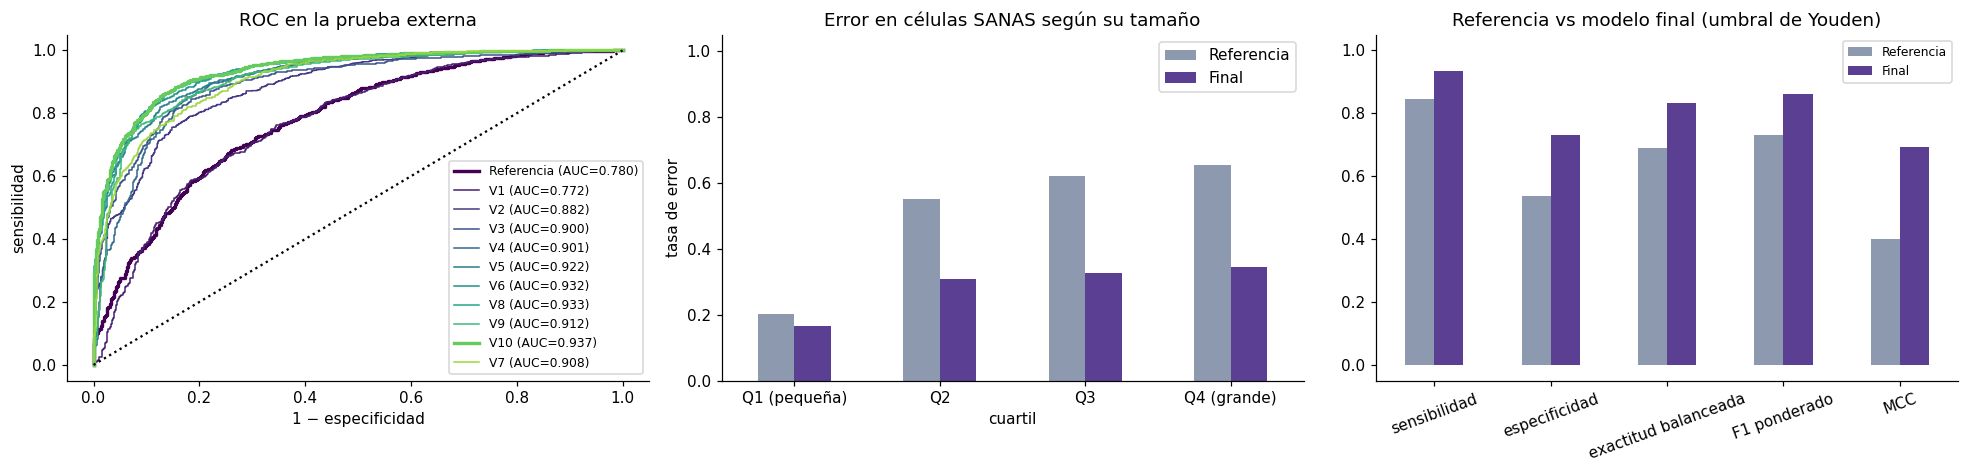

In [52]:
REF = "Referencia · EfficientNet-B0 (sección 8)"

def youden_thr(name):
    c = CANDS[name]
    if "oof" in c:
        return choose_thresholds(train_df.label.values, c["oof"])["Youden"]
    return choose_thresholds(y_val, c["p_val"])["Youden"]

THR_V2 = {n: youden_thr(n) for n in CANDS}
final_rows = {n: compute_metrics(y_test, CANDS[n]["p_test"], THR_V2[n]) for n in CANDS}
final_tab = pd.DataFrame(final_rows).T
display(final_tab.round(3).style.background_gradient(cmap="Greens", subset=["ROC-AUC", "F1 ponderado", "MCC", "exactitud balanceada"]))
final_tab.to_csv(f"{OUT_DIR}/metricas_mejoras.csv")

ci_v2 = pd.concat({n: bootstrap_ci(test_df, CANDS[n]["p_test"], THR_V2[n]) for n in [REF, FINAL]})
display(ci_v2.round(3))

ok_r = (CANDS[REF]["p_test"] >= THR_V2[REF]).astype(int) == y_test
ok_f = (CANDS[FINAL]["p_test"] >= THR_V2[FINAL]).astype(int) == y_test
b_, c_ = int((ok_r & ~ok_f).sum()), int((~ok_r & ok_f).sum())
p_mc_v2 = stats.binomtest(min(b_, c_), b_ + c_, 0.5).pvalue if b_ + c_ else 1.0
print(f"McNemar referencia vs final: solo acierta la referencia={b_}, solo acierta el final={c_}, p={p_mc_v2:.2e}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
cols = plt.cm.viridis(np.linspace(0, .85, len(CANDS)))
for (n, c), col in zip(CANDS.items(), cols):
    fpr, tpr, _ = skm.roc_curve(y_test, c["p_test"])
    ax[0].plot(fpr, tpr, color=col, lw=2.2 if n in (REF, FINAL) else 1, label=f"{n.split(' · ')[0]} (AUC={skm.roc_auc_score(y_test, c['p_test']):.3f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set(title="ROC en la prueba externa", xlabel="1 − especificidad", ylabel="sensibilidad")
ax[0].legend(fontsize=8)

q = err["cuartil de área"].values
comp = pd.DataFrame({"cuartil": q, "label": y_test,
                     "Referencia": (CANDS[REF]["p_test"] >= THR_V2[REF]).astype(int) != y_test,
                     "Final": (CANDS[FINAL]["p_test"] >= THR_V2[FINAL]).astype(int) != y_test})
comp[comp.label == 0].groupby("cuartil")[["Referencia", "Final"]].mean().plot.bar(ax=ax[1], rot=0, color=["#8d99ae", "#5B3F92"])
ax[1].set(title="Error en células SANAS según su tamaño", ylabel="tasa de error", ylim=(0, 1.05))

m_cols = ["sensibilidad", "especificidad", "exactitud balanceada", "F1 ponderado", "MCC"]
final_tab.loc[[REF, FINAL], m_cols].T.plot.bar(ax=ax[2], rot=20, color=["#8d99ae", "#5B3F92"])
ax[2].set(title="Referencia vs modelo final (umbral de Youden)", ylim=(min(0, final_tab[m_cols].values.min()) - .05, 1.05))
ax[2].legend(["Referencia", "Final"], fontsize=8)
plt.tight_layout(); savefig("mejoras_resultados"); plt.show()

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    18.6 ¿Desapareció el atajo? Grad-CAM antes y después
</div>

Mostramos las mismas células sanas y leucémicas con la referencia y con el modelo final, y medimos qué fracción de la activación cae **dentro** de la célula.

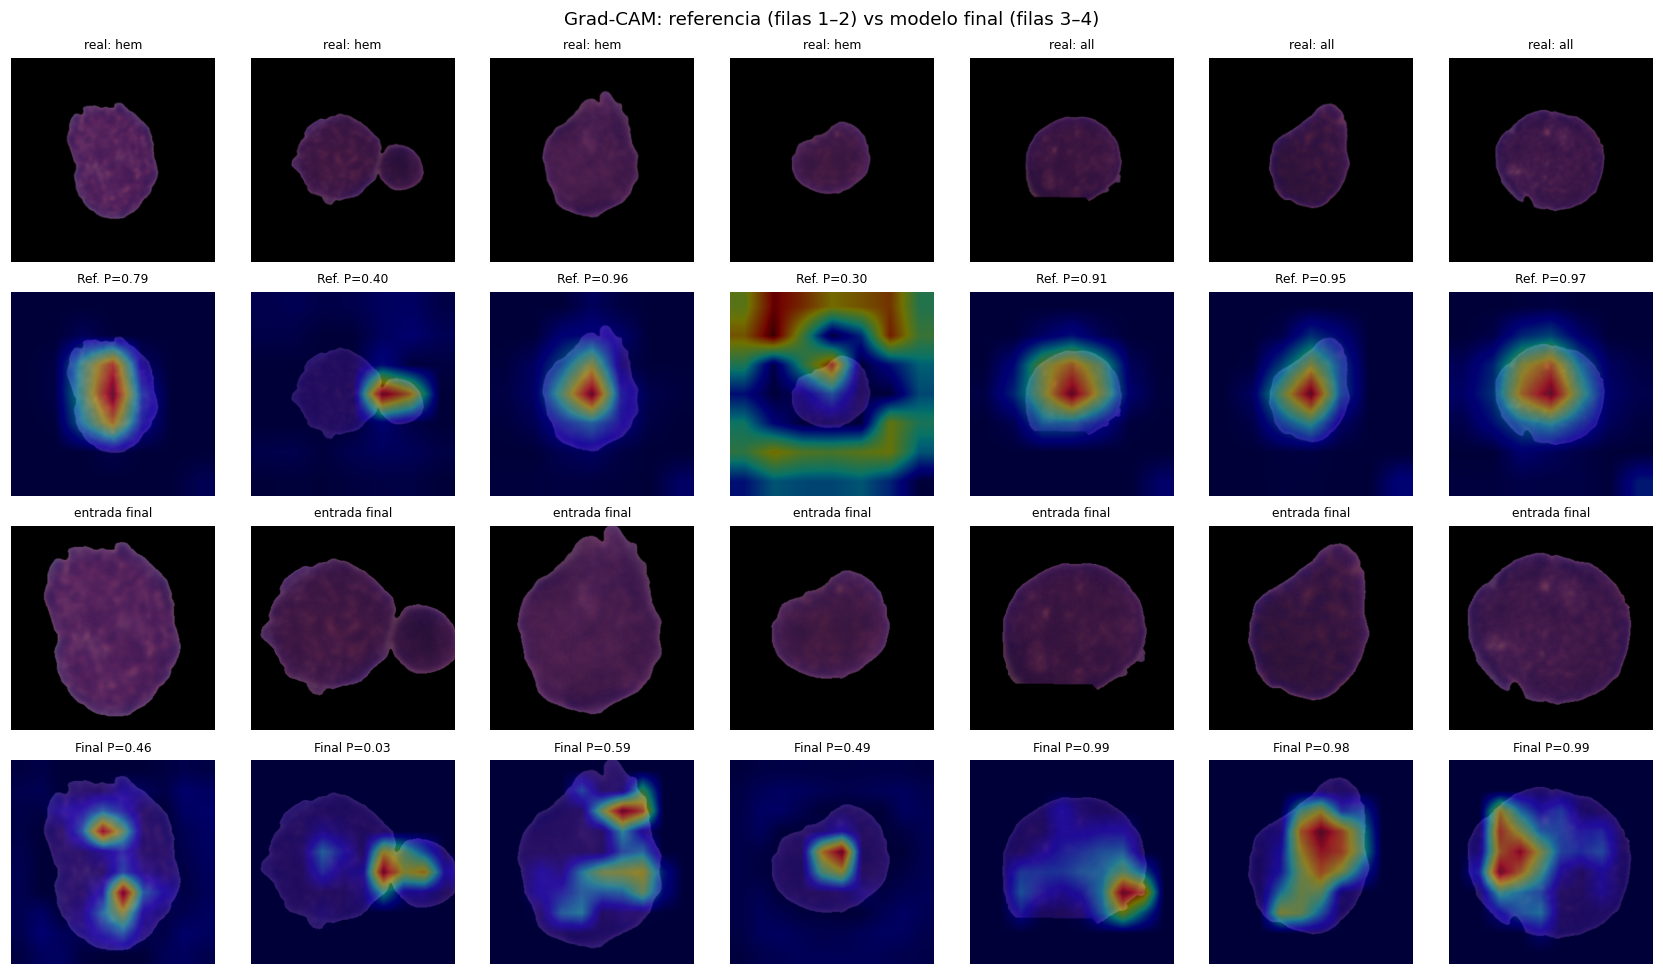

,activación dentro de la célula,área de la célula
modelo,,
Final,0.869,0.372
Referencia,0.660,0.167


In [53]:
final_model = parts_of(CANDS[FINAL])[0][0][0]     # primer modelo del ensamble (para Grad-CAM y TFLite)
final_mode = parts_of(CANDS[FINAL])[0][1]
FINAL_LAYER = last_feature_layer(final_model)

def prep(path, mode, img_size=None):
    return LOADERS[mode](path, img_size or IMP_IMG_SIZE).numpy()

picks = pd.concat([test_df[test_df.label == 0].sample(4, random_state=1), test_df[test_df.label == 1].sample(3, random_state=1)])
fig, axes = plt.subplots(4, len(picks), figsize=(2.2 * len(picks), 9))
for j, (_, r) in enumerate(picks.iterrows()):
    a, b = prep(r.path, "resize", IMG_SIZE), prep(r.path, final_mode, final_model.input_shape[1])
    cam_a, p_a = grad_cam(effnet, "top_activation", a)
    cam_b, p_b = grad_cam(final_model, FINAL_LAYER, b)
    for i, (im, ttl) in enumerate([(a, f"real: {CLASS_NAMES[r.label].split()[0]}"), (overlay(a, cam_a), f"Ref. P={p_a:.2f}"),
                                   (b, "entrada final"), (overlay(b, cam_b), f"Final P={p_b:.2f}")]):
        axes[i, j].imshow(im); axes[i, j].set_title(ttl, fontsize=8); axes[i, j].axis("off")
plt.suptitle("Grad-CAM: referencia (filas 1–2) vs modelo final (filas 3–4)"); plt.tight_layout(); savefig("gradcam_mejoras"); plt.show()

rows = []
for _, r in test_df.sample(min(60, len(test_df)), random_state=SEED).iterrows():
    for n, mdl, layer, md_, sz in [("Referencia", effnet, "top_activation", "resize", IMG_SIZE),
                                   ("Final", final_model, FINAL_LAYER, final_mode, final_model.input_shape[1])]:
        im = prep(r.path, md_, sz)
        mask = im.max(-1) > 12
        cam, _ = grad_cam(mdl, layer, im)
        rows.append({"modelo": n, "activación dentro de la célula": cam[mask].sum() / (cam.sum() + 1e-8), "área de la célula": mask.mean()})
display(pd.DataFrame(rows).groupby("modelo").mean().round(3))

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    18.7 Diagnóstico por paciente (mejora 1: un umbral más estable)
</div>

En una corrida anterior el ensamble **ordenaba** muy bien a los pacientes (AUC 0,96), pero el umbral por paciente salió de solo 13 pacientes de validación y quedó demasiado alto, reconocía a todos los sanos y solo detectaba 5 de 13 con LLA.

Comparamos dos reglas:
- **Regla anterior:** probabilidad media de las células del paciente, con el umbral de Youden elegido entre los pacientes de validación (13 puntos).
- **Regla nueva — fracción de células sospechosas:** cada célula se marca como sospechosa si supera el umbral **celular** (elegido con ~1.900 células de validación, mucho más estable). El paciente es positivo si la fracción de células sospechosas supera un corte **fijado de antemano**: el punto medio entre la fracción esperada en un sano (la tasa de falsos positivos en validación) y en un paciente con LLA (la sensibilidad en validación). No se ajusta nada con pacientes, así que no depende de 13 puntos.

Es además una regla que un hematólogo entiende: "de las células de este paciente, el X% parecen blastos".

AUC por paciente  \
Referencia · EfficientNet-B0 (sección 8) anterior: media + Youden en pacientes de valida...         0.969231   
                                         nueva: fracción de células sospechosas                     0.948718   
V10 · Ensamble mixto + tinción           anterior: media + Youden en pacientes de valida...         0.974359   
                                         nueva: fracción de células sospechosas                     0.964103   

                                                                                                corte  \
Referencia · EfficientNet-B0 (sección 8) anterior: media + Youden en pacientes de valida...    0.8221   
                                         nueva: fracción de células sospechosas              0.557676   
V10 · Ensamble mixto + tinción           anterior: media + Youden en pacientes de valida...  0.865479   
                                         nueva: fracción de células sospechosas              0.496952   

                                                                                            pacientes correctos  \
Referencia · EfficientNet-B0 (sección 8) anterior: media + Youden en pacientes de valida...               24/28   
                                         nueva: fracción de células sospechosas                           21/28   
V10 · Ensamble mixto + tinción           anterior: media + Youden en pacientes de valida...               20/28   
                                         nueva: fracción de células sospechosas                           25/28   

                                                                                            sanos reconocidos  \
Referencia · EfficientNet-B0 (sección 8) anterior: media + Youden en pacientes de valida...             13/15   
                                         nueva: fracción de células sospechosas                          8/15   
V10 · Ensamble mixto + tinción           anterior: media + Youden en pacientes de valida...             15/15   
                                         nueva: fracción de células sospechosas                         12/15   

                                                                                            con LLA detectados  
Referencia · EfficientNet-B0 (sección 8) anterior: media + Youden en pacientes de valida...              11/13  
                                         nueva: fracción de células sospechosas                          13/13  
V10 · Ensamble mixto + tinción           anterior: media + Youden en pacientes de valida...               5/13  
                                         nueva: fracción de células sospechosas                          13/13

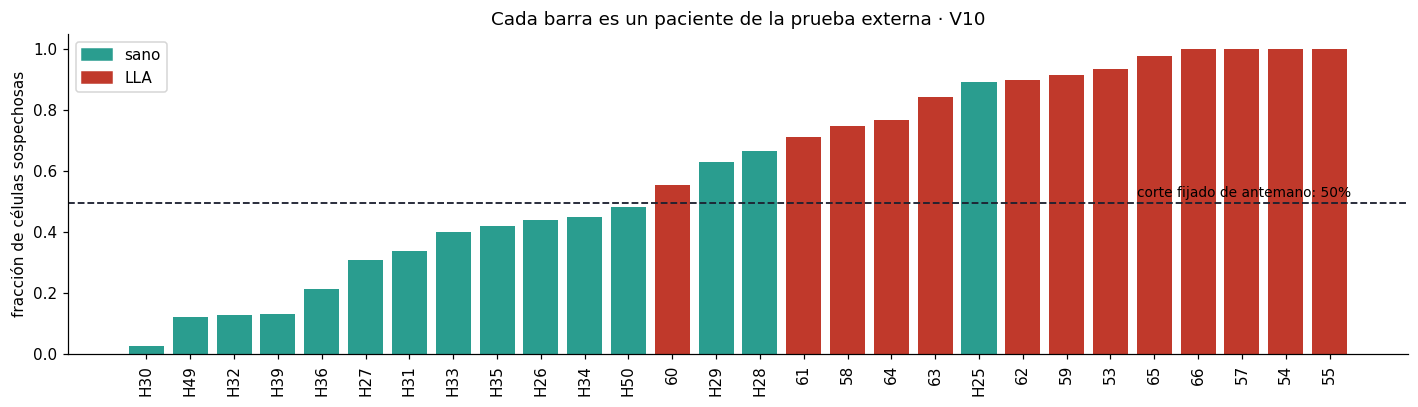

In [54]:
def patient_table(df, p, t_cell):
    d = df.assign(p=p, sosp=(p >= t_cell).astype(float))
    return d.groupby("subject").agg(clase=("label", "first"), células=("p", "size"), p_media=("p", "mean"), frac=("sosp", "mean"))

def resumen_pacientes(pt, score, t):
    pred = (pt[score] >= t).astype(int)
    return {"AUC por paciente": skm.roc_auc_score(pt.clase, pt[score]) if pt.clase.nunique() == 2 else np.nan,
            "corte": t,
            "pacientes correctos": f"{int((pred == pt.clase).sum())}/{len(pt)}",
            "sanos reconocidos": f"{int(((pred == 0) & (pt.clase == 0)).sum())}/{int((pt.clase == 0).sum())}",
            "con LLA detectados": f"{int(((pred == 1) & (pt.clase == 1)).sum())}/{int((pt.clase == 1).sum())}"}

def patient_eval(name):
    c = CANDS[name]; t_cell = THR_V2[name]
    if "oof" in c:
        df_v, p_v = train_df, c["oof"]
    else:
        df_v, p_v = va_df, c["p_val"]
    pv = patient_table(df_v, p_v, t_cell)
    t_media = choose_thresholds(pv.clase.values, pv.p_media.values)["Youden"] if pv.clase.nunique() == 2 else 0.5
    yv = df_v.label.values
    sens_v, fpr_v = float((p_v[yv == 1] >= t_cell).mean()), float((p_v[yv == 0] >= t_cell).mean())
    f_star = (sens_v + fpr_v) / 2
    pt = patient_table(test_df, c["p_test"], t_cell)
    return {("anterior: media + Youden en pacientes de validación"): resumen_pacientes(pt, "p_media", t_media),
            ("nueva: fracción de células sospechosas"): resumen_pacientes(pt, "frac", f_star)}, pt, f_star

PAT = {}
for n in [REF, FINAL]:
    res, pt, f_star = patient_eval(n)
    PAT[n] = {"tabla": pt, "f_star": f_star, "res": res}
pat_v2 = pd.concat({n: pd.DataFrame(PAT[n]["res"]).T for n in PAT})
display(pat_v2)

pt, f_star = PAT[FINAL]["tabla"].sort_values("frac"), PAT[FINAL]["f_star"]
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.bar(pt.index.astype(str), pt.frac, color=np.where(pt.clase == 1, "#c0392b", "#2a9d8f"))
ax.axhline(f_star, color="#1C2030", ls="--", lw=1.2)
ax.text(len(pt) - 0.5, f_star + 0.02, f"corte fijado de antemano: {f_star:.0%}", ha="right", fontsize=9)
ax.set(ylabel="fracción de células sospechosas", ylim=(0, 1.05), title=f"Cada barra es un paciente de la prueba externa · {FINAL.split(' · ')[0]}")
ax.tick_params(axis="x", rotation=90)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2a9d8f", label="sano"), Patch(color="#c0392b", label="LLA")], loc="upper left")
plt.tight_layout(); savefig("pacientes_fraccion"); plt.show()

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    18.8 ¿Mejora también en el otro hospital? (sección 17)
</div>

Primero medimos, **sin adaptar**, si el aumento de tinción (V9) generaliza mejor al otro hospital que el mismo modelo sin él (V5). Después repetimos las versiones A (sin adaptar), B y C (ajuste fino local) del sistema completo con el modelo final. Los recortes de SAM 2 ya vienen sobre fondo negro y en un lienzo de 450 px como C-NMC, así que cualquiera de las tres entradas se aplica igual.

In [55]:
if "cells_b" in globals() and len(cells_b) and len(cells_a_tr):
    # ¿Generaliza mejor el aumento de tinción? (sin adaptar, sin TTA para ahorrar tiempo)
    def auc_iran(n):
        s_ = image_scores(cells_b, imgs_b, predict_cand(CANDS[n], cells_b, tta=False))
        return skm.roc_auc_score(s_.label, s_.p_max)
    comparar = dict.fromkeys([REF] + [n for n in CANDS if n.startswith(("V5", "V9"))] + [FINAL])
    iran_tab = pd.DataFrame({n: {"AUC Irán sin adaptar": auc_iran(n)} for n in comparar}).T
    display(iran_tab.round(3))

    sb2 = image_scores(cells_b, imgs_b, predict_cand(CANDS[FINAL], cells_b))
    sv2 = image_scores(cells_a_va, imgs_a_va, predict_cand(CANDS[FINAL], cells_a_va))
    SYS2 = {"A. Sin adaptar (final)": (sb2, THR_V2[FINAL]),
            "B. Umbral recalibrado (final)": (sb2, choose_thresholds(sv2.label, sv2.p_max)["Youden"])}
    ft_parts = []
    for ms, md_ in parts_of(CANDS[FINAL]):   # ajuste fino local de cada modelo del ensamble, con su propia entrada
        nuevos = []
        for m in ms:
            mm = keras.models.clone_model(m); mm.set_weights(m.get_weights())
            mm.compile(keras.optimizers.AdamW(1e-5, weight_decay=1e-4), loss="binary_crossentropy", metrics=compile_metrics())
            mm.fit(make_dataset_v2(cells_a_tr, training=True, mode=md_, img_size=m.input_shape[1]), epochs=FINETUNE_EPOCHS,
                   class_weight=class_weights(cells_a_tr), verbose=0)
            nuevos.append(mm)
        ft_parts.append((nuevos, md_))
    ft_cand = {"parts": ft_parts}
    sv2_ft = image_scores(cells_a_va, imgs_a_va, predict_cand(ft_cand, cells_a_va))
    sb2_ft = image_scores(cells_b, imgs_b, predict_cand(ft_cand, cells_b))
    SYS2["C. Ajuste fino local (final)"] = (sb2_ft, choose_thresholds(sv2_ft.label, sv2_ft.p_max)["Youden"])
    sys2_table = pd.concat([sys_table.assign(clasificador="referencia"),
                            pd.DataFrame({n: compute_metrics(s.label.values, s.p_max.values, t) for n, (s, t) in SYS2.items()}).T
                              .assign(clasificador="final")])
    display(sys2_table[["clasificador", "ROC-AUC", "PR-AUC", "sensibilidad", "especificidad", "F1 ponderado"]].round(3))
    sys2_table.to_csv(f"{PIPE_DIR}/metricas_sistema_completo_mejoras.csv")
else:
    print("La sección 17 no se ejecutó en esta sesión: se omite la comparación en el otro hospital.")

,AUC Irán sin adaptar
Referencia · EfficientNet-B0 (sección 8),0.302
V5 · ConvNeXt-T · recorte central nativo,0.360
V9 · ConvNeXt-T · recorte central nativo + aumento de tinción,0.379
V10 · Ensamble mixto + tinción,0.338


,clasificador,ROC-AUC,PR-AUC,sensibilidad,especificidad,F1 ponderado
A. Sin adaptar,referencia,0.302,0.769,0.023,0.905,0.075
B. Umbral recalibrado,referencia,0.302,0.769,0.008,0.972,0.054
C. Ajuste fino local,referencia,0.709,0.949,0.522,0.948,0.640
A. Sin adaptar (final),final,0.337,0.778,0.275,0.540,0.372
B. Umbral recalibrado (final),final,0.337,0.778,0.002,0.976,0.044
C. Ajuste fino local (final),final,0.727,0.954,0.680,0.885,0.751



<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    18.9 Resumen y modelo para desplegar
</div>

La celda imprime las conclusiones con los números de **esta** corrida, para copiarlas a la presentación. También guarda el modelo final y su versión TFLite.

In [56]:
r0, r1 = final_tab.loc[REF], final_tab.loc[FINAL]
print(f"Modelo final: {FINAL} · {sum(m_.count_params() for m_ in CANDS[FINAL]['models']) / 1e6:.1f} M parámetros en {len(CANDS[FINAL]['models'])} modelo(s)")
print("Mejora 3 · ensamble mixto (V8) vs V6:", {n.split(" · ")[0]: round(abl.loc[n, "AUC prueba"], 3) for n in abl.index if n.startswith(("V6", "V8", "V10"))})
print(f"ROC-AUC en la prueba externa: {r0['ROC-AUC']:.3f} → {r1['ROC-AUC']:.3f} "
      f"(IC 95% final: {ci_v2.loc[(FINAL, 'ROC-AUC'), 'IC 2.5%']:.3f}–{ci_v2.loc[(FINAL, 'ROC-AUC'), 'IC 97.5%']:.3f})")
for k in ["sensibilidad", "especificidad", "exactitud balanceada", "F1 ponderado", "MCC"]:
    print(f"  {k}: {r0[k]:.3f} → {r1[k]:.3f}")
print(f"McNemar referencia vs final: p = {p_mc_v2:.2e}")
print("Mejor entrada:", MODE_NAMES[BEST_MODE])
print("Aporte de cada mejora (AUC en prueba):", {n.split(" · ")[0]: round(v, 3) for n, v in abl["AUC prueba"].items()})
print("Mejora 1 · por paciente (modelo final):")
display(pat_v2.loc[FINAL])
if "iran_tab" in globals():
    print("Mejora 2 · Irán sin adaptar:", iran_tab["AUC Irán sin adaptar"].round(3).to_dict())
if "sys2_table" in globals():
    print("Otro hospital (AUC por imagen):", sys2_table["ROC-AUC"].round(3).to_dict())

final_model.save(f"{OUT_DIR}/modelo_final.keras")
json.dump({"modelo": FINAL, "entrada": final_mode, "recorte_px": CROP_PX, "img_size": IMP_IMG_SIZE, "umbral": THR_V2[FINAL],
           "n_modelos": len(CANDS[FINAL]["models"]), **{k: float(v) for k, v in r1.items()}},
          open(f"{OUT_DIR}/resumen_mejoras.json", "w"), indent=2, ensure_ascii=False)
try:
    final_model.export(f"{OUT_DIR}/saved_model_final")
    conv = tf.lite.TFLiteConverter.from_saved_model(f"{OUT_DIR}/saved_model_final")
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    open(f"{OUT_DIR}/modelo_final.tflite", "wb").write(conv.convert())
    print(f"TFLite del modelo final: {os.path.getsize(f'{OUT_DIR}/modelo_final.tflite') / 1e6:.1f} MB (primer modelo del ensamble)")
except Exception as e:
    print("No se pudo exportar a TFLite:", type(e).__name__, str(e)[:200])

Modelo final: V10 · Ensamble mixto + tinción · 84.6 M parámetros en 5 modelo(s)
Mejora 3 · ensamble mixto (V8) vs V6: {'V6': np.float64(0.932), 'V8': np.float64(0.933), 'V10': np.float64(0.937)}
ROC-AUC en la prueba externa: 0.780 → 0.937 (IC 95% final: 0.865–0.971)
  sensibilidad: 0.845 → 0.934
  especificidad: 0.537 → 0.730
  exactitud balanceada: 0.691 → 0.832
  F1 ponderado: 0.732 → 0.860
  MCC: 0.402 → 0.691
McNemar referencia vs final: p = 2.06e-31
Mejor entrada: recorte central nativo
Aporte de cada mejora (AUC en prueba): {'Referencia': 0.78, 'V1': 0.772, 'V2': 0.882, 'V3': 0.9, 'V4': 0.901, 'V5': 0.922, 'V6': 0.932, 'V8': 0.933, 'V9': 0.912, 'V10': 0.937, 'V7': 0.908}
Mejora 1 · por paciente (modelo final):


,AUC por paciente,corte,pacientes correctos,sanos reconocidos,con LLA detectados
anterior: media + Youden en pacientes de validación,0.974359,0.865479,20/28,15/15,5/13
nueva: fracción de células sospechosas,0.964103,0.496952,25/28,12/15,13/13


Mejora 2 · Irán sin adaptar: {'Referencia · EfficientNet-B0 (sección 8)': 0.302, 'V5 · ConvNeXt-T · recorte central nativo': 0.36, 'V9 · ConvNeXt-T · recorte central nativo + aumento de tinción': 0.379, 'V10 · Ensamble mixto + tinción': 0.338}
Otro hospital (AUC por imagen): {'A. Sin adaptar': 0.302, 'B. Umbral recalibrado': 0.302, 'C. Ajuste fino local': 0.709, 'A. Sin adaptar (final)': 0.337, 'B. Umbral recalibrado (final)': 0.337, 'C. Ajuste fino local (final)': 0.727}
Saved artifact at '/content/resultados/saved_model_final'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 300, 300, 3), dtype=tf.float32, name='imagen')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139646075715216: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139648718849040: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139643243821392: TensorSpec(shape=(), dtype=tf.resource, name=No

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    18.10 Cómo interpretar estos resultados
</div>

- **V1 frente a la referencia** mide la receta de entrenamiento (y el aumento de resolución a `IMP_IMG_SIZE`).
- **V2 frente a V1** mide cuánto se perdía al reducir la imagen. Si sube mucho, confirma que el detalle de la cromatina es la información clave.
- **V3 frente a V2** mide el atajo del tamaño. Si V3 gana, el tamaño confundía al modelo. Si V2 gana, el tamaño sí aportaba información real (los blastos suelen ser más grandes) y conviene conservarlo. Las dos respuestas son hallazgos válidos.
- **V4 y V5** miden la arquitectura; **V6 y V7**, los ensambles.
- **V8 frente a V6** mide si combinar vistas con y sin tamaño ayuda (los modelos se equivocan en células distintas).
- **V9 frente a V5** mide el aumento de tinción. Lo importante no es la prueba de C-NMC sino la tabla de Irán sin adaptar (18.8): ahí es donde debería notarse.
- **Por paciente (18.7):** si la regla nueva detecta más pacientes con LLA sin perder sanos, el problema era el umbral, no el modelo.
- Compara el modelo final con Mondal et al. (2021): AUC 0,94 en esta misma prueba. Si quedan por debajo, la diferencia restante puede deberse a la semilla, a los hiperparámetros o al sobremuestreo que ellos usan en lugar de pesos de clase.
- Con 13 pacientes de validación la elección es ruidosa. Por eso reportamos todas las variantes en la prueba externa y no solo la ganadora.

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    18.11 Conclusiones de las mejoras
</div>

1. **0,937 de AUC en pacientes nuevos.** El modelo final, V10, promedia cinco redes: EfficientNet-B0 con recorte nativo y con tamaño normalizado, Xception, ConvNeXt-Tiny y ConvNeXt-Tiny con aumento de tinción. Logró un ROC-AUC de **0,937** (IC 95% por *bootstrap* de pacientes: 0,865–0,971) en la prueba externa, frente a 0,780 de la referencia. Sensibilidad 0,934, especificidad 0,730, exactitud balanceada 0,832, F1 ponderado 0,860, MCC 0,691. La mejora es significativa (McNemar p = 2,1·10⁻³¹: 326 células que ahora acierta frente a 93 que antes acertaba y ahora falla). En corridas anteriores dio 0,931 y 0,933.
2. **Frente a la literatura.** Mondal et al. (2021) reportan en esta misma prueba un AUC de 0,941, F1 ponderado de 0,886 y exactitud balanceada de 0,862. Estamos **a la par en AUC** (su valor cae dentro de nuestro intervalo) y algo por debajo en F1 y exactitud balanceada, que dependen del umbral. Con 28 pacientes de prueba no se puede afirmar que uno sea mejor que el otro.
3. **Qué aportó cada mejora** (AUC en la prueba externa): referencia 0,780 → receta nueva con la imagen reducida (V1) 0,772 → recorte nativo (V2) 0,882 → tamaño normalizado (V3) 0,900 → Xception (V4) 0,901 → ConvNeXt-Tiny (V5) 0,922 → ensambles 0,932 (V6), 0,933 (V8) y 0,937 (V10). El TTA sumó entre 0,003 y 0,015.
4. **El problema principal era la resolución.** La receta nueva sola no mejoró nada (V1); dejar de reducir la imagen subió 0,11. Al pasar de 450 a 224 px se perdía la textura de la cromatina, y el modelo se apoyaba en el tamaño.
5. **Quitar el tamaño ayudó.** Con tamaño normalizado (V3) el área ya no sirve para clasificar (AUC solo con el área: 0,855 → 0,444) y el modelo logra 0,900, por encima del recorte nativo (0,882). Con el modelo final, el error en células sanas por cuartil de tamaño es de ~17%, 31%, 33% y 34%, frente a ~20%, 55%, 62% y 65% de la referencia: el atajo casi desaparece. En Grad-CAM, el 87% de la activación cae dentro de la célula (frente a 66%), aunque en el recorte la célula ocupa más imagen (37% frente a 17%), así que esta cifra hay que leerla con cuidado.
6. **Mejora 3, ensamble mixto: aporte pequeño.** V6 → V8 → V10 suma 0,005 en total, dentro del ruido.
7. **Mejora 2, aumento de tinción: no funcionó en C-NMC.** V9 queda por debajo de V5 (0,912 frente a 0,922). En Irán sin adaptar sube un poco (0,379 frente a 0,360), pero sigue por debajo del azar.
8. **Mejora 1, regla por paciente: funcionó.** Con la regla anterior (media de probabilidades y umbral elegido con 13 pacientes), el modelo final reconocía a los 15 sanos pero solo detectaba 5 de 13 con LLA (20/28). Con la regla nueva (fracción de células sospechosas, corte fijado de antemano en ~50%), **detecta los 13 pacientes con LLA** y reconoce 12 de 15 sanos (25/28). El AUC por paciente es 0,964, igual que el de la referencia (0,969): los dos ordenan bien a los pacientes; lo que mejoró es la regla de decisión. Ojo: con 28 pacientes los conteos dependen mucho del corte; la referencia con la regla anterior llega a 24/28.
9. **La validación cruzada (V7) no ayudó** (0,908): cada modelo vio 47–50 pacientes en lugar de 60.
10. **Otro hospital:** sin adaptar sigue fallando (AUC 0,337); con ajuste local sube a 0,727 (frente a 0,709 de la referencia). Un mejor modelo no resuelve el cambio de dominio: hay que calibrar en cada sitio (sección 19).
11. **Costo.** V1–V5 y V9 tomaron ~47 min de GPU, más la validación cruzada. El ensamble final suma 84,6 M de parámetros. Para un equipo modesto, una sola EfficientNet-B0 (4 M de parámetros, 4,6 MB en TFLite) logra 0,882 con recorte nativo y 0,900 con tamaño normalizado.
12. **Advertencias metodológicas.** Las mejoras se diseñaron después de ver el resultado de la sección 10, pero se basaron en la literatura y en el análisis de errores, y el modelo final se eligió solo con la validación. El AUC de validación está saturado (0,99+), así que esa elección distingue poco entre las mejores variantes. Lo ideal sería confirmar en un conjunto nuevo, por ejemplo la prueba final del reto, cuyas etiquetas no son públicas.

<hr style="height: 3px; border: none; background: linear-gradient(to right, #3498db, transparent);">

<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        19. Cambio de dominio: ¿cómo hacer que el modelo funcione en otro hospital?
    </h2>
</div>

**El problema.** En las imágenes de Irán, sin adaptar, el modelo final queda por debajo del azar (AUC ≈ 0,33) y solo con ajuste fino local sube a ≈ 0,73. Probamos dos cosas que **no** lo resolvieron: un modelo mejor (sección 18) y el aumento de tinción (V9).

 Un modelo entrenado con un solo centro aprende rasgos de ese centro (tinción, fondo, escala), no solo de la célula. Lo que mejor generaliza entre datasets de leucemia es partir de un modelo preentrenado **en células de sangre de muchos laboratorios**:
- **DinoBloom** (Koch et al., 2024) es un ViT preentrenado con DINOv2 sobre más de 380.000 imágenes de leucocitos de 13 datasets públicos. En un dataset externo, su sonda lineal supera por mucho a una ResNet50 de ImageNet (exactitud balanceada 85,5% frente a 75,4%).
- En un estudio con cinco datasets de leucemia (incluido C-NMC), DinoBloom con una capa lineal fue el mejor codificador frente a CLIP y BiomedCLIP en un dataset que nunca vio (Retrieval-Augmented Vision Foundation Models for Robust Leukemia Cell Classification, 2026). El mismo estudio advierte que los atajos de fondo siguen siendo un riesgo y que no basta con una división aleatoria.
- Alinear las estadísticas de las características entre dominios sin usar etiquetas es la idea de AdaBN (Li et al., 2018) y CORAL (Sun y Saenko, 2016): el hospital solo tiene que aportar fotos, sin diagnósticos.


| Experimento | Datos de Irán que usa | ¿Qué responde? |
|---|---|---|
| **E1** · solo C-NMC | ninguno | ¿Un codificador de hematología generaliza sin adaptar? |
| **E2** · + alineación sin etiquetas | solo fotos (sin diagnóstico) | ¿Basta con que el hospital aporte imágenes? |
| **E3** · + etiquetas locales | fotos con diagnóstico (lote A) | ¿Supera al ajuste fino local de la sección 18.8 (≈ 0,73)? |

Cada uno se prueba con dos entradas: **recorte nativo** y **tamaño normalizado** (sección 18.1). Elegimos el mejor con el lote A de validación y **no** con el lote B, que solo se usa para reportar. Las células de Irán son las del sistema completo (YOLO11 + SAM 2, sección 17).

In [57]:
# ======================= EMBEDDINGS DE DINOBLOOM =======================
import subprocess
DINO_NAME = "hf-hub:1aurent/vit_base_patch14_224.dinobloom"   # DinoBloom-B (86 M de parámetros, licencia Apache-2.0)
DINO_PRETRAINED = True
DINO_MODES = ["norm", "crop"]          # tamaño normalizado y recorte nativo (sección 18.1)
DINO_DIR = Path(OUT_DIR) / "dinobloom"; DINO_DIR.mkdir(parents=True, exist_ok=True)

if importlib.util.find_spec("timm") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)

# TensorFlow y PyTorch pueden chocar en la misma sesión (sección 17.2): el modelo corre en un proceso aparte.
SCRIPT = r'''
import sys, numpy as np, pandas as pd, torch, timm
from PIL import Image

csv_in, npy_out, mode, model_name, pretrained = sys.argv[1], sys.argv[2], sys.argv[3], sys.argv[4], bool(int(sys.argv[5]))
CROP_PX, SIZE_MARGIN, THR = 300, 0.06, 12

def crop_native(img):                  # recorte central de 300×300 sin reducir (rellena o recorta alrededor del centro)
    canvas = Image.new("RGB", (CROP_PX, CROP_PX))
    canvas.paste(img, ((CROP_PX - img.width) // 2, (CROP_PX - img.height) // 2))
    return canvas

def size_norm(img):                    # recorta la célula a un cuadrado y la reescala: el tamaño absoluto desaparece
    a = np.asarray(img)
    m = a.max(-1) > THR
    rows, cols = np.where(m.sum(1) > 2)[0], np.where(m.sum(0) > 2)[0]
    if len(rows) == 0 or len(cols) == 0:
        return img
    y0, y1, x0, x1 = rows[0], rows[-1] + 1, cols[0], cols[-1] + 1
    side = int(max(y1 - y0, x1 - x0)); side += 2 * int(side * SIZE_MARGIN)
    cy, cx = (y0 + y1) // 2, (x0 + x1) // 2
    canvas = Image.new("RGB", (side, side))
    canvas.paste(img, (side // 2 - cx, side // 2 - cy))
    return canvas

model = timm.create_model(model_name, pretrained=pretrained)
if hasattr(model, "reset_classifier"):
    model.reset_classifier(0)
model = model.eval()
dev = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(dev)
cfg = timm.data.resolve_model_data_config(model)
size = cfg["input_size"][1]
mean = torch.tensor(cfg["mean"]).view(1, 3, 1, 1).to(dev); std = torch.tensor(cfg["std"]).view(1, 3, 1, 1).to(dev)

paths = pd.read_csv(csv_in).path.tolist()
class DS(torch.utils.data.Dataset):
    def __len__(self): return len(paths)
    def __getitem__(self, i):
        img = Image.open(paths[i]).convert("RGB")
        img = crop_native(img) if mode == "crop" else size_norm(img)
        img = img.resize((size, size), Image.BICUBIC)
        return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)

dl = torch.utils.data.DataLoader(DS(), batch_size=64, num_workers=2)
out = []
with torch.no_grad():
    for xb in dl:
        x = (xb.to(dev).float() / 255.0 - mean) / std
        with torch.autocast(device_type=dev, dtype=torch.float16, enabled=(dev == "cuda")):
            f = model(x)
        out.append(f.float().cpu().numpy())
np.save(npy_out, np.concatenate(out) if out else np.zeros((0, 1), np.float32))
print("embeddings", npy_out, np.concatenate(out).shape if out else 0)
'''
Path("dino_embed.py").write_text(SCRIPT)

def dino_embed(df, mode, tag):
    f = DINO_DIR / f"{tag}_{mode}.npy"
    if f.exists() and len(np.load(f, mmap_mode="r")) == len(df):
        return np.load(f)
    csv = DINO_DIR / f"{tag}.csv"
    df[["path"]].to_csv(csv, index=False)
    subprocess.run([sys.executable, "dino_embed.py", str(csv), str(f), mode, DINO_NAME, str(int(DINO_PRETRAINED))], check=True)
    return np.load(f)

HAS_IRAN = "cells_b" in globals() and len(cells_b) > 0 and len(cells_a_tr) > 0
SETS = {"cnmc_tr": tr_df, "cnmc_va": va_df, "cnmc_te": test_df}
if HAS_IRAN:
    SETS.update({"ir_a_tr": cells_a_tr, "ir_a_va": cells_a_va, "ir_b": cells_b})
t0 = time.time()
EMB = {m: {k: dino_embed(d, m, k) for k, d in SETS.items()} for m in DINO_MODES}
print({k: len(d) for k, d in SETS.items()}, f"· {time.time() - t0:.0f} s")
print("Dimensión de los embeddings:", EMB[DINO_MODES[0]]["cnmc_tr"].shape[1])

{'cnmc_tr': 8726, 'cnmc_va': 1935, 'cnmc_te': 1867, 'ir_a_tr': 10322, 'ir_a_va': 2647, 'ir_b': 13327} · 215 s
Dimensión de los embeddings: 768


<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    19.1 Tres experimentos sobre las características congeladas
</div>

La **alineación sin etiquetas** (E2) resta a cada dominio su propia media y divide por su propia desviación, usando solo las fotos de Irán del lote A (sin mirar sus diagnósticos). Es la versión sencilla de AdaBN y CORAL. Tiene un límite: si un hospital tiene muchos más casos de leucemia que el otro, la media también cambia por eso, no solo por la tinción.

**Cómo se elige:** el parámetro de regularización `C` se escoge con la validación de C-NMC (pacientes distintos). El peso de las etiquetas locales en E3 y el mejor experimento se escogen con el AUC por imagen del **lote A de validación**. El lote B solo se reporta.

In [58]:
from sklearn.linear_model import LogisticRegression

def zs(X, ref):
    return (X - ref.mean(0)) / (ref.std(0) + 1e-6)

def lr_fit(X, y, C, w=None):
    return LogisticRegression(C=C, max_iter=4000, class_weight="balanced").fit(X, y, sample_weight=w)

def agg_scores(cells, imgs, p, how="max"):
    c = cells.assign(p=p).groupby("img_idx").p.agg(how)
    return imgs.set_index("img_idx").join(c.rename("p_img")).fillna({"p_img": 0.0})

def iran_report(p_va, p_b):
    # Umbral de Youden elegido con el lote A de validación; métricas en el lote B
    sv, sb_ = agg_scores(cells_a_va, imgs_a_va, p_va), agg_scores(cells_b, imgs_b, p_b)
    thr = choose_thresholds(sv.label, sv.p_img)["Youden"]
    m = compute_metrics(sb_.label.values, sb_.p_img.values, thr)
    pred = (sb_.p_img >= thr).astype(int)
    pro = sb_[sb_.subtipo == "Pro"]
    return {"AUC val (lote A)": skm.roc_auc_score(sv.label, sv.p_img),
            "AUC Irán (lote B)": m["ROC-AUC"],
            "AUC Irán, prob. media": skm.roc_auc_score(sb_.label, agg_scores(cells_b, imgs_b, p_b, "mean").p_img),
            "sensibilidad": m["sensibilidad"], "especificidad": m["especificidad"],
            "sens. Pro-B": float((pred[pro.index] == 1).mean()) if len(pro) else np.nan}

y_tr, y_va, y_te = tr_df.label.values, va_df.label.values, test_df.label.values
RES, PROBS = [], {}
for mode in DINO_MODES:
    E = EMB[mode]
    Xs = {k: zs(E[k], E["cnmc_tr"]) for k in ["cnmc_tr", "cnmc_va", "cnmc_te"]}       # origen: sus propias estadísticas
    # E1 · solo C-NMC (Irán con las estadísticas de C-NMC, sin tocar nada)
    cs = {C: skm.roc_auc_score(y_va, lr_fit(Xs["cnmc_tr"], y_tr, C).decision_function(Xs["cnmc_va"])) for C in [0.001, 0.01, 0.1, 1.0]}
    C_BEST = max(cs, key=cs.get)
    m1 = lr_fit(Xs["cnmc_tr"], y_tr, C_BEST)
    base = {"modo": MODE_NAMES[mode], "C": C_BEST, "AUC C-NMC (prueba)": skm.roc_auc_score(y_te, m1.decision_function(Xs["cnmc_te"]))}
    if not HAS_IRAN:
        RES.append({"experimento": "E1 · solo C-NMC", **base}); continue
    sig = lambda z: 1 / (1 + np.exp(-z))
    Xt_raw = {k: zs(E[k], E["cnmc_tr"]) for k in ["ir_a_tr", "ir_a_va", "ir_b"]}
    p_va, p_b = sig(m1.decision_function(Xt_raw["ir_a_va"])), sig(m1.decision_function(Xt_raw["ir_b"]))
    RES.append({"experimento": "E1 · solo C-NMC", **base, **iran_report(p_va, p_b)}); PROBS[(mode, "E1")] = (p_va, p_b)

    # E2 · alineación sin etiquetas: estadísticas de Irán calculadas con fotos del lote A, sin diagnósticos
    ref_t = np.concatenate([E["ir_a_tr"], E["ir_a_va"]])
    Xt = {k: zs(E[k], ref_t) for k in ["ir_a_tr", "ir_a_va", "ir_b"]}
    p_va, p_b = sig(m1.decision_function(Xt["ir_a_va"])), sig(m1.decision_function(Xt["ir_b"]))
    RES.append({"experimento": "E2 · + alineación sin etiquetas", **base, **iran_report(p_va, p_b)}); PROBS[(mode, "E2")] = (p_va, p_b)

    # E3 · + etiquetas locales (débiles: la de la imagen) del lote A, con el peso elegido en el lote A de validación
    y_t = cells_a_tr.label.values
    cand = {}
    for W in [1, 3, 10]:
        X3 = np.concatenate([Xs["cnmc_tr"], Xt["ir_a_tr"]]); y3 = np.concatenate([y_tr, y_t])
        w3 = np.concatenate([np.ones(len(y_tr)), np.full(len(y_t), float(W))])
        m3 = lr_fit(X3, y3, C_BEST, w3)
        pv, pb = sig(m3.decision_function(Xt["ir_a_va"])), sig(m3.decision_function(Xt["ir_b"]))
        cand[W] = (m3, pv, pb, iran_report(pv, pb))
    W_BEST = max(cand, key=lambda w: cand[w][3]["AUC val (lote A)"])
    m3, pv, pb, rep = cand[W_BEST]
    base3 = {**base, "AUC C-NMC (prueba)": skm.roc_auc_score(y_te, m3.decision_function(Xs["cnmc_te"])), "peso etiquetas locales": W_BEST}
    RES.append({"experimento": "E3 · + etiquetas locales", **base3, **rep}); PROBS[(mode, "E3")] = (pv, pb)

dom = pd.DataFrame(RES).set_index(["modo", "experimento"])
display(dom.round(3))
dom.to_csv(f"{OUT_DIR}/dominio_dinobloom.csv")

C  \
modo                   experimento                            
tamaño normalizado     E1 · solo C-NMC                  0.1   
                       E2 · + alineación sin etiquetas  0.1   
                       E3 · + etiquetas locales         0.1   
recorte central nativo E1 · solo C-NMC                  0.1   
                       E2 · + alineación sin etiquetas  0.1   
                       E3 · + etiquetas locales         0.1   

                                                        AUC C-NMC (prueba)  \
modo                   experimento                                           
tamaño normalizado     E1 · solo C-NMC                               0.722   
                       E2 · + alineación sin etiquetas               0.722   
                       E3 · + etiquetas locales                      0.734   
recorte central nativo E1 · solo C-NMC                               0.735   
                       E2 · + alineación sin etiquetas               0.735   
                       E3 · + etiquetas locales                      0.728   

                                                        AUC val (lote A)  \
modo                   experimento                                         
tamaño normalizado     E1 · solo C-NMC                             0.467   
                       E2 · + alineación sin etiquetas             0.483   
                       E3 · + etiquetas locales                    0.737   
recorte central nativo E1 · solo C-NMC                             0.573   
                       E2 · + alineación sin etiquetas             0.566   
                       E3 · + etiquetas locales                    0.755   

                                                        AUC Irán (lote B)  \
modo                   experimento                                          
tamaño normalizado     E1 · solo C-NMC                              0.443   
                       E2 · + alineación sin etiquetas              0.461   
                       E3 · + etiquetas locales                     0.714   
recorte central nativo E1 · solo C-NMC                              0.514   
                       E2 · + alineación sin etiquetas              0.524   
                       E3 · + etiquetas locales                     0.721   

                                                        AUC Irán, prob. media  \
modo                   experimento                                              
tamaño normalizado     E1 · solo C-NMC                                  0.468   
                       E2 · + alineación sin etiquetas                  0.492   
                       E3 · + etiquetas locales                         0.763   
recorte central nativo E1 · solo C-NMC                                  0.558   
                       E2 · + alineación sin etiquetas                  0.568   
                       E3 · + etiquetas locales                         0.763   

                                                        sensibilidad  \
modo                   experimento                                     
tamaño normalizado     E1 · solo C-NMC                         0.418   
                       E2 · + alineación sin etiquetas         0.258   
                       E3 · + etiquetas locales                0.643   
recorte central nativo E1 · solo C-NMC                         0.443   
                       E2 · + alineación sin etiquetas         0.424   
                       E3 · + etiquetas locales                0.669   

                                                        especificidad  \
modo                   experimento                                      
tamaño normalizado     E1 · solo C-NMC                          0.603   
                       E2 · + alineación sin etiquetas          0.829   
                       E3 · + etiquetas locales                 0.881   
recorte central nativo E1 · solo C-NMC                          0.687   
                       E2 · + alineaci

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    19.2 Elección del mejor
</div>

La figura compara con el modelo final de la sección 18 en Irán: sin adaptar (≈ 0,33) y con ajuste fino local (≈ 0,73). La línea punteada es el azar. La elección del mejor experimento usa el lote A de validación.

Mejor experimento según el lote A de validación: ('recorte central nativo', 'E3 · + etiquetas locales')
  → AUC en el lote B (Irán): 0.721 · sensibilidad 0.67 · especificidad 0.85 · sensibilidad en Pro-B 0.07


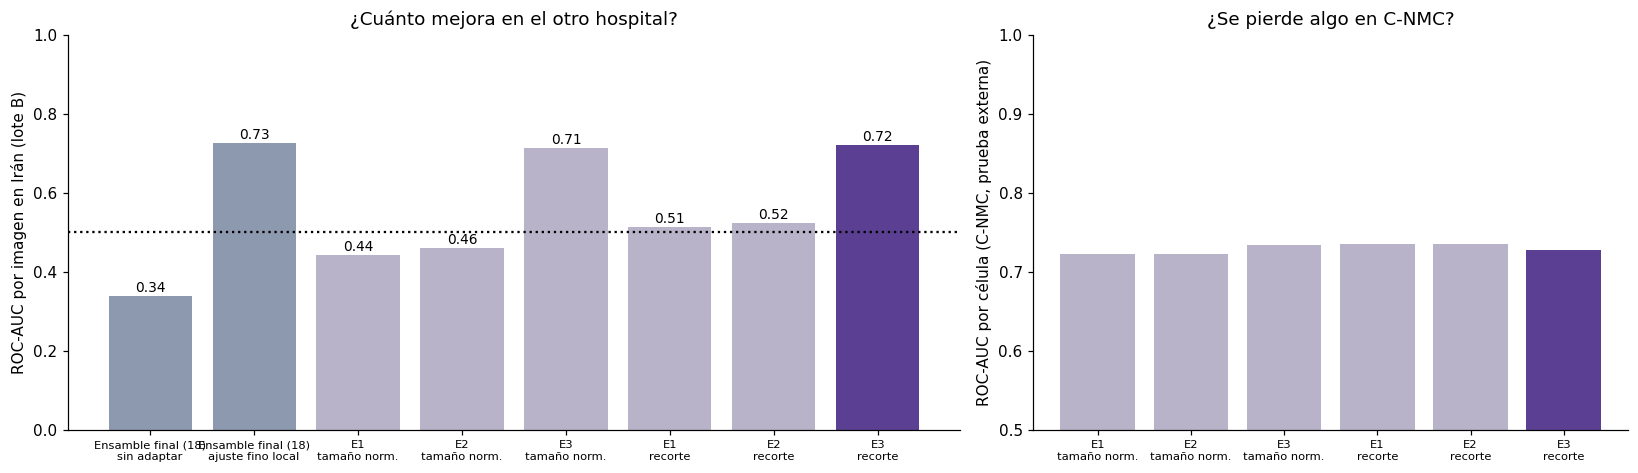


Aciertos por subtipo en Irán (lote B) con el mejor experimento:


,proporción
subtipo,
Benign,0.85
Early,0.87
Pre,0.96
Pro,0.07


Imágenes sin ningún leucocito detectado (reciben probabilidad 0): 311 de 1628


In [59]:
if HAS_IRAN:
    ref_rows = {}
    if "iran_tab" in globals() and FINAL in iran_tab.index:
        ref_rows["Ensamble final (18)\nsin adaptar"] = float(iran_tab.loc[FINAL, "AUC Irán sin adaptar"])
    if "sys2_table" in globals() and "C. Ajuste fino local (final)" in sys2_table.index:
        ref_rows["Ensamble final (18)\najuste fino local"] = float(sys2_table.loc["C. Ajuste fino local (final)", "ROC-AUC"])
    best_idx = dom["AUC val (lote A)"].idxmax()
    print("Mejor experimento según el lote A de validación:", best_idx)
    print(f"  → AUC en el lote B (Irán): {dom.loc[best_idx, 'AUC Irán (lote B)']:.3f} · "
          f"sensibilidad {dom.loc[best_idx, 'sensibilidad']:.2f} · especificidad {dom.loc[best_idx, 'especificidad']:.2f} · "
          f"sensibilidad en Pro-B {dom.loc[best_idx, 'sens. Pro-B']:.2f}")

    fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})
    names = [f"{e.split(' · ')[0]}\n{m.split()[0] if m.startswith('rec') else 'tamaño norm.'}" for (m, e) in dom.index]
    cols = ["#5B3F92" if i == best_idx else "#B9B3C9" for i in dom.index]
    vals = dom["AUC Irán (lote B)"].values
    allv = list(ref_rows.values()) + list(vals)
    allnames = list(ref_rows.keys()) + names
    allcols = ["#8d99ae"] * len(ref_rows) + cols
    bars = ax[0].bar(allnames, allv, color=allcols)
    for b_, v_ in zip(bars, allv):
        ax[0].text(b_.get_x() + b_.get_width() / 2, v_ + .01, f"{v_:.2f}", ha="center", fontsize=9)
    ax[0].axhline(0.5, color="k", ls=":"); ax[0].set(ylim=(0, 1), ylabel="ROC-AUC por imagen en Irán (lote B)",
                                                       title="¿Cuánto mejora en el otro hospital?")
    ax[0].tick_params(axis="x", labelsize=7.5)
    ax[1].bar(names, dom["AUC C-NMC (prueba)"].values, color=cols)
    ax[1].set(ylim=(0.5, 1), ylabel="ROC-AUC por célula (C-NMC, prueba externa)", title="¿Se pierde algo en C-NMC?")
    ax[1].tick_params(axis="x", labelsize=7.5)
    plt.tight_layout(); savefig("dominio_dinobloom"); plt.show()

    # Por subtipo en el lote B, para el mejor experimento (¿se detecta ya el subtipo Pro-B?)
    mode_best = [k for k, v in MODE_NAMES.items() if v == best_idx[0]][0]
    exp_best = best_idx[1].split(" · ")[0]
    pv_, pb_ = PROBS[(mode_best, exp_best)]
    sb_best = agg_scores(cells_b, imgs_b, pb_)
    thr_best = choose_thresholds(agg_scores(cells_a_va, imgs_a_va, pv_).label, agg_scores(cells_a_va, imgs_a_va, pv_).p_img)["Youden"]
    por_sub = sb_best.assign(acierto=((sb_best.p_img >= thr_best).astype(int) == sb_best.label)).groupby("subtipo").acierto.mean()
    print("\nAciertos por subtipo en Irán (lote B) con el mejor experimento:")
    display(por_sub.reindex(["Benign", "Early", "Pre", "Pro"]).rename("proporción").to_frame().round(2))
    print(f"Imágenes sin ningún leucocito detectado (reciben probabilidad 0): {int((imgs_b.n_leucocitos == 0).sum())} de {len(imgs_b)}")
else:
    print("Sin datos de Irán (sección 17 no se ejecutó): solo se muestra E1 en C-NMC.")
    display(dom.round(3))

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    19.3 Resultados de DinoBloom
</div>

| Experimento | AUC C-NMC (célula) | AUC Irán (lote B) |
|---|---|---|
| Ensamble final (sección 18), sin adaptar | 0,937 | 0,337 |
| Ensamble final, ajuste fino local | — | 0,727 |
| E1 · DinoBloom, solo C-NMC | 0,72–0,74 | 0,44–0,51 |
| E2 · + alineación sin etiquetas | 0,72–0,74 | 0,46–0,52 |
| E3 · + etiquetas locales | 0,73 | 0,71–0,72 (0,76 con la probabilidad media) |

1. **DinoBloom congelado no alcanza en C-NMC** (0,72–0,74 frente a 0,937): distinguir un blasto de una hematogona es una diferencia fina que una capa lineal sobre características genéricas de hematología no captura.
2. **Sin adaptar, deja de ordenar al revés** (de 0,34 a ~0,51), pero queda en el azar. La alineación sin etiquetas suma apenas ~0,01.
3. **Con etiquetas locales (E3) llega a 0,72**, lo mismo que el ajuste fino del ensamble (0,727), pero sin reentrenar la red.
4. **La pista importante:** en las tres versiones el subtipo **Pro-B casi no se clasifica bien (7%)**, mientras que Early (87%), Pre (96%) y sanos (85%) salen bien. Y **311 de 1.628 imágenes no tienen ningún leucocito detectado**: reciben probabilidad 0 y cuentan como "sanas". Eso pone un techo de ≈ 0,77 al AUC que **ningún clasificador puede superar** con este detector.

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    19.4 Experimentos complementarios (notebooks anexos)
</div>

Para no volver a correr todo el proyecto, los dos experimentos siguientes se hicieron en notebooks aparte, con **las mismas particiones** (los mismos pacientes de C-NMC y los mismos lotes A y B de Irán).

**A. `dinobloom_iran.ipynb`: DinoBloom con un detector que sí ve las células Pro-B.** El detector por croma encuentra los leucocitos por su color, con un umbral calculado en cada foto, y separa las células pegadas con *watershed*. Con él ya **ninguna imagen queda sin leucocitos** y el techo del AUC pasa de ≈ 0,77 a 1,0.

| Modelo (DinoBloom congelado, detector por croma) | AUC C-NMC | AUC Irán (lote B) |
|---|---|---|
| Solo C-NMC | 0,75 | 0,64 |
| + etiquetas del lote A de Irán | 0,76 | **0,997** |

El ajuste fino de los últimos bloques de DinoBloom llegó a 0,989 de AUC en la validación de C-NMC (el ensamble también está saturado ahí, 0,99+); su evaluación en la prueba no se completó. Entrenado solo con C-NMC, **empeoró en Irán a medida que aprendía** (validación del lote A: de 0,45 a 0,37).

**B. `verificacion_atajos_iran.ipynb`: ¿el 0,997 es real?** Entrenamos modelos que **no miran ninguna célula**, solo números de la foto completa, con el lote A, y los evaluamos en el lote B:

| Modelo sin mirar células | AUC Irán (lote B) |
|---|---|
| Solo el número de leucocitos | 0,60 |
| Solo la fracción de la foto con leucocitos | 0,62 |
| Solo el color medio de la foto (L, a, b) | **0,84** |
| Color medio y su variación | 0,87 |
| Los 8 números juntos | **0,89** |

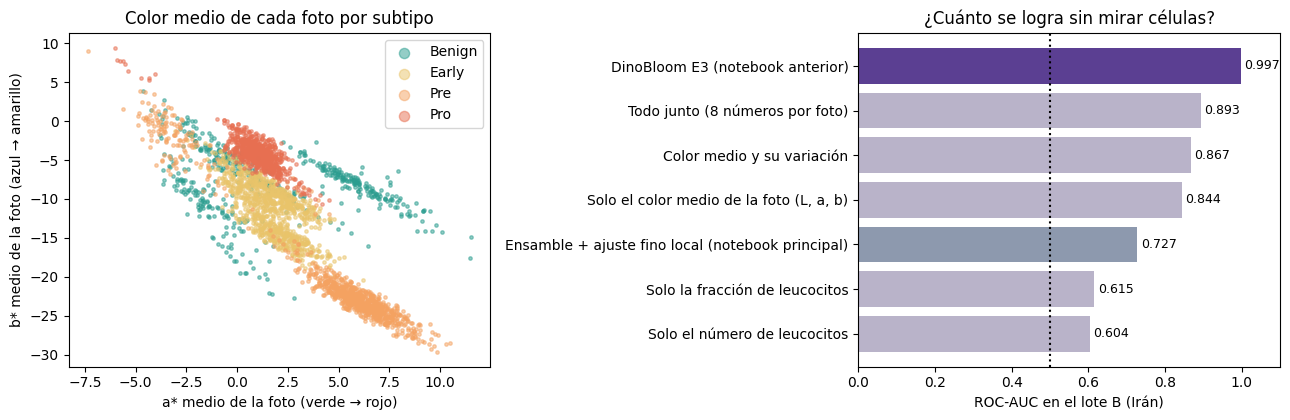

**Conclusión.** En el dataset de Irán, cada subtipo parece venir de láminas teñidas por separado (la gráfica de la izquierda separa los subtipos solo por el color medio de la foto), y no hay ID de paciente, así que el mismo paciente puede estar en el lote A y en el lote B. Con 8 números de color se llega a 0,89, así que **el 0,997 no demuestra que el modelo reconozca blastos**: puede estar reconociendo la lámina o al paciente. Es el mismo tipo de hallazgo que el atajo del tamaño en C-NMC.

<div style="margin: 20px 0 10px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h3 style="color: #3498db; margin: 0; display: inline-block; border-bottom: 3px solid #3498db; padding-bottom: 4px;">
    19.5 Qué nos quedamos de esta sección
</div>

- **El modelo final del proyecto sigue siendo el ensamble de 5 redes** (sección 18): es el mejor en C-NMC (0,937 frente a 0,75 de DinoBloom congelado) y su evaluación es la más confiable.
- **Sin datos locales, ningún modelo sirve en otro hospital**: 0,34 el ensamble y 0,64 DinoBloom en Irán.
- **El detector importa tanto como el clasificador**: YOLO, entrenado con pseudo-etiquetas violetas, perdía las células Pro-B.
- **Para validar en un hospital nuevo (fase 0 del plan)** hacen falta datos con **ID de paciente** y con **la misma tinción en sanos y enfermos**; si no, un modelo puede aprender la lámina en vez de la célula.

In [60]:
# Descarga todos los resultados en un .zip (figuras, métricas, modelos)
import shutil
zip_path = shutil.make_archive("/content/resultados_leucemia" if os.path.isdir("/content") else f"{OUT_DIR}_zip", "zip", OUT_DIR)
print("Archivo:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass

Archivo: /content/resultados_leucemia.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div style="text-align: center; margin: 30px 0 20px 0; font-family: system-ui, -apple-system, sans-serif;">
    <h2 style="color: #3498db; margin-bottom: 8px;">
        20. Referencias
    </h2>
</div>

**Sistema completo (sección 17)**
- Ghaderzadeh, M., Aria, M. et al. (2021). *Acute Lymphoblastic Leukemia (ALL) image dataset*. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/2175623
- Jocher, G. et al. Ultralytics YOLO11. https://docs.ultralytics.com
- Ravi, N. et al. (2024). SAM 2: Segment Anything in Images and Videos. Meta AI.
- Kouzehkanan, Z. et al. (2022). A large dataset of white blood cells containing cell locations and types (Raabin-WBC). *Scientific Reports*.
- BoneMarrowWSI-PediatricLeukemia (2025). Zenodo. https://doi.org/10.5281/zenodo.16995570

**Contexto clínico**
- Bonaventure, A. et al. (2017). Worldwide comparison of survival from childhood leukaemia for 1995–2009 (CONCORD-2). *The Lancet Haematology*. Resumen: https://ecancer.org/en/news/11440-global-inequalities-in-survival-for-childhood-leukaemia-persist-highlighting-need-for-better-care
- Organización Panamericana de la Salud (2023), análisis de cáncer infantil en América Latina y el Caribe, citado en: https://www.semana.com/salud/articulo/ninos-con-cancer-tienen-mas-probabilidad-de-morir-en-colombia-que-en-el-promedio-de-paises-de-sudamerica/202332/
- Instituto Nacional de Salud Pública de México (2021). *Leucemia en niños y adolescentes* (webinar CISP): https://insp.mx/assets/documents/webinars/2021/CISP_Leucemia.pdf
- UICC / OMS. Global Initiative for Childhood Cancer: https://uicc.org/what-we-do/advocacy/working-together/global-initiative-childhood-cancer

**Datos y métodos**
- Mourya, S., Kant, S., Kumar, P., Gupta, A. y Gupta, R. (2019). *ALL Challenge dataset of ISBI 2019 (C-NMC 2019)*. The Cancer Imaging Archive. https://doi.org/10.7937/tcia.2019.dc64i46r
- Gupta, R., Gehlot, S. y Gupta, A. (2022). C-NMC: B-lineage acute lymphoblastic leukaemia: A blood cancer dataset. *Medical Engineering & Physics*, 103.
- Prellberg, J. y Kramer, O. (2019). Acute Lymphoblastic Leukemia Classification from Microscopic Images using Convolutional Neural Networks. *ISBI 2019 C-NMC Challenge*.
- Tan, M. y Le, Q. (2019). EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks. *ICML*.
- Hu, J., Shen, L. y Sun, G. (2018). Squeeze-and-Excitation Networks. *CVPR*.
- Lin, T.-Y. et al. (2017). Focal Loss for Dense Object Detection. *ICCV*.
- Mondal, C. et al. (2021). Acute Lymphoblastic Leukemia Detection from Microscopic Images Using Weighted Ensemble of Convolutional Neural Networks. *arXiv:2105.03995*.
- Chollet, F. (2017). Xception: Deep Learning with Depthwise Separable Convolutions. *CVPR*.
- Liu, Z. et al. (2022). A ConvNet for the 2020s (ConvNeXt). *CVPR*.
- Müller, R., Kornblith, S. y Hinton, G. (2019). When Does Label Smoothing Help? *NeurIPS*.
- Ruifrok, A. C. y Johnston, D. A. (2001). Quantification of histochemical staining by color deconvolution. *Analytical and Quantitative Cytology and Histology*.
- Tellez, D. et al. (2018). Whole-slide mitosis detection in H&E breast histology using PHH3 as a reference to train distilled stain-invariant convolutional networks. *IEEE TMI*.
- Selvaraju, R. R. et al. (2017). Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization. *ICCV*.
- Loshchilov, I. y Hutter, F. (2019). Decoupled Weight Decay Regularization (AdamW). *ICLR*.
- Koch, V. et al. (2024). DinoBloom: A Foundation Model for Generalizable Cell Embeddings in Hematology. *MICCAI*. arXiv:2404.05022. Pesos: https://huggingface.co/1aurent/vit_base_patch14_224.dinobloom
- Li, Y., Wang, N., Shi, J., Hou, X. y Liu, J. (2018). Adaptive Batch Normalization for practical domain adaptation. *Pattern Recognition*.
- Sun, B. y Saenko, K. (2016). Deep CORAL: Correlation Alignment for Deep Domain Adaptation. *ECCV Workshops*.
- Retrieval-Augmented Vision Foundation Models for Robust Leukemia Cell Classification across Multiple Microscopy Datasets (2026). arXiv:2608.10657.